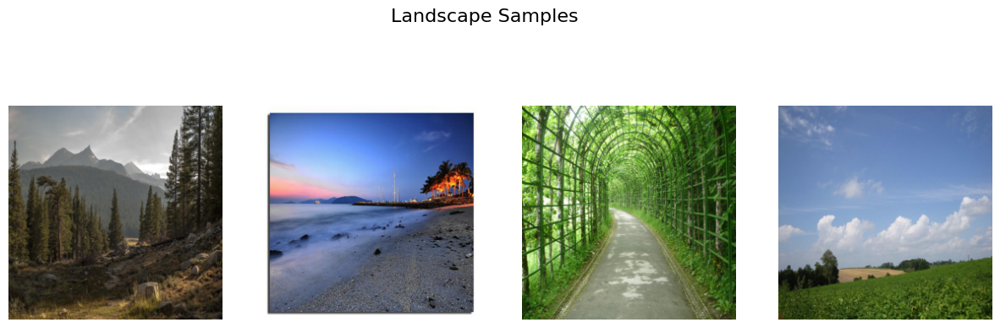

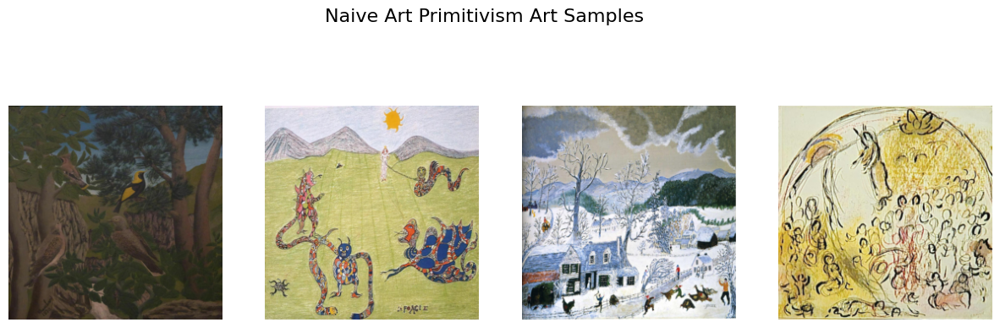

In [1]:
import os
from PIL import Image
import torch
from torchvision import transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

landscape_path = r"E:\Code\GAN\Land"
art_path = r"E:\Code\GAN\Art" 

IMG_SIZE = 256  
BATCH_SIZE = 4 

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), 
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)) 
])

class ArtDataset(torch.utils.data.Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_files = os.listdir(root_dir)

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.image_files[idx])
        image = Image.open(img_path).convert("RGB")  
        if self.transform:
            image = self.transform(image)
        return image

landscape_dataset = ArtDataset(landscape_path, transform=transform)
art_dataset = ArtDataset(art_path, transform=transform)

landscape_loader = torch.utils.data.DataLoader(landscape_dataset, batch_size=BATCH_SIZE, shuffle=True)
art_loader = torch.utils.data.DataLoader(art_dataset, batch_size=BATCH_SIZE, shuffle=True)

def visualize_samples(loader, title, num_images=4):
    images = next(iter(loader))
    plt.figure(figsize=(15, 5))
    for i in range(num_images):
        img = images[i].permute(1, 2, 0) * 0.5 + 0.5 
        plt.subplot(1, num_images, i + 1)
        plt.imshow(img)
        plt.axis("off")
    plt.suptitle(title, fontsize=16)
    plt.show()

visualize_samples(landscape_loader, "Landscape Samples")
visualize_samples(art_loader, "Naive Art Primitivism Art Samples")

In [ ]:
from torchvision import transforms
from torch.utils.data import DataLoader
import torch
import os
from PIL import Image

transform = transforms.Compose([
    transforms.Resize((256, 256)), 
    transforms.ToTensor(), 
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)), 
])

class ArtDataset(torch.utils.data.Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_files = os.listdir(root_dir)

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.image_files[idx])
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image

landscape_path = r"E:\Code\GAN\Land"
art_path = r"E:\Code\GAN\Pop" 
landscape_dataset = ArtDataset(landscape_path, transform=transform)
art_dataset = ArtDataset(art_path, transform=transform)

BATCH_SIZE = 4
landscape_loader = DataLoader(landscape_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
art_loader = DataLoader(art_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#print("Waiting for landscape batch...")
#landscape_batch = next(iter(landscape_loader)).to(device)  
#art_batch = next(iter(art_loader)).to(device) 

#print("Landscape Batch Shape:", landscape_batch.shape)
#print("Art Batch Shape:", art_batch.shape)


In [2]:
import torch
import torch.nn as nn

class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super(ResidualBlock, self).__init__()
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, stride=1, padding=1, bias=False),
            nn.InstanceNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, kernel_size=3, stride=1, padding=1, bias=False),
            nn.InstanceNorm2d(channels)
        )

    def forward(self, x):
        return x + self.block(x)

class ResNetGenerator(nn.Module):
    def __init__(self, input_channels=3, output_channels=3, num_residual_blocks=9):
        super(ResNetGenerator, self).__init__()

        self.initial = nn.Sequential(
            nn.Conv2d(input_channels, 64, kernel_size=7, stride=1, padding=3, bias=False),
            nn.InstanceNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.downsampling = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1, bias=False),
            nn.InstanceNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 256, kernel_size=3, stride=2, padding=1, bias=False),
            nn.InstanceNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.residual_blocks = nn.Sequential(*[ResidualBlock(256) for _ in range(num_residual_blocks)])

        self.upsampling = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=3, stride=2, padding=1, output_padding=1, bias=False),
            nn.InstanceNorm2d(128),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1, bias=False),
            nn.InstanceNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.output = nn.Sequential(
            nn.Conv2d(64, output_channels, kernel_size=7, stride=1, padding=3),
            nn.Tanh() 
        )

    def forward(self, x):
        x = self.initial(x)
        x = self.downsampling(x)
        x = self.residual_blocks(x)
        x = self.upsampling(x)
        return self.output(x)


In [3]:
class PatchGANDiscriminator(nn.Module):
    def __init__(self, input_channels=3):
        super(PatchGANDiscriminator, self).__init__()

        def discriminator_block(in_channels, out_channels, stride):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=4, stride=stride, padding=1),
                nn.LeakyReLU(0.2, inplace=True)
            )

        self.model = nn.Sequential(
            discriminator_block(input_channels, 64, stride=2),  
            discriminator_block(64, 128, stride=2), 
            nn.InstanceNorm2d(128),
            discriminator_block(128, 256, stride=2),  
            nn.InstanceNorm2d(256),
            discriminator_block(256, 512, stride=1), 
            nn.InstanceNorm2d(512),
            nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=1) 
        )

    def forward(self, x):
        return self.model(x)


In [4]:
G_X_to_Y = ResNetGenerator().to(device)  # Landscape -> Naive Art Primitivism
G_Y_to_X = ResNetGenerator().to(device)  # Naive Art Primitivism -> Landscape

D_X = PatchGANDiscriminator().to(device)  # Discriminator for Landscapes
D_Y = PatchGANDiscriminator().to(device)  # Discriminator for Naive Art Primitivism

print(f"Generator G_X_to_Y: {G_X_to_Y}")
print(f"Generator G_Y_to_X: {G_Y_to_X}")
print(f"Discriminator D_X: {D_X}")
print(f"Discriminator D_Y: {D_Y}")


Generator G_X_to_Y: ResNetGenerator(
  (initial): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), bias=False)
    (1): InstanceNorm2d(64, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (2): ReLU(inplace=True)
  )
  (downsampling): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): InstanceNorm2d(128, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (2): ReLU(inplace=True)
    (3): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (4): InstanceNorm2d(256, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (5): ReLU(inplace=True)
  )
  (residual_blocks): Sequential(
    (0): ResidualBlock(
      (block): Sequential(
        (0): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): InstanceNorm2d(256, eps=1e-05, momentum=0.1, affine=False, track_running_stats=

In [5]:
adversarial_loss = nn.MSELoss().to(device) 
cycle_consistency_loss = nn.L1Loss().to(device)
identity_loss = nn.L1Loss().to(device)

In [6]:
lr = 2e-4

optimizer_G = torch.optim.Adam(
    list(G_X_to_Y.parameters()) + list(G_Y_to_X.parameters()), lr=lr, betas=(0.5, 0.999)
)
optimizer_D_X = torch.optim.Adam(D_X.parameters(), lr=lr, betas=(0.5, 0.999))
optimizer_D_Y = torch.optim.Adam(D_Y.parameters(), lr=lr, betas=(0.5, 0.999))


In [ ]:
pip install tqdm tensorboard

In [7]:
num_epochs = 50  
lambda_cycle = 10  
lambda_identity = 0.5 

In [55]:
def save_model(epoch, G_X_to_Y, G_Y_to_X, D_X, D_Y, save_dir=r"E:\Code\GAN\model\art2"):
    os.makedirs(save_dir, exist_ok=True)
    torch.save(G_X_to_Y.state_dict(), f"{save_dir}/G_X_to_Y_epoch_{epoch}.pth")
    torch.save(G_Y_to_X.state_dict(), f"{save_dir}/G_Y_to_X_epoch_{epoch}.pth")
    torch.save(D_X.state_dict(), f"{save_dir}/D_X_epoch_{epoch}.pth")
    torch.save(D_Y.state_dict(), f"{save_dir}/D_Y_epoch_{epoch}.pth")
    print(f"Model parameters saved for epoch {epoch}.")

In [65]:
def load_model(epoch, G_X_to_Y, G_Y_to_X, D_X, D_Y, save_dir=r"E:\Code\GAN\model\cub"):
    G_X_to_Y.load_state_dict(torch.load(f"{save_dir}/G_X_to_Y_epoch_{epoch}_pop.pth"))
    G_Y_to_X.load_state_dict(torch.load(f"{save_dir}/G_Y_to_X_epoch_{epoch}_pop.pth"))
    D_X.load_state_dict(torch.load(f"{save_dir}/D_X_epoch_{epoch}_pop.pth"))
    D_Y.load_state_dict(torch.load(f"{save_dir}/D_Y_epoch_{epoch}_pop.pth"))
    print(f"Model parameters loaded for epoch {epoch}.")

In [10]:
import torchvision.utils as vutils
import matplotlib.pyplot as plt

def visualize_progress(generator, input_images, epoch, save_dir=r"E:\Code\GAN\output\art2", show=True):
    os.makedirs(save_dir, exist_ok=True)

    generator.eval() 
    with torch.no_grad():
        input_images = input_images.to(device)
        generated_images = generator(input_images)

    comparison = torch.cat((input_images.cpu(), generated_images.cpu()), dim=3)  # Concatenate along width
    vutils.save_image(comparison, f"{save_dir}/epoch_{epoch}_comparison.png", normalize=True, padding=10)

    if show:
        grid = vutils.make_grid(comparison, normalize=True, nrow=1, padding=10)
        plt.figure(figsize=(16, 8))
        plt.imshow(grid.permute(1, 2, 0)) 
        plt.axis("off")
        plt.title(f"Epoch {epoch}: Photo -> Painting")
        plt.show()

In [11]:
def save_generated_images(generator, input_photos, epoch, save_dir=r"E:\Code\GAN\output\ren", num_samples=4):
    os.makedirs(save_dir, exist_ok=True)
    generator.eval()  
    
    with torch.no_grad():
        input_photos = input_photos[:num_samples].to(device)
        generated_images = generator(input_photos)

    unnormalize = transforms.Normalize(mean=[-0.5 / 0.5, -0.5 / 0.5, -0.5 / 0.5], std=[1 / 0.5, 1 / 0.5, 1 / 0.5])
    input_photos = [unnormalize(img).clamp(0, 1) for img in input_photos]
    generated_images = [unnormalize(img).clamp(0, 1) for img in generated_images]

    for i, (input_img, gen_img) in enumerate(zip(input_photos, generated_images)):
        input_img = transforms.ToPILImage()(input_img.cpu())
        gen_img = transforms.ToPILImage()(gen_img.cpu())

        input_img.save(f"{save_dir}/real_photo_epoch_{epoch}_{i+1}.jpg")
        gen_img.save(f"{save_dir}/painting_epoch_{epoch}_{i+1}.jpg")
    print(f"Generated images saved for epoch {epoch} in {save_dir}.")


Epoch [1/50]


Epoch [1/50]: 100%|██████████| 169/169 [02:50<00:00,  1.01s/it, Cycle_Loss=0.607, D_X_Loss=0.237, D_Y_Loss=0.214, Generator_Loss=7.08, Identity_Loss=0.588]


Model parameters saved for epoch 1.


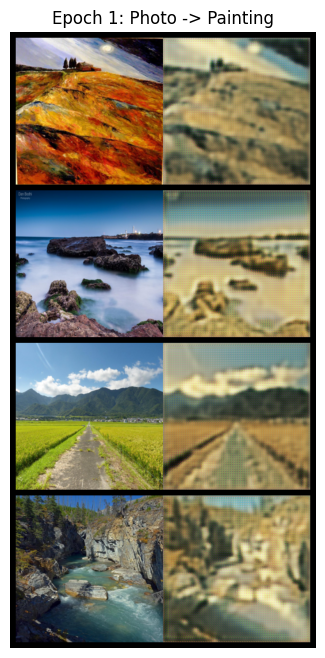

Epoch [1/50] Completed
  Generator Loss: 7.6691
  Cycle Consistency Loss: 0.6094
  Identity Loss: 0.6003
  Discriminator X Loss: 0.4187
  Discriminator Y Loss: 0.4554
Epoch [2/50]


Epoch [2/50]: 100%|██████████| 169/169 [02:45<00:00,  1.02it/s, Cycle_Loss=0.436, D_X_Loss=0.239, D_Y_Loss=0.19, Generator_Loss=5.27, Identity_Loss=0.431] 


Model parameters saved for epoch 2.


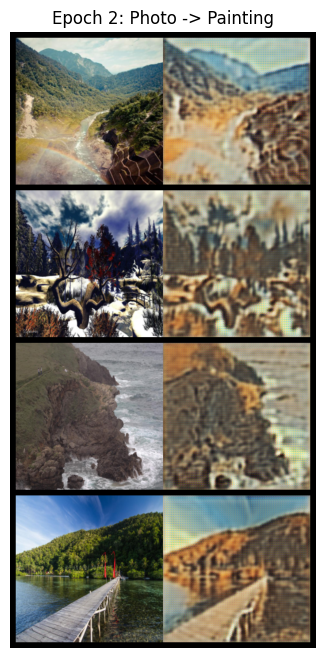

Epoch [2/50] Completed
  Generator Loss: 6.0490
  Cycle Consistency Loss: 0.4985
  Identity Loss: 0.4928
  Discriminator X Loss: 0.2477
  Discriminator Y Loss: 0.2611
Epoch [3/50]


Epoch [3/50]: 100%|██████████| 169/169 [02:45<00:00,  1.02it/s, Cycle_Loss=0.528, D_X_Loss=0.205, D_Y_Loss=0.288, Generator_Loss=6.37, Identity_Loss=0.466]


Model parameters saved for epoch 3.


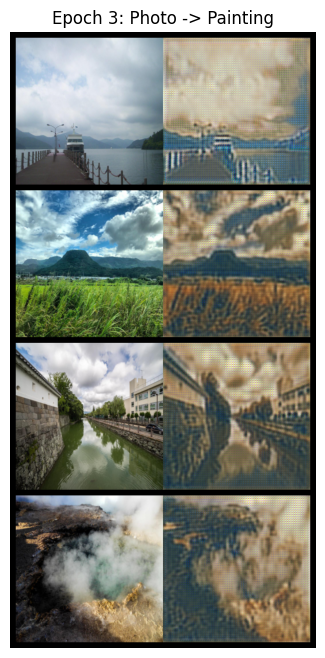

Epoch [3/50] Completed
  Generator Loss: 5.5808
  Cycle Consistency Loss: 0.4557
  Identity Loss: 0.4496
  Discriminator X Loss: 0.2158
  Discriminator Y Loss: 0.2326
Epoch [4/50]


Epoch [4/50]: 100%|██████████| 169/169 [02:44<00:00,  1.03it/s, Cycle_Loss=0.438, D_X_Loss=0.454, D_Y_Loss=0.219, Generator_Loss=5.79, Identity_Loss=0.402]


Model parameters saved for epoch 4.


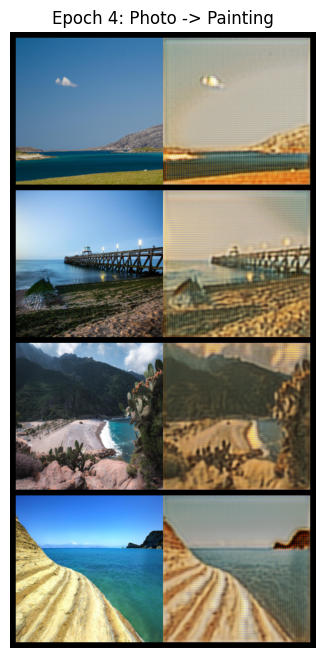

Epoch [4/50] Completed
  Generator Loss: 6.4793
  Cycle Consistency Loss: 0.4590
  Identity Loss: 0.4559
  Discriminator X Loss: 0.7883
  Discriminator Y Loss: 0.5019
Epoch [5/50]


Epoch [5/50]: 100%|██████████| 169/169 [02:43<00:00,  1.03it/s, Cycle_Loss=0.292, D_X_Loss=0.283, D_Y_Loss=0.211, Generator_Loss=3.92, Identity_Loss=0.338]


Model parameters saved for epoch 5.


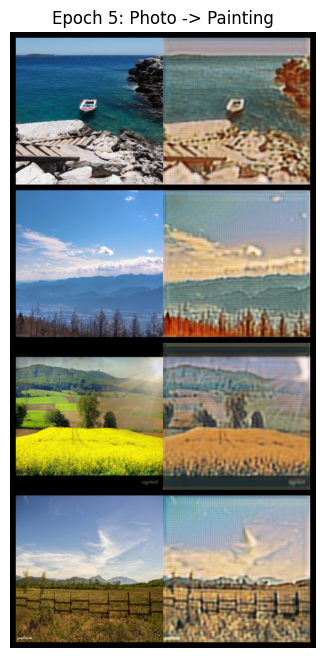

Epoch [5/50] Completed
  Generator Loss: 5.3464
  Cycle Consistency Loss: 0.4150
  Identity Loss: 0.4179
  Discriminator X Loss: 0.3570
  Discriminator Y Loss: 0.2328
Epoch [6/50]


Epoch [6/50]: 100%|██████████| 169/169 [02:43<00:00,  1.03it/s, Cycle_Loss=0.311, D_X_Loss=0.263, D_Y_Loss=0.244, Generator_Loss=4.04, Identity_Loss=0.319]


Model parameters saved for epoch 6.


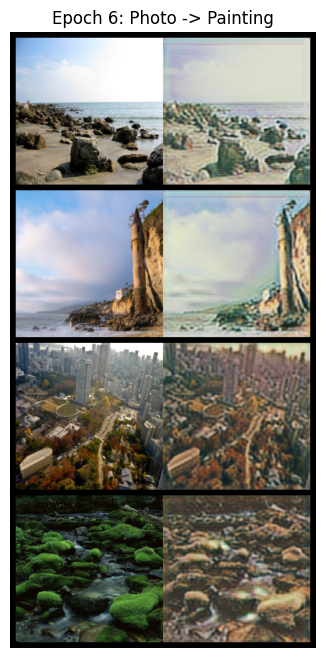

Epoch [6/50] Completed
  Generator Loss: 4.7718
  Cycle Consistency Loss: 0.3848
  Identity Loss: 0.4011
  Discriminator X Loss: 0.2739
  Discriminator Y Loss: 0.2319
Epoch [7/50]


Epoch [7/50]: 100%|██████████| 169/169 [02:43<00:00,  1.03it/s, Cycle_Loss=0.392, D_X_Loss=0.264, D_Y_Loss=0.33, Generator_Loss=4.7, Identity_Loss=0.394]  


Model parameters saved for epoch 7.


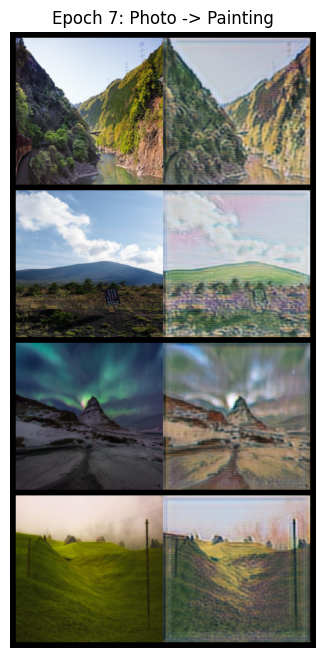

Epoch [7/50] Completed
  Generator Loss: 4.5954
  Cycle Consistency Loss: 0.3680
  Identity Loss: 0.3845
  Discriminator X Loss: 0.2573
  Discriminator Y Loss: 0.2262
Epoch [8/50]


Epoch [8/50]: 100%|██████████| 169/169 [02:43<00:00,  1.04it/s, Cycle_Loss=0.337, D_X_Loss=0.2, D_Y_Loss=0.471, Generator_Loss=4.69, Identity_Loss=0.433]  


Model parameters saved for epoch 8.


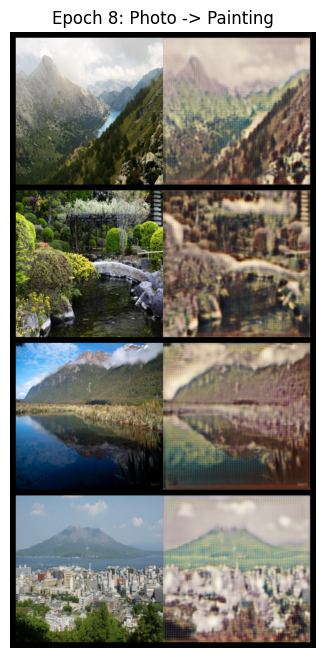

Epoch [8/50] Completed
  Generator Loss: 5.0867
  Cycle Consistency Loss: 0.3716
  Identity Loss: 0.3920
  Discriminator X Loss: 0.2465
  Discriminator Y Loss: 0.6363
Epoch [9/50]


Epoch [9/50]: 100%|██████████| 169/169 [02:43<00:00,  1.04it/s, Cycle_Loss=0.315, D_X_Loss=0.222, D_Y_Loss=0.243, Generator_Loss=3.98, Identity_Loss=0.405]


Model parameters saved for epoch 9.


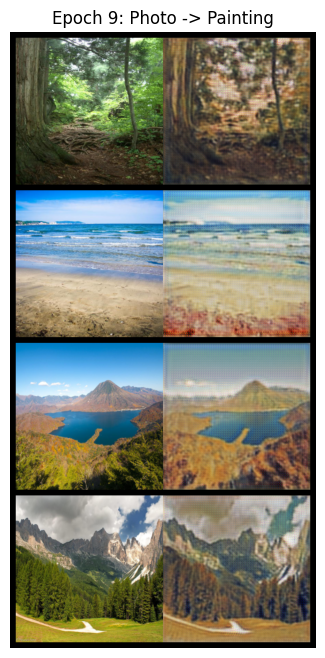

Epoch [9/50] Completed
  Generator Loss: 4.5245
  Cycle Consistency Loss: 0.3519
  Identity Loss: 0.3702
  Discriminator X Loss: 0.2348
  Discriminator Y Loss: 0.3099
Epoch [10/50]


Epoch [10/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.293, D_X_Loss=0.179, D_Y_Loss=0.222, Generator_Loss=3.74, Identity_Loss=0.315]


Model parameters saved for epoch 10.


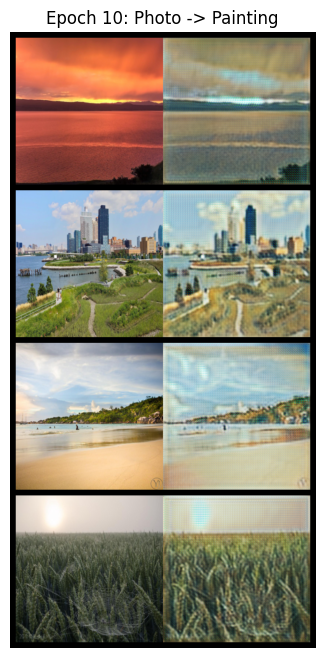

Epoch [10/50] Completed
  Generator Loss: 4.1417
  Cycle Consistency Loss: 0.3281
  Identity Loss: 0.3481
  Discriminator X Loss: 0.2494
  Discriminator Y Loss: 0.2448
Epoch [11/50]


Epoch [11/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.331, D_X_Loss=0.133, D_Y_Loss=0.227, Generator_Loss=4.22, Identity_Loss=0.362]


Model parameters saved for epoch 11.


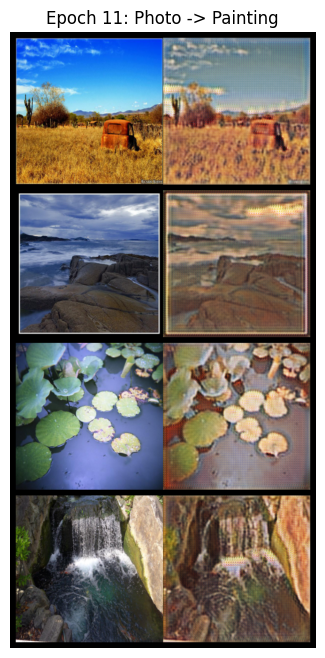

Epoch [11/50] Completed
  Generator Loss: 4.0610
  Cycle Consistency Loss: 0.3192
  Identity Loss: 0.3435
  Discriminator X Loss: 0.2173
  Discriminator Y Loss: 0.2392
Epoch [12/50]


Epoch [12/50]: 100%|██████████| 169/169 [02:43<00:00,  1.04it/s, Cycle_Loss=0.306, D_X_Loss=0.223, D_Y_Loss=0.183, Generator_Loss=3.95, Identity_Loss=0.391]


Model parameters saved for epoch 12.


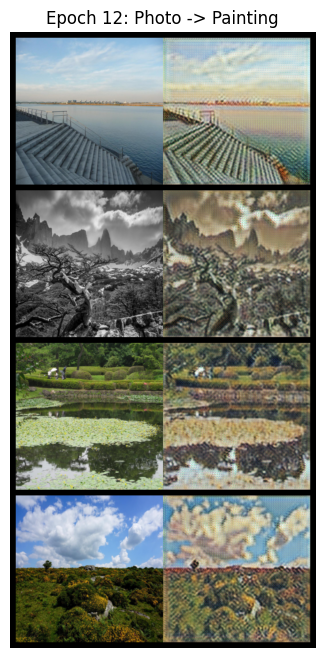

Epoch [12/50] Completed
  Generator Loss: 4.1178
  Cycle Consistency Loss: 0.3123
  Identity Loss: 0.3355
  Discriminator X Loss: 0.3503
  Discriminator Y Loss: 0.2310
Epoch [13/50]


Epoch [13/50]: 100%|██████████| 169/169 [02:55<00:00,  1.04s/it, Cycle_Loss=0.351, D_X_Loss=0.187, D_Y_Loss=0.327, Generator_Loss=4.56, Identity_Loss=0.348]


Model parameters saved for epoch 13.


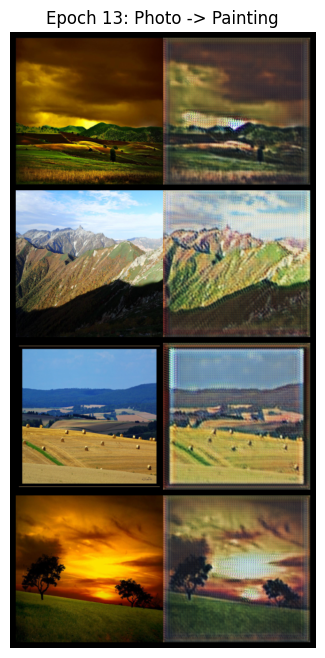

Epoch [13/50] Completed
  Generator Loss: 4.0722
  Cycle Consistency Loss: 0.3161
  Identity Loss: 0.3451
  Discriminator X Loss: 0.2028
  Discriminator Y Loss: 0.2348
Epoch [14/50]


Epoch [14/50]: 100%|██████████| 169/169 [02:58<00:00,  1.05s/it, Cycle_Loss=0.311, D_X_Loss=0.333, D_Y_Loss=0.176, Generator_Loss=3.93, Identity_Loss=0.389]


Model parameters saved for epoch 14.


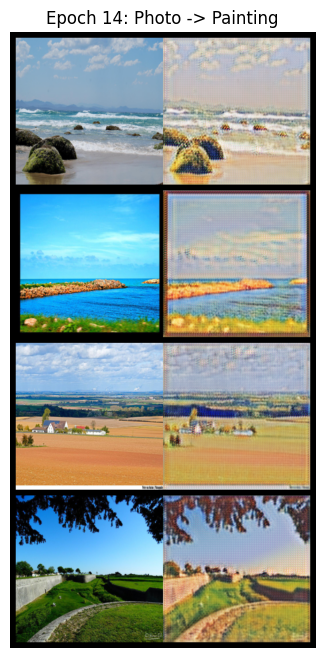

Epoch [14/50] Completed
  Generator Loss: 4.0471
  Cycle Consistency Loss: 0.3104
  Identity Loss: 0.3410
  Discriminator X Loss: 0.1927
  Discriminator Y Loss: 0.2243
Epoch [15/50]


Epoch [15/50]: 100%|██████████| 169/169 [02:57<00:00,  1.05s/it, Cycle_Loss=0.254, D_X_Loss=0.26, D_Y_Loss=0.249, Generator_Loss=3.39, Identity_Loss=0.301] 


Model parameters saved for epoch 15.


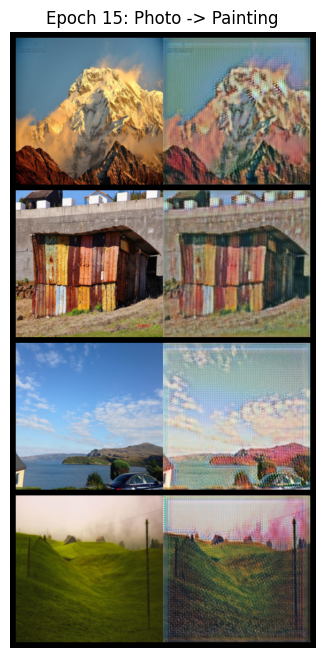

Epoch [15/50] Completed
  Generator Loss: 4.1174
  Cycle Consistency Loss: 0.3114
  Identity Loss: 0.3417
  Discriminator X Loss: 0.2679
  Discriminator Y Loss: 0.2221
Epoch [16/50]


Epoch [16/50]: 100%|██████████| 169/169 [02:43<00:00,  1.03it/s, Cycle_Loss=0.314, D_X_Loss=0.199, D_Y_Loss=0.293, Generator_Loss=4.3, Identity_Loss=0.315] 


Model parameters saved for epoch 16.


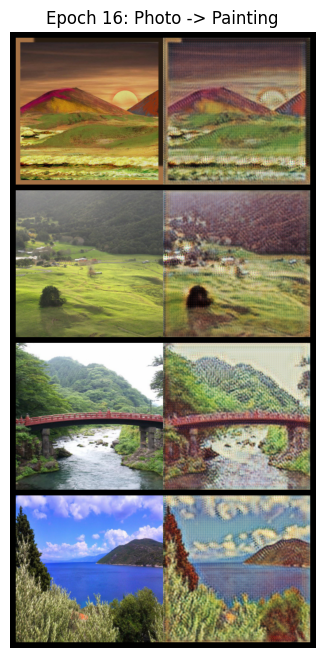

Epoch [16/50] Completed
  Generator Loss: 3.9274
  Cycle Consistency Loss: 0.3005
  Identity Loss: 0.3352
  Discriminator X Loss: 0.1948
  Discriminator Y Loss: 0.2219
Epoch [17/50]


Epoch [17/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.304, D_X_Loss=0.194, D_Y_Loss=0.298, Generator_Loss=3.81, Identity_Loss=0.331]


Model parameters saved for epoch 17.


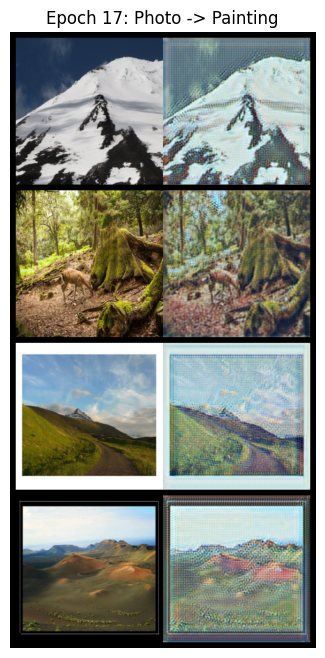

Epoch [17/50] Completed
  Generator Loss: 3.9788
  Cycle Consistency Loss: 0.3041
  Identity Loss: 0.3367
  Discriminator X Loss: 0.1995
  Discriminator Y Loss: 0.2271
Epoch [18/50]


Epoch [18/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.349, D_X_Loss=0.188, D_Y_Loss=0.148, Generator_Loss=4.52, Identity_Loss=0.366] 


Model parameters saved for epoch 18.


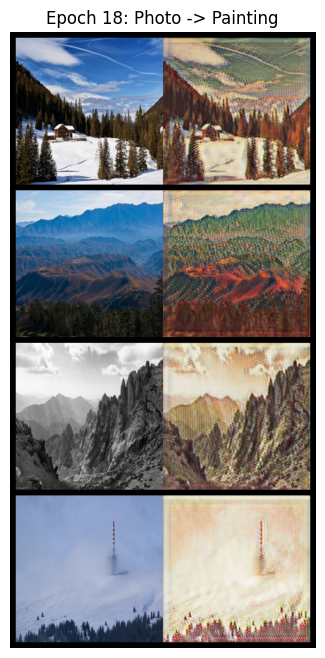

Epoch [18/50] Completed
  Generator Loss: 3.9539
  Cycle Consistency Loss: 0.3014
  Identity Loss: 0.3382
  Discriminator X Loss: 0.1993
  Discriminator Y Loss: 0.2197
Epoch [19/50]


Epoch [19/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.3, D_X_Loss=0.175, D_Y_Loss=0.481, Generator_Loss=4.11, Identity_Loss=0.296]   


Model parameters saved for epoch 19.


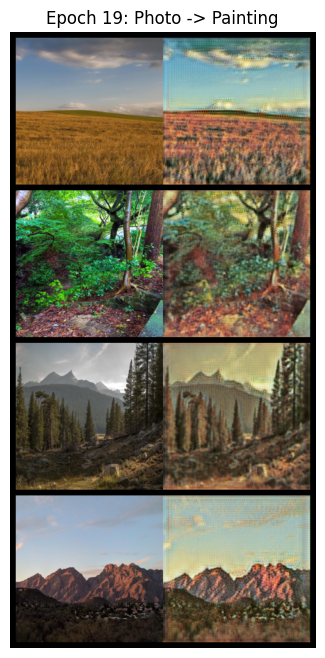

Epoch [19/50] Completed
  Generator Loss: 3.8481
  Cycle Consistency Loss: 0.2899
  Identity Loss: 0.3301
  Discriminator X Loss: 0.2079
  Discriminator Y Loss: 0.2223
Epoch [20/50]


Epoch [20/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.356, D_X_Loss=0.206, D_Y_Loss=0.182, Generator_Loss=4.55, Identity_Loss=0.356]


Model parameters saved for epoch 20.


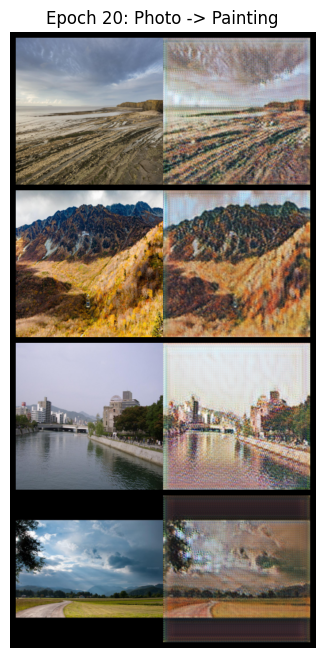

Epoch [20/50] Completed
  Generator Loss: 3.8694
  Cycle Consistency Loss: 0.2914
  Identity Loss: 0.3309
  Discriminator X Loss: 0.2105
  Discriminator Y Loss: 0.2204
Epoch [21/50]


Epoch [21/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.32, D_X_Loss=0.154, D_Y_Loss=0.157, Generator_Loss=4.27, Identity_Loss=0.353] 


Model parameters saved for epoch 21.


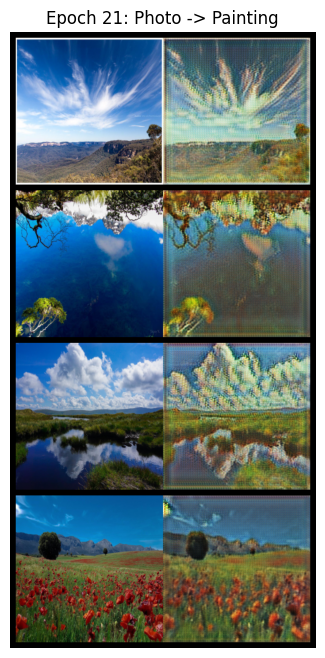

Epoch [21/50] Completed
  Generator Loss: 3.8324
  Cycle Consistency Loss: 0.2887
  Identity Loss: 0.3337
  Discriminator X Loss: 0.2082
  Discriminator Y Loss: 0.2157
Epoch [22/50]


Epoch [22/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.245, D_X_Loss=0.244, D_Y_Loss=0.218, Generator_Loss=3.44, Identity_Loss=0.254]


Model parameters saved for epoch 22.


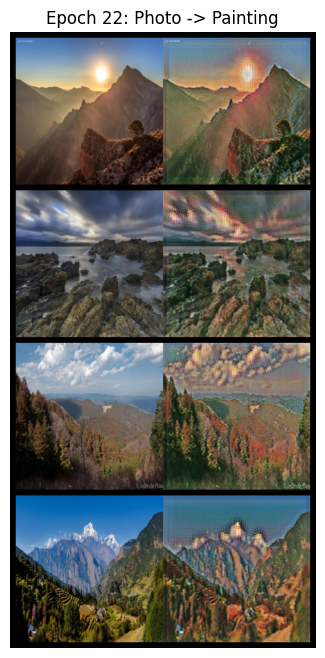

Epoch [22/50] Completed
  Generator Loss: 4.7956
  Cycle Consistency Loss: 0.3190
  Identity Loss: 0.3449
  Discriminator X Loss: 0.9073
  Discriminator Y Loss: 0.2198
Epoch [23/50]


Epoch [23/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.254, D_X_Loss=0.27, D_Y_Loss=0.181, Generator_Loss=3.41, Identity_Loss=0.283] 


Model parameters saved for epoch 23.


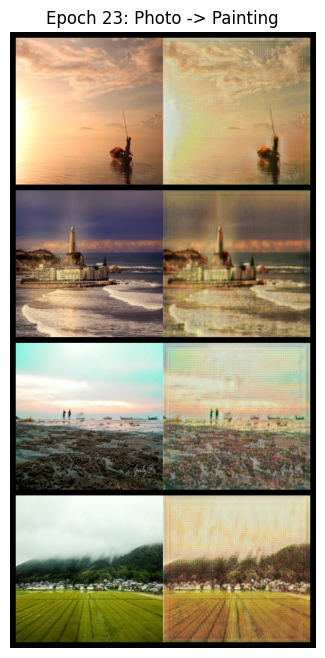

Epoch [23/50] Completed
  Generator Loss: 3.5954
  Cycle Consistency Loss: 0.2732
  Identity Loss: 0.3145
  Discriminator X Loss: 0.2620
  Discriminator Y Loss: 0.2172
Epoch [24/50]


Epoch [24/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.305, D_X_Loss=0.269, D_Y_Loss=0.161, Generator_Loss=4.06, Identity_Loss=0.369]


Model parameters saved for epoch 24.


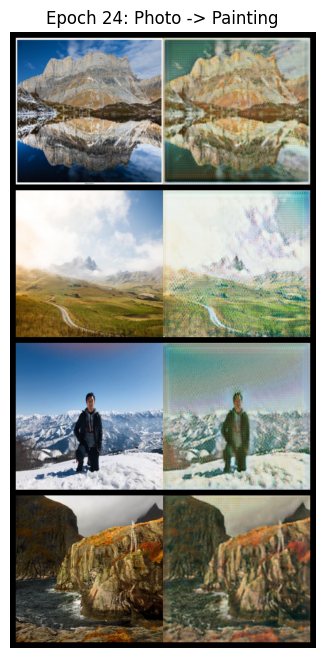

Epoch [24/50] Completed
  Generator Loss: 3.5425
  Cycle Consistency Loss: 0.2653
  Identity Loss: 0.3087
  Discriminator X Loss: 0.2471
  Discriminator Y Loss: 0.2073
Epoch [25/50]


Epoch [25/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.351, D_X_Loss=0.2, D_Y_Loss=0.163, Generator_Loss=4.61, Identity_Loss=0.419]  


Model parameters saved for epoch 25.


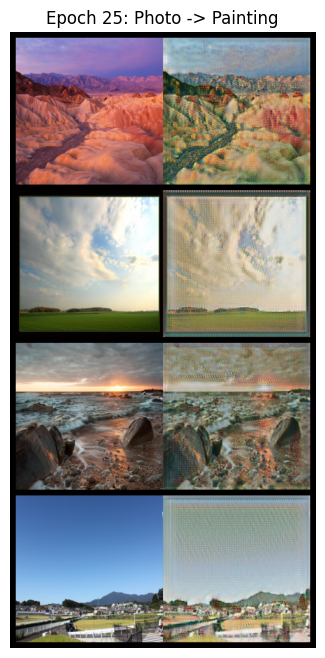

Epoch [25/50] Completed
  Generator Loss: 3.5697
  Cycle Consistency Loss: 0.2661
  Identity Loss: 0.3111
  Discriminator X Loss: 0.2390
  Discriminator Y Loss: 0.2091
Epoch [26/50]


Epoch [26/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.247, D_X_Loss=0.191, D_Y_Loss=0.246, Generator_Loss=3.25, Identity_Loss=0.252]


Model parameters saved for epoch 26.


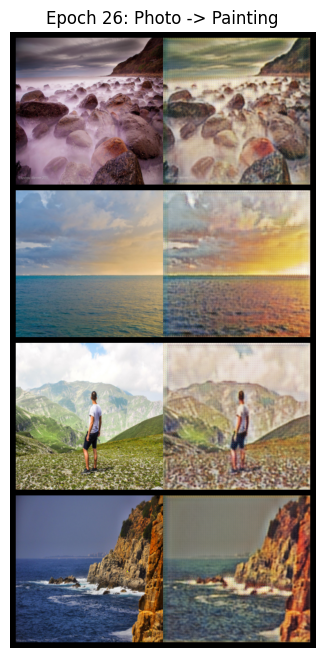

Epoch [26/50] Completed
  Generator Loss: 4.4392
  Cycle Consistency Loss: 0.2911
  Identity Loss: 0.3204
  Discriminator X Loss: 0.2403
  Discriminator Y Loss: 0.8839
Epoch [27/50]


Epoch [27/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.277, D_X_Loss=0.188, D_Y_Loss=0.239, Generator_Loss=3.6, Identity_Loss=0.307] 


Model parameters saved for epoch 27.


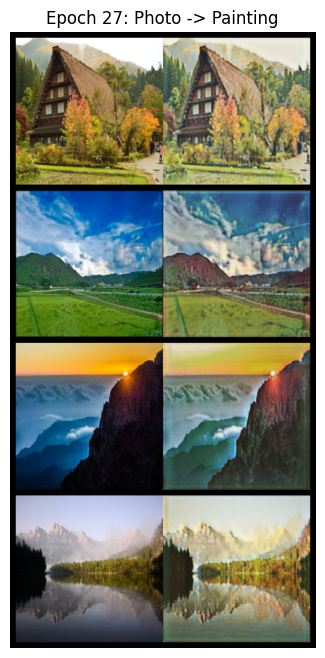

Epoch [27/50] Completed
  Generator Loss: 3.3369
  Cycle Consistency Loss: 0.2547
  Identity Loss: 0.2970
  Discriminator X Loss: 0.2255
  Discriminator Y Loss: 0.2452
Epoch [28/50]


Epoch [28/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.201, D_X_Loss=0.164, D_Y_Loss=0.203, Generator_Loss=2.89, Identity_Loss=0.264]


Model parameters saved for epoch 28.


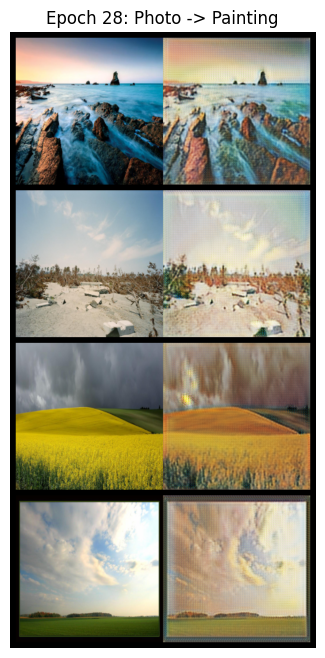

Epoch [28/50] Completed
  Generator Loss: 3.2836
  Cycle Consistency Loss: 0.2503
  Identity Loss: 0.2961
  Discriminator X Loss: 0.2218
  Discriminator Y Loss: 0.2381
Epoch [29/50]


Epoch [29/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.282, D_X_Loss=0.218, D_Y_Loss=0.24, Generator_Loss=3.67, Identity_Loss=0.318] 


Model parameters saved for epoch 29.


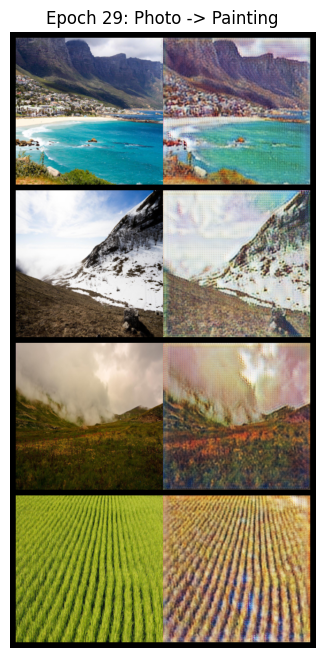

Epoch [29/50] Completed
  Generator Loss: 3.2250
  Cycle Consistency Loss: 0.2431
  Identity Loss: 0.2942
  Discriminator X Loss: 0.2251
  Discriminator Y Loss: 0.2329
Epoch [30/50]


Epoch [30/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.283, D_X_Loss=0.171, D_Y_Loss=0.233, Generator_Loss=3.64, Identity_Loss=0.317]


Model parameters saved for epoch 30.


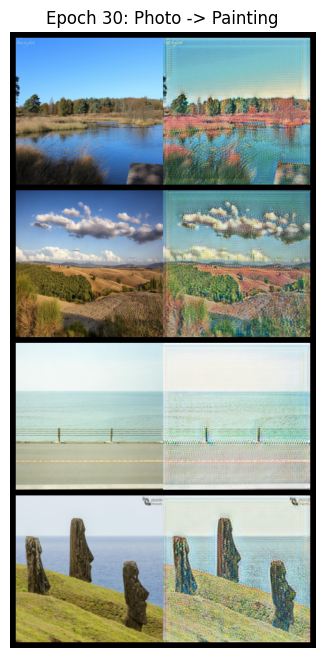

Epoch [30/50] Completed
  Generator Loss: 3.2388
  Cycle Consistency Loss: 0.2430
  Identity Loss: 0.2985
  Discriminator X Loss: 0.2194
  Discriminator Y Loss: 0.2314
Epoch [31/50]


Epoch [31/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.24, D_X_Loss=0.199, D_Y_Loss=0.212, Generator_Loss=3.34, Identity_Loss=0.335] 


Model parameters saved for epoch 31.


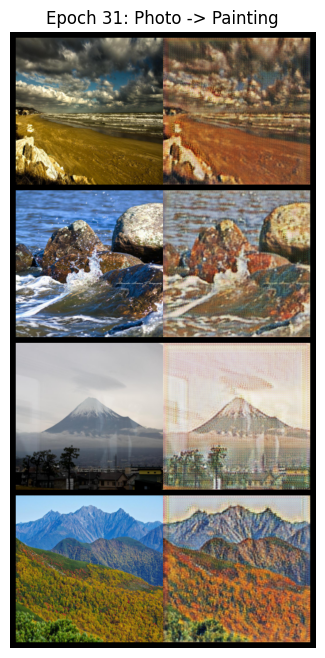

Epoch [31/50] Completed
  Generator Loss: 3.2486
  Cycle Consistency Loss: 0.2408
  Identity Loss: 0.3001
  Discriminator X Loss: 0.2244
  Discriminator Y Loss: 0.2282
Epoch [32/50]


Epoch [32/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.213, D_X_Loss=0.224, D_Y_Loss=0.239, Generator_Loss=3.03, Identity_Loss=0.275]


Model parameters saved for epoch 32.


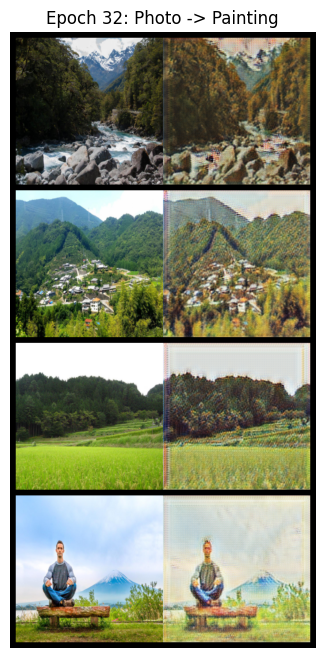

Epoch [32/50] Completed
  Generator Loss: 3.2982
  Cycle Consistency Loss: 0.2447
  Identity Loss: 0.3014
  Discriminator X Loss: 0.2108
  Discriminator Y Loss: 0.2270
Epoch [33/50]


Epoch [33/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.208, D_X_Loss=0.291, D_Y_Loss=0.174, Generator_Loss=2.93, Identity_Loss=0.265]


Model parameters saved for epoch 33.


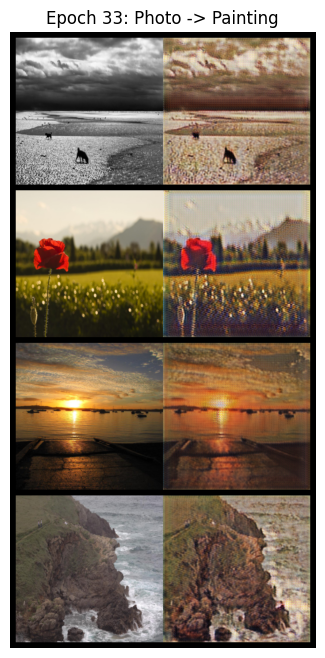

Epoch [33/50] Completed
  Generator Loss: 3.4722
  Cycle Consistency Loss: 0.2418
  Identity Loss: 0.2986
  Discriminator X Loss: 0.4655
  Discriminator Y Loss: 0.2219
Epoch [34/50]


Epoch [34/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.232, D_X_Loss=0.299, D_Y_Loss=0.252, Generator_Loss=3.02, Identity_Loss=0.319]


Model parameters saved for epoch 34.


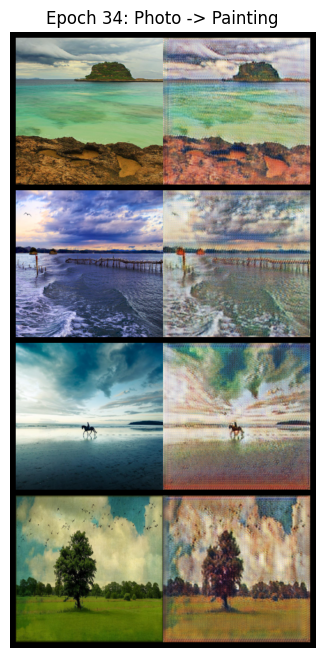

Epoch [34/50] Completed
  Generator Loss: 3.2241
  Cycle Consistency Loss: 0.2376
  Identity Loss: 0.2976
  Discriminator X Loss: 0.2274
  Discriminator Y Loss: 0.2228
Epoch [35/50]


Epoch [35/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.257, D_X_Loss=0.293, D_Y_Loss=0.224, Generator_Loss=3.44, Identity_Loss=0.289]


Model parameters saved for epoch 35.


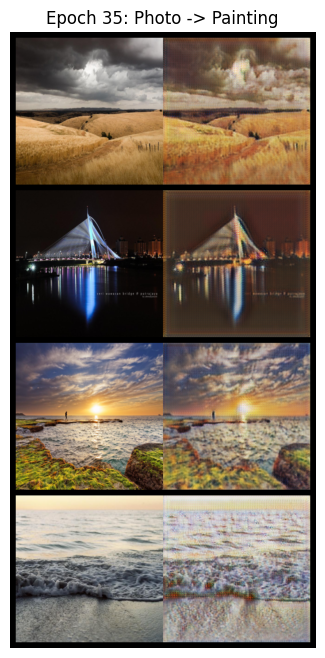

Epoch [35/50] Completed
  Generator Loss: 3.2455
  Cycle Consistency Loss: 0.2381
  Identity Loss: 0.3019
  Discriminator X Loss: 0.2183
  Discriminator Y Loss: 0.2173
Epoch [36/50]


Epoch [36/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.265, D_X_Loss=0.0916, D_Y_Loss=0.141, Generator_Loss=3.71, Identity_Loss=0.276]


Model parameters saved for epoch 36.


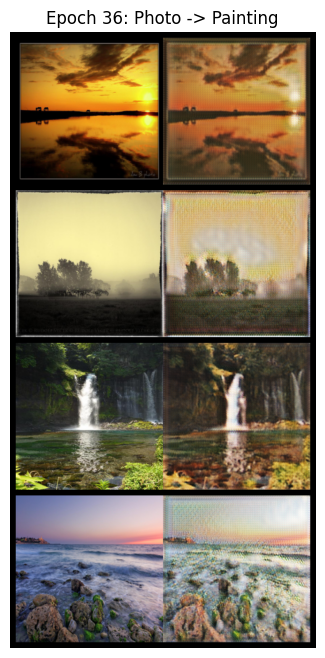

Epoch [36/50] Completed
  Generator Loss: 3.2731
  Cycle Consistency Loss: 0.2405
  Identity Loss: 0.3091
  Discriminator X Loss: 0.2169
  Discriminator Y Loss: 0.2142
Epoch [37/50]


Epoch [37/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.216, D_X_Loss=0.311, D_Y_Loss=0.253, Generator_Loss=2.99, Identity_Loss=0.314]


Model parameters saved for epoch 37.


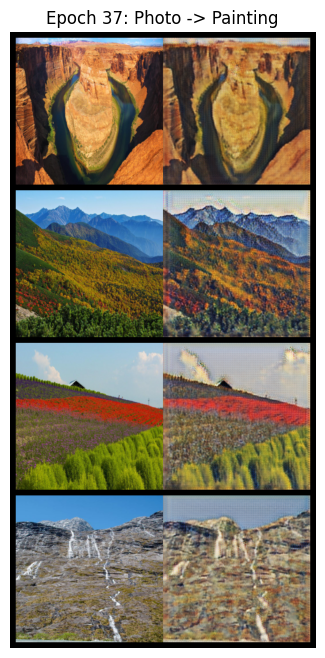

Epoch [37/50] Completed
  Generator Loss: 3.3568
  Cycle Consistency Loss: 0.2467
  Identity Loss: 0.3039
  Discriminator X Loss: 0.2141
  Discriminator Y Loss: 0.2095
Epoch [38/50]


Epoch [38/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.242, D_X_Loss=0.263, D_Y_Loss=0.229, Generator_Loss=3.32, Identity_Loss=0.343]


Model parameters saved for epoch 38.


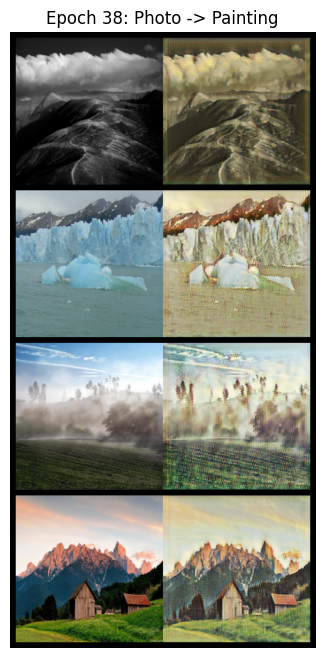

Epoch [38/50] Completed
  Generator Loss: 3.2403
  Cycle Consistency Loss: 0.2359
  Identity Loss: 0.3021
  Discriminator X Loss: 0.2145
  Discriminator Y Loss: 0.2129
Epoch [39/50]


Epoch [39/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.193, D_X_Loss=0.19, D_Y_Loss=0.176, Generator_Loss=2.86, Identity_Loss=0.239] 


Model parameters saved for epoch 39.


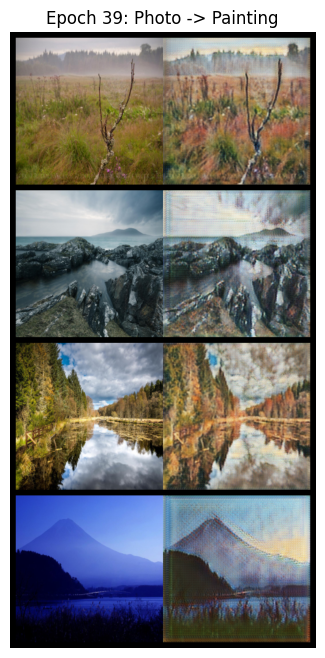

Epoch [39/50] Completed
  Generator Loss: 3.2767
  Cycle Consistency Loss: 0.2374
  Identity Loss: 0.3037
  Discriminator X Loss: 0.2071
  Discriminator Y Loss: 0.2126
Epoch [40/50]


Epoch [40/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.293, D_X_Loss=0.123, D_Y_Loss=0.256, Generator_Loss=3.91, Identity_Loss=0.327]


Model parameters saved for epoch 40.


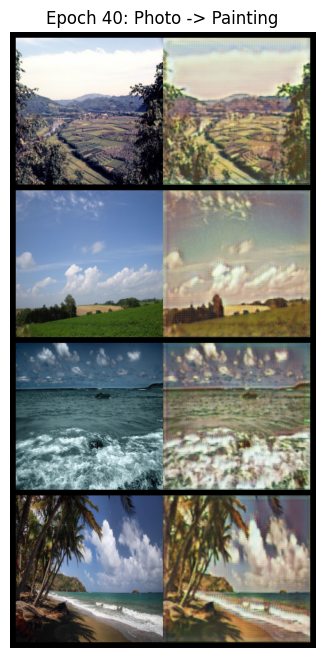

Epoch [40/50] Completed
  Generator Loss: 4.2789
  Cycle Consistency Loss: 0.2764
  Identity Loss: 0.3307
  Discriminator X Loss: 0.2048
  Discriminator Y Loss: 0.8477
Epoch [41/50]


Epoch [41/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.246, D_X_Loss=0.163, D_Y_Loss=0.231, Generator_Loss=3.27, Identity_Loss=0.318]


Model parameters saved for epoch 41.


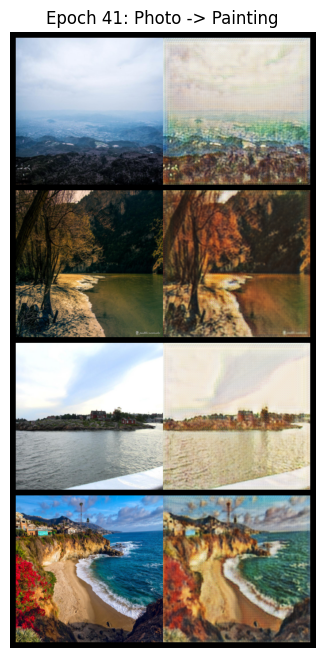

Epoch [41/50] Completed
  Generator Loss: 3.2500
  Cycle Consistency Loss: 0.2427
  Identity Loss: 0.3030
  Discriminator X Loss: 0.2086
  Discriminator Y Loss: 0.2551
Epoch [42/50]


Epoch [42/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.226, D_X_Loss=0.161, D_Y_Loss=0.228, Generator_Loss=3.15, Identity_Loss=0.244]


Model parameters saved for epoch 42.


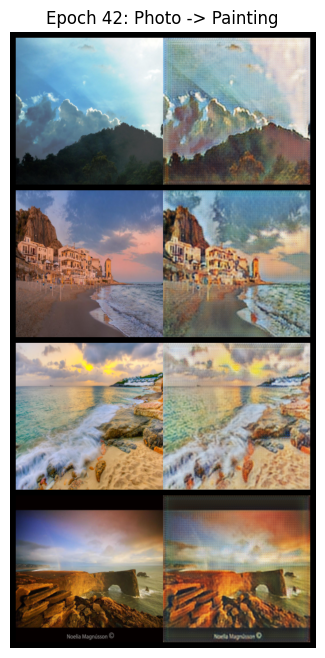

Epoch [42/50] Completed
  Generator Loss: 3.0629
  Cycle Consistency Loss: 0.2261
  Identity Loss: 0.2884
  Discriminator X Loss: 0.2290
  Discriminator Y Loss: 0.2476
Epoch [43/50]


Epoch [43/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.189, D_X_Loss=0.171, D_Y_Loss=0.24, Generator_Loss=2.82, Identity_Loss=0.263] 


Model parameters saved for epoch 43.


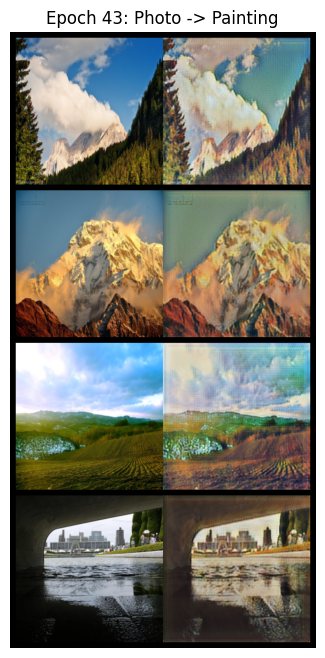

Epoch [43/50] Completed
  Generator Loss: 2.9487
  Cycle Consistency Loss: 0.2159
  Identity Loss: 0.2812
  Discriminator X Loss: 0.2095
  Discriminator Y Loss: 0.2422
Epoch [44/50]


Epoch [44/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.267, D_X_Loss=0.24, D_Y_Loss=0.281, Generator_Loss=3.51, Identity_Loss=0.333] 


Model parameters saved for epoch 44.


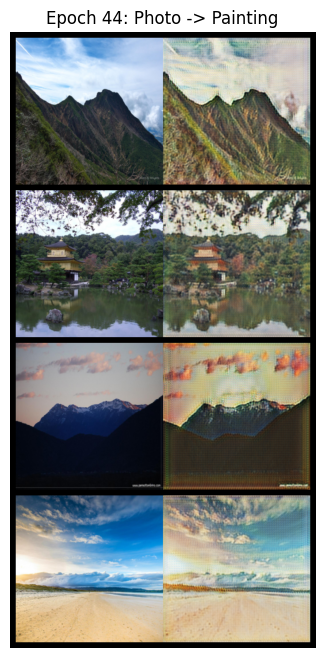

Epoch [44/50] Completed
  Generator Loss: 2.9824
  Cycle Consistency Loss: 0.2179
  Identity Loss: 0.2901
  Discriminator X Loss: 0.2113
  Discriminator Y Loss: 0.2394
Epoch [45/50]


Epoch [45/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.212, D_X_Loss=0.314, D_Y_Loss=0.204, Generator_Loss=3.11, Identity_Loss=0.289]


Model parameters saved for epoch 45.


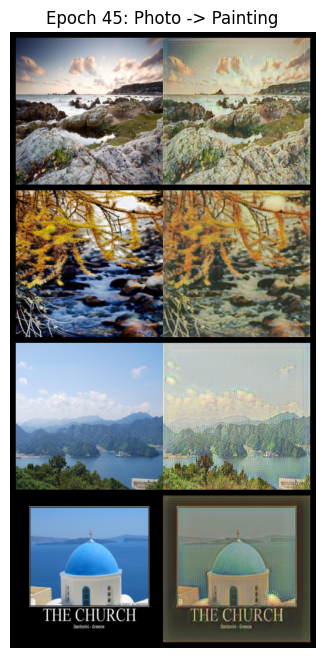

Epoch [45/50] Completed
  Generator Loss: 3.9778
  Cycle Consistency Loss: 0.2306
  Identity Loss: 0.2952
  Discriminator X Loss: 1.0175
  Discriminator Y Loss: 0.2388
Epoch [46/50]


Epoch [46/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.192, D_X_Loss=0.252, D_Y_Loss=0.226, Generator_Loss=2.58, Identity_Loss=0.247]


Model parameters saved for epoch 46.


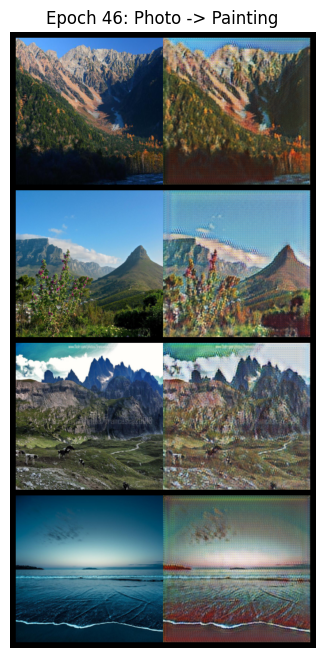

Epoch [46/50] Completed
  Generator Loss: 2.8980
  Cycle Consistency Loss: 0.2124
  Identity Loss: 0.2756
  Discriminator X Loss: 0.2633
  Discriminator Y Loss: 0.2363
Epoch [47/50]


Epoch [47/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.22, D_X_Loss=0.267, D_Y_Loss=0.22, Generator_Loss=2.99, Identity_Loss=0.288]  


Model parameters saved for epoch 47.


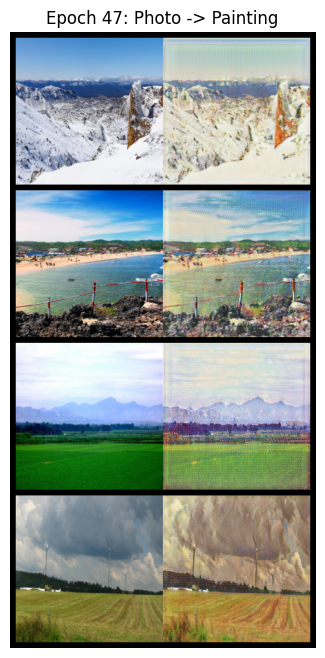

Epoch [47/50] Completed
  Generator Loss: 2.8243
  Cycle Consistency Loss: 0.2067
  Identity Loss: 0.2804
  Discriminator X Loss: 0.2481
  Discriminator Y Loss: 0.2426
Epoch [48/50]


Epoch [48/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.222, D_X_Loss=0.226, D_Y_Loss=0.213, Generator_Loss=3.03, Identity_Loss=0.274]


Model parameters saved for epoch 48.


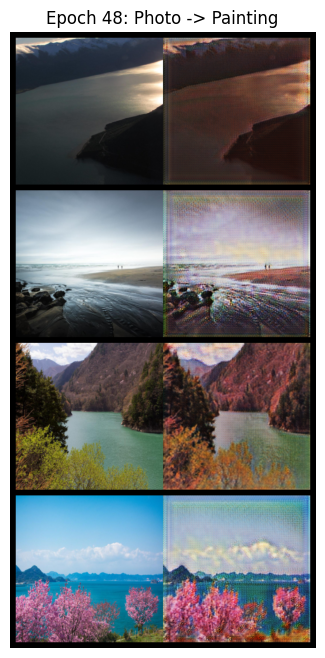

Epoch [48/50] Completed
  Generator Loss: 2.8519
  Cycle Consistency Loss: 0.2073
  Identity Loss: 0.2798
  Discriminator X Loss: 0.2404
  Discriminator Y Loss: 0.2374
Epoch [49/50]


Epoch [49/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.218, D_X_Loss=0.226, D_Y_Loss=0.202, Generator_Loss=3.08, Identity_Loss=0.32] 


Model parameters saved for epoch 49.


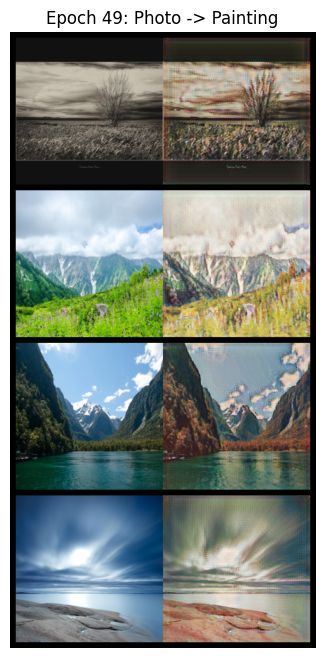

Epoch [49/50] Completed
  Generator Loss: 2.8876
  Cycle Consistency Loss: 0.2077
  Identity Loss: 0.2860
  Discriminator X Loss: 0.2386
  Discriminator Y Loss: 0.2252
Epoch [50/50]


Epoch [50/50]: 100%|██████████| 169/169 [02:42<00:00,  1.04it/s, Cycle_Loss=0.243, D_X_Loss=0.182, D_Y_Loss=0.189, Generator_Loss=3.33, Identity_Loss=0.29] 


Model parameters saved for epoch 50.


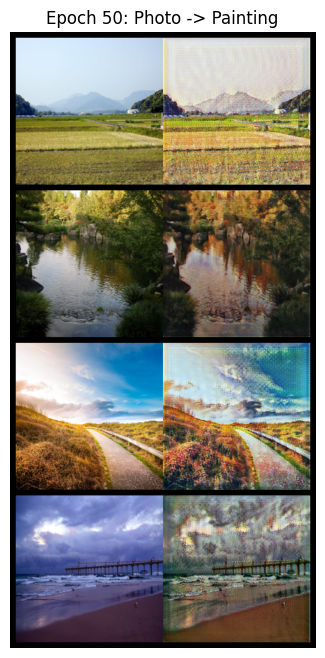

Epoch [50/50] Completed
  Generator Loss: 2.9182
  Cycle Consistency Loss: 0.2105
  Identity Loss: 0.2878
  Discriminator X Loss: 0.2308
  Discriminator Y Loss: 0.2319


In [12]:
import matplotlib.pyplot as plt
from tqdm import tqdm

losses = {
    "generator": [],
    "cycle": [],
    "identity": [],
    "discriminator_X": [],
    "discriminator_Y": []
}

for epoch in range(num_epochs):
    print(f"Epoch [{epoch+1}/{num_epochs}]")
    loop = tqdm(zip(landscape_loader, art_loader), leave=True, total=min(len(landscape_loader), len(art_loader)))

    
    epoch_loss_G = 0.0
    epoch_loss_cycle = 0.0
    epoch_loss_identity = 0.0
    epoch_loss_D_X = 0.0
    epoch_loss_D_Y = 0.0
    num_batches = 0

    for i, (real_landscape, real_art) in enumerate(loop):
        real_landscape = real_landscape.to(device)
        real_art = real_art.to(device)

        optimizer_G.zero_grad()

        fake_art = G_X_to_Y(real_landscape)  # Landscape -> Naive Art Primitivism
        fake_landscape = G_Y_to_X(real_art)  # Naive Art Primitivism -> Landscape

        cycled_landscape = G_Y_to_X(fake_art)  # Fake Art -> Landscape
        cycled_art = G_X_to_Y(fake_landscape)  # Fake Landscape -> Art

        identity_landscape = G_Y_to_X(real_landscape)  # Landscape -> Landscape
        identity_art = G_X_to_Y(real_art)  # Art -> Art

        loss_G_X_to_Y = adversarial_loss(D_Y(fake_art), torch.ones_like(D_Y(fake_art)))
        loss_G_Y_to_X = adversarial_loss(D_X(fake_landscape), torch.ones_like(D_X(fake_landscape)))

        loss_cycle = cycle_consistency_loss(real_landscape, cycled_landscape) + cycle_consistency_loss(real_art, cycled_art)

        loss_identity = identity_loss(real_landscape, identity_landscape) + identity_loss(real_art, identity_art)

        loss_G = loss_G_X_to_Y + loss_G_Y_to_X + lambda_cycle * loss_cycle + lambda_identity * loss_identity
        loss_G.backward()
        optimizer_G.step()

        optimizer_D_X.zero_grad()

        loss_D_X_real = adversarial_loss(D_X(real_landscape), torch.ones_like(D_X(real_landscape)))
        loss_D_X_fake = adversarial_loss(D_X(fake_landscape.detach()), torch.zeros_like(D_X(fake_landscape)))
        loss_D_X = (loss_D_X_real + loss_D_X_fake) * 0.5
        loss_D_X.backward()
        optimizer_D_X.step()

        optimizer_D_Y.zero_grad()

        loss_D_Y_real = adversarial_loss(D_Y(real_art), torch.ones_like(D_Y(real_art)))
        loss_D_Y_fake = adversarial_loss(D_Y(fake_art.detach()), torch.zeros_like(D_Y(fake_art)))
        loss_D_Y = (loss_D_Y_real + loss_D_Y_fake) * 0.5
        loss_D_Y.backward()
        optimizer_D_Y.step()

        epoch_loss_G += loss_G.item()
        epoch_loss_cycle += loss_cycle.item()
        epoch_loss_identity += loss_identity.item()
        epoch_loss_D_X += loss_D_X.item()
        epoch_loss_D_Y += loss_D_Y.item()
        num_batches += 1

        loop.set_description(f"Epoch [{epoch+1}/{num_epochs}]")
        loop.set_postfix(
            Generator_Loss=loss_G.item(),
            Cycle_Loss=loss_cycle.item(),
            Identity_Loss=loss_identity.item(),
            D_X_Loss=loss_D_X.item(),
            D_Y_Loss=loss_D_Y.item()
        )

    losses["generator"].append(epoch_loss_G / num_batches)
    losses["cycle"].append(epoch_loss_cycle / num_batches)
    losses["identity"].append(epoch_loss_identity / num_batches)
    losses["discriminator_X"].append(epoch_loss_D_X / num_batches)
    losses["discriminator_Y"].append(epoch_loss_D_Y / num_batches)
    
    save_model(epoch + 1, G_X_to_Y, G_Y_to_X, D_X, D_Y)
    with torch.no_grad():
        sample_photos = next(iter(landscape_loader))  
        visualize_progress(G_X_to_Y, sample_photos, epoch + 1)
    
    print(f"Epoch [{epoch+1}/{num_epochs}] Completed")
    print(f"  Generator Loss: {losses['generator'][-1]:.4f}")
    print(f"  Cycle Consistency Loss: {losses['cycle'][-1]:.4f}")
    print(f"  Identity Loss: {losses['identity'][-1]:.4f}")
    print(f"  Discriminator X Loss: {losses['discriminator_X'][-1]:.4f}")
    print(f"  Discriminator Y Loss: {losses['discriminator_Y'][-1]:.4f}")


In [12]:
def compare_images(generator, input_images, save_dir="comparison_results", show=True, padding=10):
    os.makedirs(save_dir, exist_ok=True)

    generator.eval() 
    with torch.no_grad():
        input_images = input_images.to(device)
        generated_images = generator(input_images)  # Generate images

    comparison = torch.cat((input_images.cpu(), generated_images.cpu()), dim=3)

    vutils.save_image(comparison, f"{save_dir}/comparison.png", normalize=True, padding=padding)

    if show:
        grid = vutils.make_grid(comparison, normalize=True, nrow=1, padding=padding)
        plt.figure(figsize=(16, 8))  
        plt.imshow(grid.permute(1, 2, 0))  
        plt.axis("off")
        plt.show()


In [66]:
load_model(epoch=100, G_X_to_Y=G_X_to_Y, G_Y_to_X=G_Y_to_X, D_X=D_X, D_Y=D_Y)

Model parameters loaded for epoch 100.


C:\Users\Endless\AppData\Local\Temp\ipykernel_7972\1199615934.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  G_X_to_Y.load_state_dict(torch.load(f"{save_dir}/G_X_to_Y_e

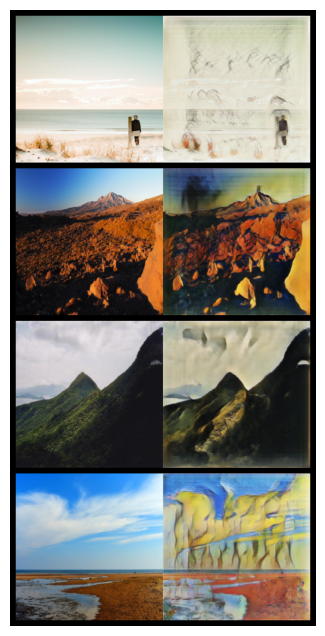

In [14]:
import torchvision.utils as vutils
from torch.utils.data import DataLoader

test_loader = DataLoader(landscape_dataset, batch_size=4, shuffle=True)
real_landscape = next(iter(test_loader)).to(device)

compare_images(G_X_to_Y, real_landscape, show=True)

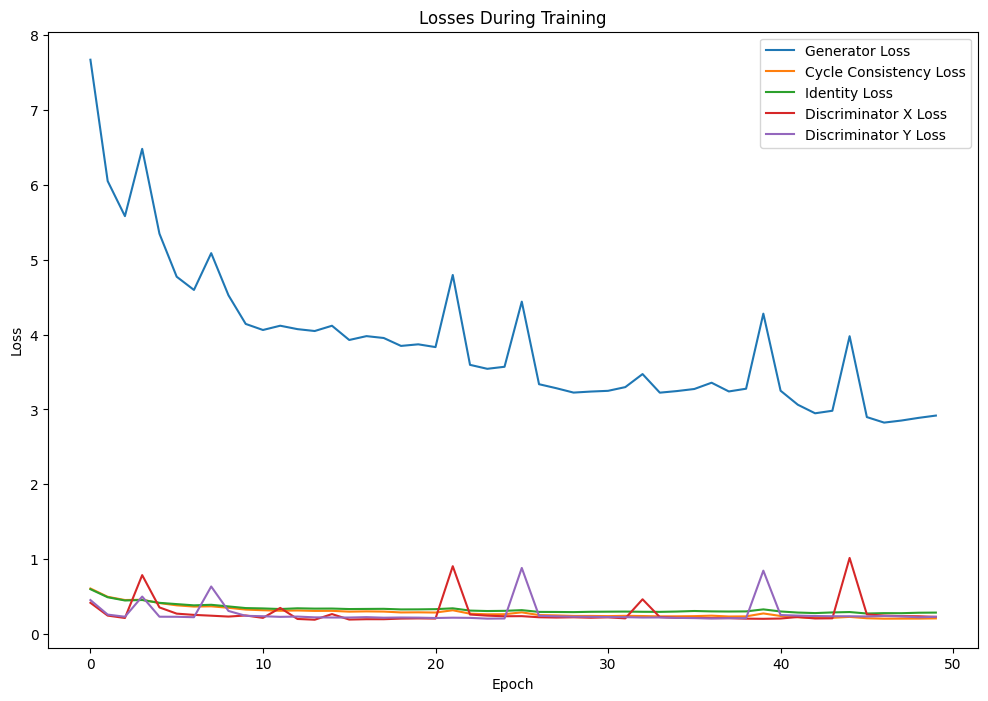

In [15]:
plt.figure(figsize=(12, 8))
plt.plot(losses["generator"], label="Generator Loss")
plt.plot(losses["cycle"], label="Cycle Consistency Loss")
plt.plot(losses["identity"], label="Identity Loss")
plt.plot(losses["discriminator_X"], label="Discriminator X Loss")
plt.plot(losses["discriminator_Y"], label="Discriminator Y Loss")
plt.title("Losses During Training")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [88]:
from PIL import Image
import torchvision.transforms as transforms

def upscale_image(image, target_size=(512, 512)):
    if isinstance(image, torch.Tensor):
        image = transforms.ToPILImage()(image)
    
    upscaled_image = image.resize(target_size, Image.BICUBIC)  
    return upscaled_image

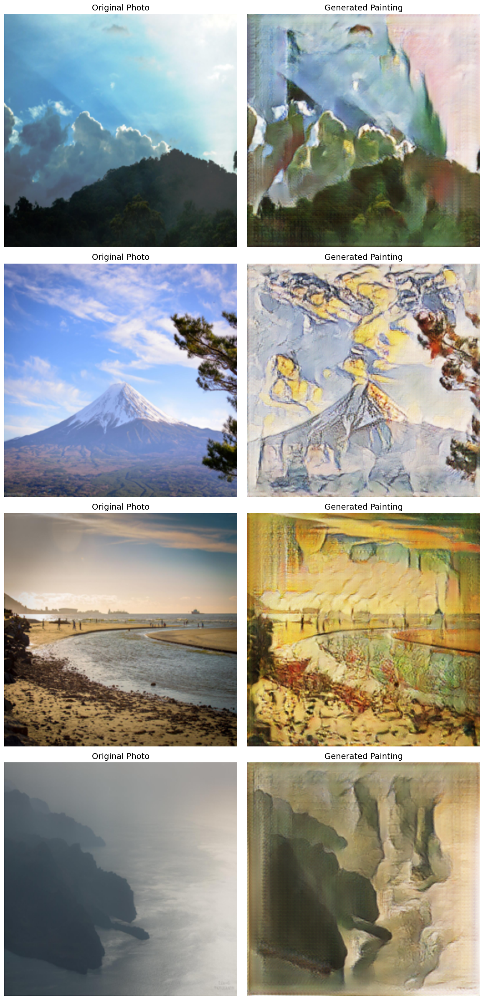

In [34]:
def compare_images(generator, input_photos, target_size=(512, 512), num_samples=5):
    generator.eval() 

    input_photos = input_photos[:num_samples].to(device)
    
    with torch.no_grad():
        generated_paintings = generator(input_photos)

    unnormalize = transforms.Normalize(mean=[-0.5 / 0.5, -0.5 / 0.5, -0.5 / 0.5], std=[1 / 0.5, 1 / 0.5, 1 / 0.5])
    input_photos = unnormalize(input_photos).clamp(0, 1)
    generated_paintings = unnormalize(generated_paintings).clamp(0, 1)

    upscaled_photos = [upscale_image(transforms.ToPILImage()(photo).convert("RGB"), target_size) for photo in input_photos]
    upscaled_paintings = [upscale_image(transforms.ToPILImage()(painting).convert("RGB"), target_size) for painting in generated_paintings]

    fig, axes = plt.subplots(num_samples, 2, figsize=(12, num_samples * 6))
    for i in range(num_samples):
        axes[i, 0].imshow(upscaled_photos[i])
        axes[i, 0].set_title("Original Photo", fontsize=14)
        axes[i, 0].axis("off")

        axes[i, 1].imshow(upscaled_paintings[i])
        axes[i, 1].set_title("Generated Painting", fontsize=14)
        axes[i, 1].axis("off")
    
    plt.tight_layout()
    plt.show()

sample_photos = next(iter(landscape_loader)) 
compare_images(generator=G_X_to_Y, input_photos=sample_photos, target_size=(512, 512), num_samples=4)


In [19]:
from datetime import datetime

def save_comparison(generator, input_photos, target_size=(512, 512), num_samples=5, save_dir=r"E:\Code\GAN\Result"):
    generator.eval()  
    os.makedirs(save_dir, exist_ok=True)

    input_photos = input_photos[:num_samples].to(device)
    
    with torch.no_grad():
        generated_paintings = generator(input_photos)

    unnormalize = transforms.Normalize(mean=[-0.5 / 0.5, -0.5 / 0.5, -0.5 / 0.5], std=[1 / 0.5, 1 / 0.5, 1 / 0.5])
    input_photos = unnormalize(input_photos).clamp(0, 1)
    generated_paintings = unnormalize(generated_paintings).clamp(0, 1)

    upscaled_photos = [upscale_image(transforms.ToPILImage()(photo).convert("RGB"), target_size) for photo in input_photos]
    upscaled_paintings = [upscale_image(transforms.ToPILImage()(painting).convert("RGB"), target_size) for painting in generated_paintings]

    fig, axes = plt.subplots(num_samples, 2, figsize=(12, num_samples * 6))
    for i in range(num_samples):
        axes[i, 0].imshow(upscaled_photos[i])
        axes[i, 0].set_title("Original Photo", fontsize=14)
        axes[i, 0].axis("off")

        axes[i, 1].imshow(upscaled_paintings[i])
        axes[i, 1].set_title("Generated Painting", fontsize=14)
        axes[i, 1].axis("off")
    
    plt.tight_layout()

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    save_path = os.path.join(save_dir, f"comparison_{timestamp}.jpg")

    fig.savefig(save_path, format="jpg")
    print(f"Comparison saved to {save_path}")

    plt.close(fig) 


In [24]:
save_comparison(generator=G_X_to_Y, input_photos=sample_photos, target_size=(512, 512), num_samples=4)

Comparison saved to E:\Code\GAN\Result\comparison_20241223_132732.jpg


Generated painting saved at E:\Code\GAN\output\generated_20241228_143552.jpg
Comparison saved at E:\Code\GAN\output\comparison_20241228_143552.jpg


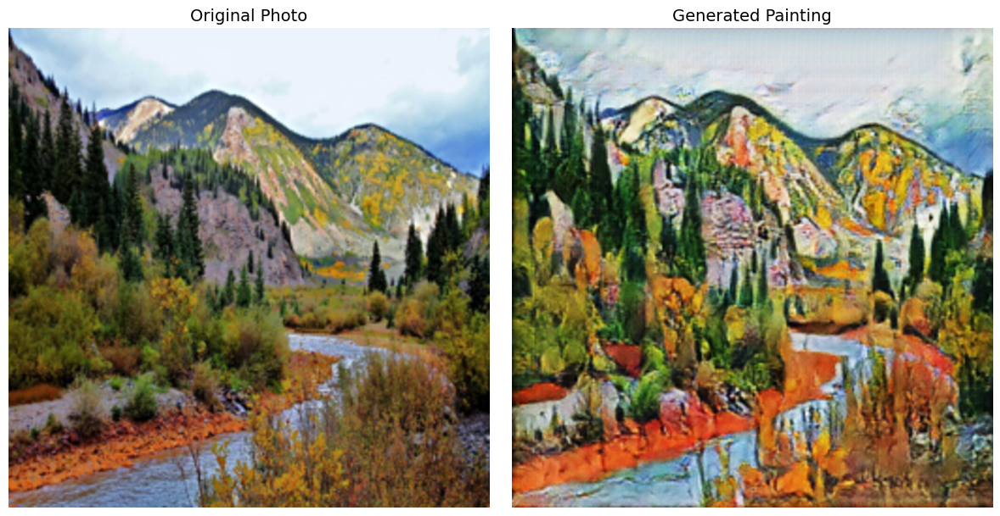

In [32]:
import os
from PIL import Image
import torch
import torchvision.transforms as transforms
from datetime import datetime
import matplotlib.pyplot as plt

def process_and_generate(generator, input_image_path, target_size=(512, 512), save_dir=r"E:\Code\GAN\output"):
    os.makedirs(save_dir, exist_ok=True)

    transform = transforms.Compose([
        transforms.Resize((256, 256)), 
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]) 
    ])
    input_image = Image.open(input_image_path).convert("RGB")
    preprocessed_image = transform(input_image).unsqueeze(0).to(device) 

    generator.eval() 
    with torch.no_grad():
        generated_image = generator(preprocessed_image)

    unnormalize = transforms.Normalize(mean=[-0.5 / 0.5, -0.5 / 0.5, -0.5 / 0.5], std=[1 / 0.5, 1 / 0.5, 1 / 0.5])
    preprocessed_image = unnormalize(preprocessed_image.squeeze(0)).clamp(0, 1)
    generated_image = unnormalize(generated_image.squeeze(0)).clamp(0, 1)

    upscaled_original = upscale_image(transforms.ToPILImage()(preprocessed_image).convert("RGB"), target_size)
    upscaled_generated = upscale_image(transforms.ToPILImage()(generated_image).convert("RGB"), target_size)

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    generated_save_path = os.path.join(save_dir, f"generated_{timestamp}.jpg")
    upscaled_generated.save(generated_save_path)
    print(f"Generated painting saved at {generated_save_path}")

    comparison_save_path = os.path.join(save_dir, f"comparison_{timestamp}.jpg")
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    
    axes[0].imshow(upscaled_original)
    axes[0].set_title("Original Photo", fontsize=14)
    axes[0].axis("off")

    axes[1].imshow(upscaled_generated)
    axes[1].set_title("Generated Painting", fontsize=14)
    axes[1].axis("off")

    plt.tight_layout()
    fig.savefig(comparison_save_path, format="jpg")
    print(f"Comparison saved at {comparison_save_path}")
    plt.show()
    plt.close(fig)

input_image_path = r"E:\Code\GAN\input\00000137_(3).jpg" 
process_and_generate(generator=G_X_to_Y, input_image_path=input_image_path, target_size=(3000, 3000))


In [68]:
def visualize_intermediate_outputs(generator_X_to_Y, generator_Y_to_X, input_image_path, target_size=(512, 512)):
    transform = transforms.Compose([
        transforms.Resize((256, 256)), 
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])  
    ])
    input_image = Image.open(input_image_path).convert("RGB")
    preprocessed_image = transform(input_image).unsqueeze(0).to(device)  

    generator_X_to_Y.eval()
    generator_Y_to_X.eval()
    with torch.no_grad():
        fake_painting = generator_X_to_Y(preprocessed_image)
        reconstructed_photo = generator_Y_to_X(fake_painting)

        fake_photo = generator_Y_to_X(preprocessed_image)
        reconstructed_painting = generator_X_to_Y(fake_photo)

    unnormalize = transforms.Normalize(mean=[-0.5 / 0.5, -0.5 / 0.5, -0.5 / 0.5], std=[1 / 0.5, 1 / 0.5, 1 / 0.5])
    preprocessed_image = unnormalize(preprocessed_image.squeeze(0)).clamp(0, 1)
    fake_painting = unnormalize(fake_painting.squeeze(0)).clamp(0, 1)
    reconstructed_photo = unnormalize(reconstructed_photo.squeeze(0)).clamp(0, 1)
    fake_photo = unnormalize(fake_photo.squeeze(0)).clamp(0, 1)
    reconstructed_painting = unnormalize(reconstructed_painting.squeeze(0)).clamp(0, 1)

    upscaled_original = upscale_image(transforms.ToPILImage()(preprocessed_image).convert("RGB"), target_size)
    upscaled_fake_painting = upscale_image(transforms.ToPILImage()(fake_painting).convert("RGB"), target_size)
    upscaled_reconstructed_photo = upscale_image(transforms.ToPILImage()(reconstructed_photo).convert("RGB"), target_size)
    upscaled_fake_photo = upscale_image(transforms.ToPILImage()(fake_photo).convert("RGB"), target_size)
    upscaled_reconstructed_painting = upscale_image(transforms.ToPILImage()(reconstructed_painting).convert("RGB"), target_size)

    fig, axes = plt.subplots(1, 5, figsize=(20, 8))
    titles = ["Original Photo", "Photo -> Painting", "Reconstructed Photo", "Painting -> Photo", "Reconstructed Painting"]
    images = [upscaled_original, upscaled_fake_painting, upscaled_reconstructed_photo, upscaled_fake_photo, upscaled_reconstructed_painting]

    for i, (title, img) in enumerate(zip(titles, images)):
        axes[i].imshow(img)
        axes[i].set_title(title, fontsize=14)
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


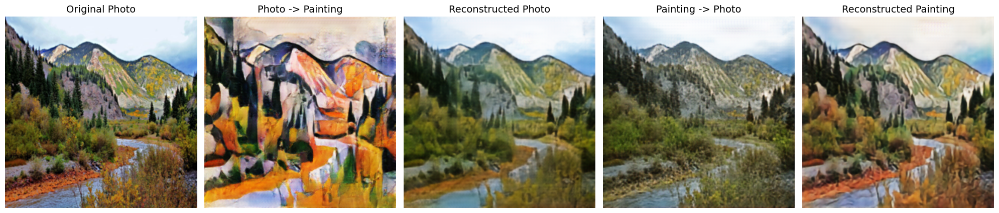

In [78]:
input_image_path = r"E:\Code\GAN\input\00000137_(3).jpg" 
visualize_intermediate_outputs(generator_X_to_Y=G_X_to_Y, generator_Y_to_X=G_Y_to_X, input_image_path=input_image_path, target_size=(1024, 1024))

In [82]:
def compare_first_and_full_gan(generator_X_to_Y, generator_Y_to_X, input_image_path, target_size=(512, 512)):
    transform = transforms.Compose([
        transforms.Resize((256, 256)),  # Resize to match model input
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]) 
    ])
    input_image = Image.open(input_image_path).convert("RGB")
    preprocessed_image = transform(input_image).unsqueeze(0).to(device)  

    generator_X_to_Y.eval()
    generator_Y_to_X.eval()
    with torch.no_grad():
        fake_painting = generator_X_to_Y(preprocessed_image)
        reconstructed_photo = generator_Y_to_X(fake_painting)

    unnormalize = transforms.Normalize(mean=[-0.5 / 0.5, -0.5 / 0.5, -0.5 / 0.5], std=[1 / 0.5, 1 / 0.5, 1 / 0.5])
    preprocessed_image = unnormalize(preprocessed_image.squeeze(0)).clamp(0, 1)
    fake_painting = unnormalize(fake_painting.squeeze(0)).clamp(0, 1)
    reconstructed_photo = unnormalize(reconstructed_photo.squeeze(0)).clamp(0, 1)

    upscaled_original = upscale_image(transforms.ToPILImage()(preprocessed_image).convert("RGB"), target_size)
    upscaled_fake_painting = upscale_image(transforms.ToPILImage()(fake_painting).convert("RGB"), target_size)
    upscaled_reconstructed_photo = upscale_image(transforms.ToPILImage()(reconstructed_photo).convert("RGB"), target_size)

    fig, axes = plt.subplots(1, 3, figsize=(20, 8))  # Dynamically scale figure size
    titles = ["Original Photo", "Photo -> Painting (First GAN)", "Photo -> Painting -> Photo (Full GAN)"]
    images = [upscaled_original, upscaled_fake_painting, upscaled_reconstructed_photo]

    for i, (title, img) in enumerate(zip(titles, images)):
        axes[i].imshow(img)
        axes[i].set_title(title, fontsize=14)
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

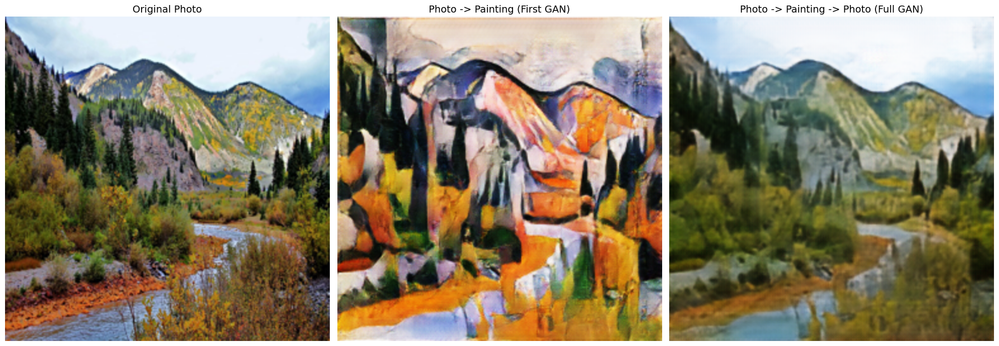

In [83]:
input_image_path = r"E:\Code\GAN\input\00000137_(3).jpg" 
compare_first_and_full_gan(generator_X_to_Y=G_X_to_Y, generator_Y_to_X=G_Y_to_X, input_image_path=input_image_path, target_size=(3000, 3000))

In [14]:
def load_model_and_resume(epoch, G_X_to_Y, G_Y_to_X, D_X, D_Y, save_dir=r"E:\Code\GAN\model"):
    load_model(epoch, G_X_to_Y, G_Y_to_X, D_X, D_Y, save_dir)  # Load model parameters
    print(f"Model parameters loaded for epoch {epoch}. Resuming training from epoch {epoch + 1}.")
    return epoch + 1


C:\Users\Endless\AppData\Local\Temp\ipykernel_4616\31553896.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  G_X_to_Y.load_state_dict(torch.load(f"{save_dir}/G_X_to_Y_epo

Model parameters loaded for epoch 50.
Model parameters loaded for epoch 50. Resuming training from epoch 51.
Epoch [51/150]


Epoch [51/150]: 100%|██████████| 602/602 [09:55<00:00,  1.01it/s, Cycle_Loss=0.191, D_X_Loss=0.179, D_Y_Loss=0.055, Generator_Loss=3.14, Identity_Loss=0.252] 


Model parameters saved for epoch 51.


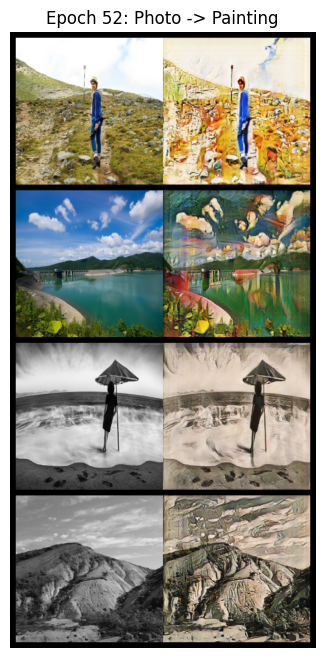

Epoch [51/150] Completed
  Generator Loss: 2.7505
  Cycle Consistency Loss: 0.1755
  Identity Loss: 0.2509
  Discriminator X Loss: 0.2002
  Discriminator Y Loss: 0.1844
Epoch [52/150]


Epoch [52/150]: 100%|██████████| 602/602 [09:35<00:00,  1.05it/s, Cycle_Loss=0.178, D_X_Loss=0.185, D_Y_Loss=0.124, Generator_Loss=2.73, Identity_Loss=0.196] 


Model parameters saved for epoch 52.


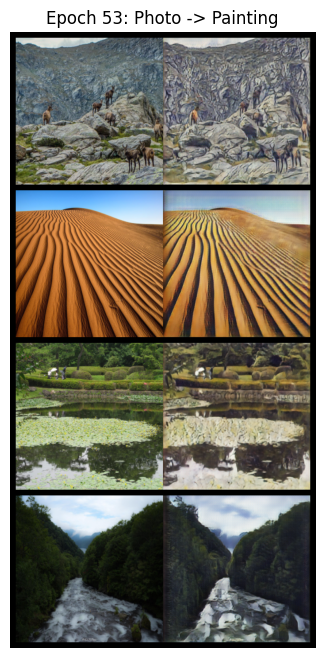

Epoch [52/150] Completed
  Generator Loss: 2.7377
  Cycle Consistency Loss: 0.1741
  Identity Loss: 0.2491
  Discriminator X Loss: 0.1979
  Discriminator Y Loss: 0.1838
Epoch [53/150]


Epoch [53/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.177, D_X_Loss=0.23, D_Y_Loss=0.22, Generator_Loss=2.81, Identity_Loss=0.24]    


Model parameters saved for epoch 53.


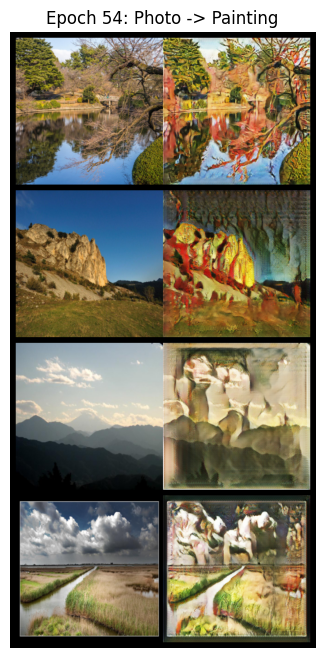

Epoch [53/150] Completed
  Generator Loss: 2.7304
  Cycle Consistency Loss: 0.1740
  Identity Loss: 0.2472
  Discriminator X Loss: 0.2005
  Discriminator Y Loss: 0.1844
Epoch [54/150]


Epoch [54/150]: 100%|██████████| 602/602 [09:29<00:00,  1.06it/s, Cycle_Loss=0.197, D_X_Loss=0.209, D_Y_Loss=0.166, Generator_Loss=3.13, Identity_Loss=0.235] 


Model parameters saved for epoch 54.


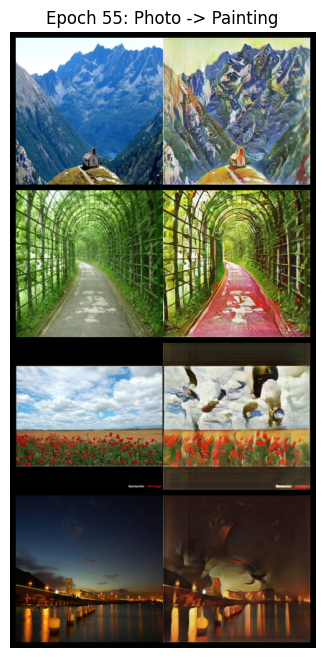

Epoch [54/150] Completed
  Generator Loss: 2.7384
  Cycle Consistency Loss: 0.1737
  Identity Loss: 0.2472
  Discriminator X Loss: 0.1967
  Discriminator Y Loss: 0.1822
Epoch [55/150]


Epoch [55/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.145, D_X_Loss=0.201, D_Y_Loss=0.147, Generator_Loss=2.36, Identity_Loss=0.268] 


Model parameters saved for epoch 55.


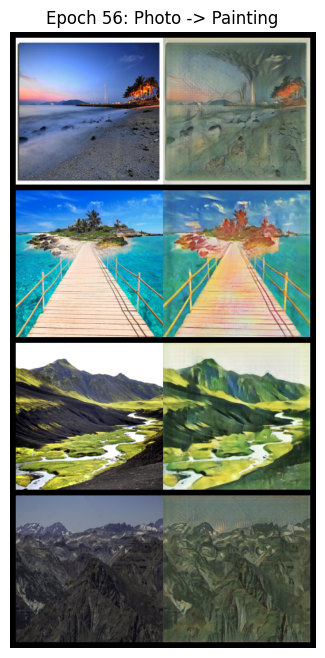

Epoch [55/150] Completed
  Generator Loss: 2.7418
  Cycle Consistency Loss: 0.1739
  Identity Loss: 0.2477
  Discriminator X Loss: 0.1980
  Discriminator Y Loss: 0.1814
Epoch [56/150]


Epoch [56/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.165, D_X_Loss=0.129, D_Y_Loss=0.0515, Generator_Loss=2.98, Identity_Loss=0.199] 


Model parameters saved for epoch 56.


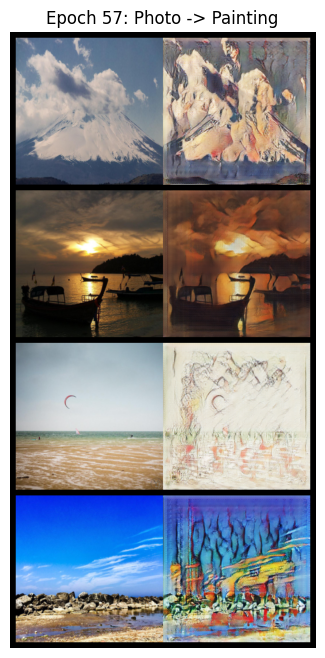

Epoch [56/150] Completed
  Generator Loss: 2.7285
  Cycle Consistency Loss: 0.1725
  Identity Loss: 0.2434
  Discriminator X Loss: 0.1958
  Discriminator Y Loss: 0.1822
Epoch [57/150]


Epoch [57/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.148, D_X_Loss=0.282, D_Y_Loss=0.136, Generator_Loss=2.35, Identity_Loss=0.209] 


Model parameters saved for epoch 57.


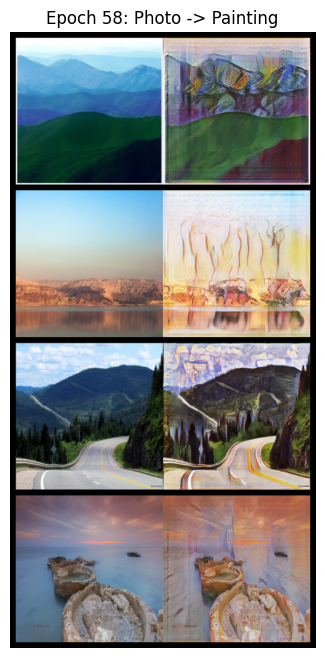

Epoch [57/150] Completed
  Generator Loss: 2.7107
  Cycle Consistency Loss: 0.1708
  Identity Loss: 0.2453
  Discriminator X Loss: 0.1989
  Discriminator Y Loss: 0.1814
Epoch [58/150]


Epoch [58/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.217, D_X_Loss=0.183, D_Y_Loss=0.126, Generator_Loss=3.27, Identity_Loss=0.227] 


Model parameters saved for epoch 58.


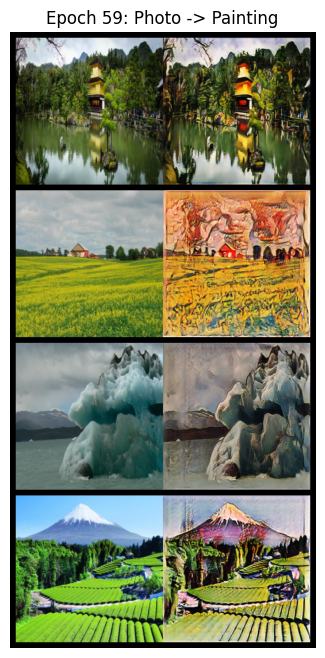

Epoch [58/150] Completed
  Generator Loss: 2.6931
  Cycle Consistency Loss: 0.1690
  Identity Loss: 0.2419
  Discriminator X Loss: 0.1943
  Discriminator Y Loss: 0.1794
Epoch [59/150]


Epoch [59/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.124, D_X_Loss=0.115, D_Y_Loss=0.0978, Generator_Loss=2.49, Identity_Loss=0.178]


Model parameters saved for epoch 59.


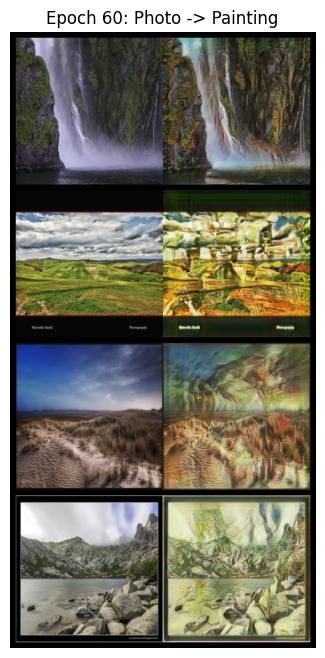

Epoch [59/150] Completed
  Generator Loss: 2.6999
  Cycle Consistency Loss: 0.1694
  Identity Loss: 0.2390
  Discriminator X Loss: 0.1951
  Discriminator Y Loss: 0.1805
Epoch [60/150]


Epoch [60/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.19, D_X_Loss=0.125, D_Y_Loss=0.0904, Generator_Loss=2.87, Identity_Loss=0.236] 


Model parameters saved for epoch 60.


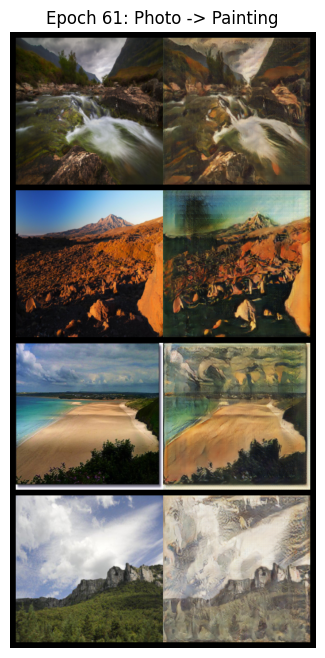

Epoch [60/150] Completed
  Generator Loss: 2.6903
  Cycle Consistency Loss: 0.1677
  Identity Loss: 0.2389
  Discriminator X Loss: 0.1944
  Discriminator Y Loss: 0.1797
Epoch [61/150]


Epoch [61/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.166, D_X_Loss=0.72, D_Y_Loss=0.12, Generator_Loss=3.17, Identity_Loss=0.196]    


Model parameters saved for epoch 61.


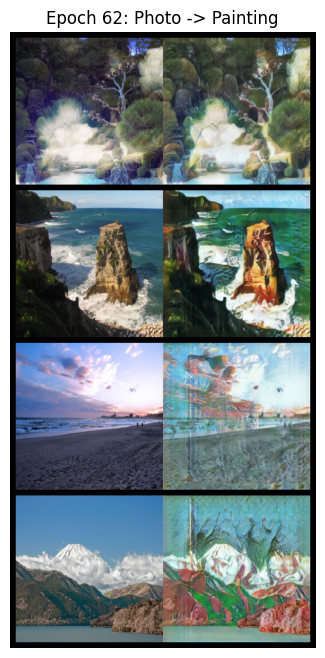

Epoch [61/150] Completed
  Generator Loss: 2.6831
  Cycle Consistency Loss: 0.1675
  Identity Loss: 0.2393
  Discriminator X Loss: 0.1985
  Discriminator Y Loss: 0.1798
Epoch [62/150]


Epoch [62/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.145, D_X_Loss=0.16, D_Y_Loss=0.143, Generator_Loss=2.77, Identity_Loss=0.184]   


Model parameters saved for epoch 62.


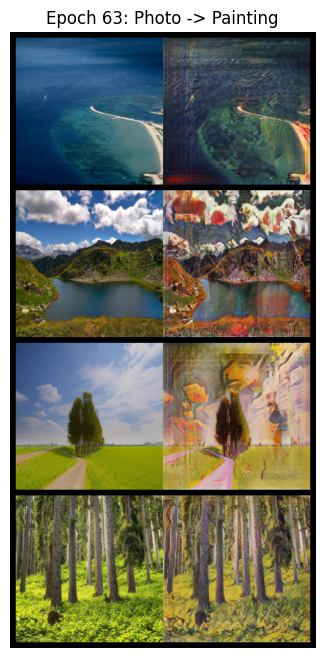

Epoch [62/150] Completed
  Generator Loss: 2.6776
  Cycle Consistency Loss: 0.1670
  Identity Loss: 0.2364
  Discriminator X Loss: 0.1964
  Discriminator Y Loss: 0.1778
Epoch [63/150]


Epoch [63/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.162, D_X_Loss=0.244, D_Y_Loss=0.189, Generator_Loss=2.54, Identity_Loss=0.212] 


Model parameters saved for epoch 63.


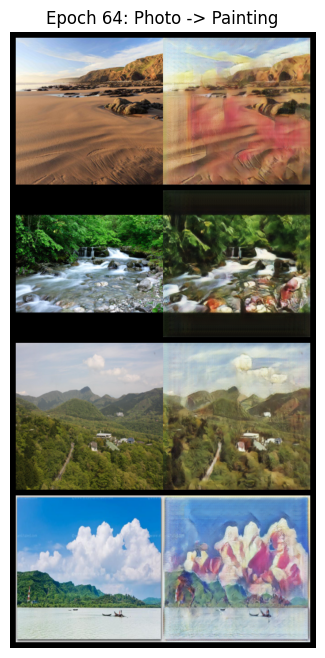

Epoch [63/150] Completed
  Generator Loss: 2.6935
  Cycle Consistency Loss: 0.1677
  Identity Loss: 0.2357
  Discriminator X Loss: 0.1940
  Discriminator Y Loss: 0.1786
Epoch [64/150]


Epoch [64/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.159, D_X_Loss=0.183, D_Y_Loss=0.148, Generator_Loss=2.84, Identity_Loss=0.192]  


Model parameters saved for epoch 64.


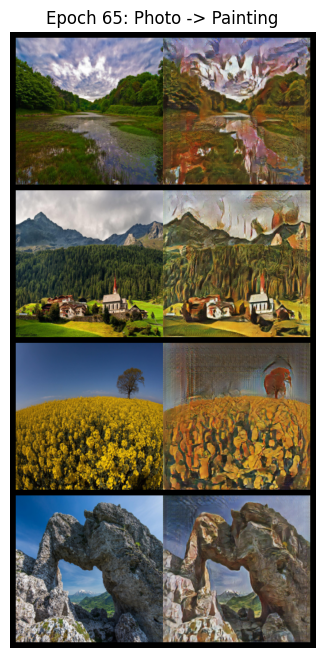

Epoch [64/150] Completed
  Generator Loss: 2.6980
  Cycle Consistency Loss: 0.1680
  Identity Loss: 0.2375
  Discriminator X Loss: 0.1941
  Discriminator Y Loss: 0.1775
Epoch [65/150]


Epoch [65/150]: 100%|██████████| 602/602 [09:25<00:00,  1.06it/s, Cycle_Loss=0.226, D_X_Loss=0.29, D_Y_Loss=0.193, Generator_Loss=3.17, Identity_Loss=0.339]   


Model parameters saved for epoch 65.


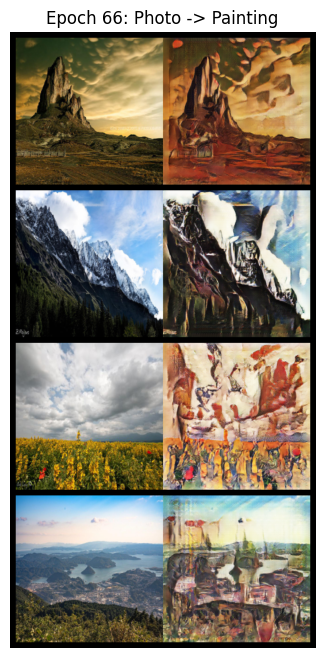

Epoch [65/150] Completed
  Generator Loss: 2.6700
  Cycle Consistency Loss: 0.1654
  Identity Loss: 0.2348
  Discriminator X Loss: 0.1931
  Discriminator Y Loss: 0.1778
Epoch [66/150]


Epoch [66/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.183, D_X_Loss=0.188, D_Y_Loss=0.36, Generator_Loss=2.46, Identity_Loss=0.199]  


Model parameters saved for epoch 66.


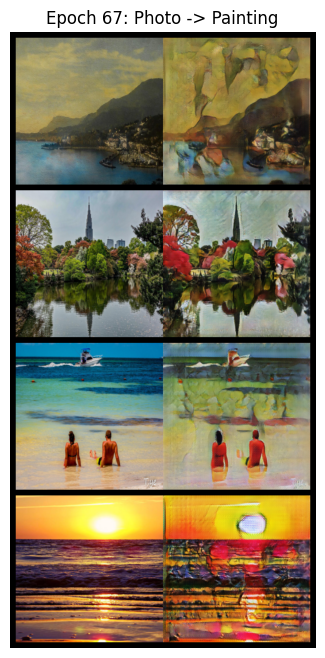

Epoch [66/150] Completed
  Generator Loss: 2.6680
  Cycle Consistency Loss: 0.1656
  Identity Loss: 0.2340
  Discriminator X Loss: 0.1938
  Discriminator Y Loss: 0.1772
Epoch [67/150]


Epoch [67/150]: 100%|██████████| 602/602 [09:41<00:00,  1.03it/s, Cycle_Loss=0.223, D_X_Loss=0.202, D_Y_Loss=0.205, Generator_Loss=3.14, Identity_Loss=0.288]  


Model parameters saved for epoch 67.


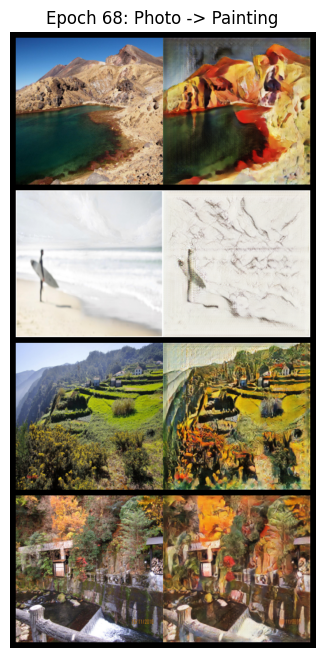

Epoch [67/150] Completed
  Generator Loss: 2.6587
  Cycle Consistency Loss: 0.1643
  Identity Loss: 0.2318
  Discriminator X Loss: 0.1938
  Discriminator Y Loss: 0.1765
Epoch [68/150]


Epoch [68/150]: 100%|██████████| 602/602 [09:34<00:00,  1.05it/s, Cycle_Loss=0.166, D_X_Loss=0.106, D_Y_Loss=0.0821, Generator_Loss=2.7, Identity_Loss=0.204] 


Model parameters saved for epoch 68.


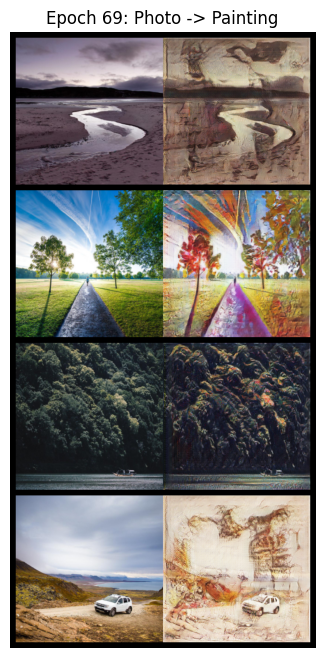

Epoch [68/150] Completed
  Generator Loss: 2.6623
  Cycle Consistency Loss: 0.1639
  Identity Loss: 0.2317
  Discriminator X Loss: 0.1938
  Discriminator Y Loss: 0.1762
Epoch [69/150]


Epoch [69/150]: 100%|██████████| 602/602 [09:29<00:00,  1.06it/s, Cycle_Loss=0.184, D_X_Loss=0.314, D_Y_Loss=0.139, Generator_Loss=2.49, Identity_Loss=0.209]  


Model parameters saved for epoch 69.


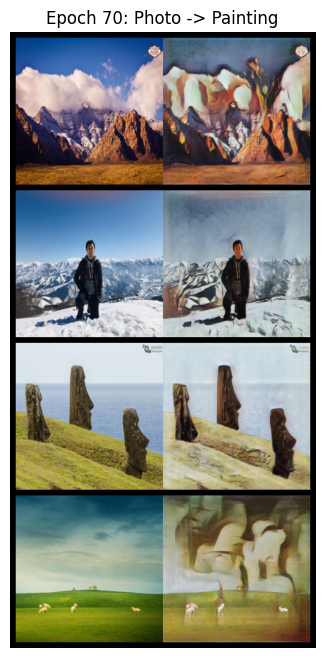

Epoch [69/150] Completed
  Generator Loss: 2.6764
  Cycle Consistency Loss: 0.1650
  Identity Loss: 0.2316
  Discriminator X Loss: 0.1931
  Discriminator Y Loss: 0.1734
Epoch [70/150]


Epoch [70/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.228, D_X_Loss=0.216, D_Y_Loss=0.135, Generator_Loss=3.46, Identity_Loss=0.248]  


Model parameters saved for epoch 70.


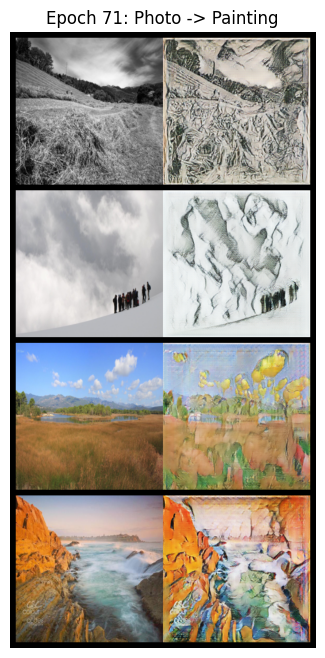

Epoch [70/150] Completed
  Generator Loss: 2.6492
  Cycle Consistency Loss: 0.1626
  Identity Loss: 0.2306
  Discriminator X Loss: 0.1924
  Discriminator Y Loss: 0.1753
Epoch [71/150]


Epoch [71/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.17, D_X_Loss=0.163, D_Y_Loss=0.111, Generator_Loss=2.84, Identity_Loss=0.293]  


Model parameters saved for epoch 71.


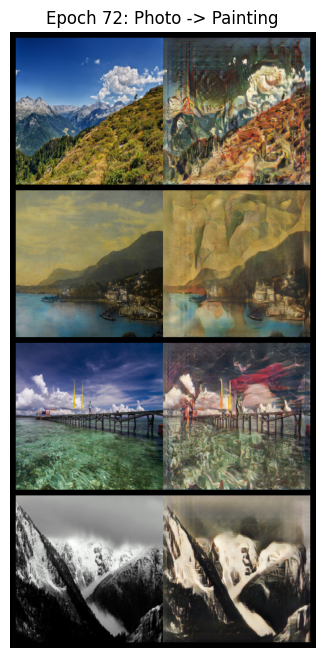

Epoch [71/150] Completed
  Generator Loss: 2.6475
  Cycle Consistency Loss: 0.1623
  Identity Loss: 0.2307
  Discriminator X Loss: 0.1927
  Discriminator Y Loss: 0.1743
Epoch [72/150]


Epoch [72/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.142, D_X_Loss=0.235, D_Y_Loss=0.225, Generator_Loss=2, Identity_Loss=0.149]    


Model parameters saved for epoch 72.


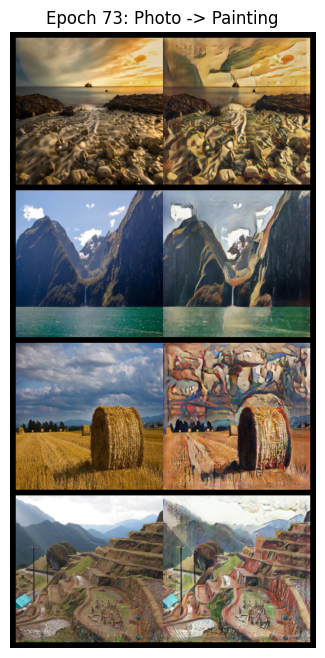

Epoch [72/150] Completed
  Generator Loss: 2.6459
  Cycle Consistency Loss: 0.1618
  Identity Loss: 0.2283
  Discriminator X Loss: 0.1933
  Discriminator Y Loss: 0.1707
Epoch [73/150]


Epoch [73/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.135, D_X_Loss=0.155, D_Y_Loss=0.0683, Generator_Loss=2.51, Identity_Loss=0.216]


Model parameters saved for epoch 73.


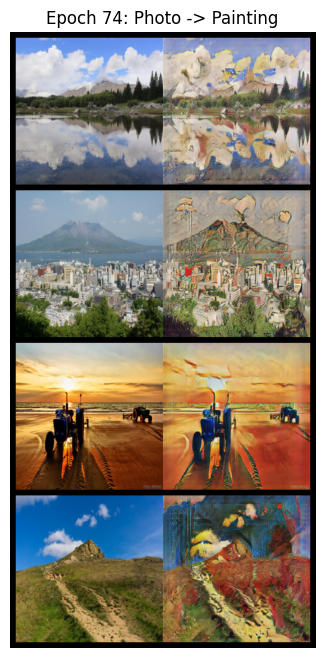

Epoch [73/150] Completed
  Generator Loss: 2.6372
  Cycle Consistency Loss: 0.1611
  Identity Loss: 0.2256
  Discriminator X Loss: 0.1945
  Discriminator Y Loss: 0.1712
Epoch [74/150]


Epoch [74/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.153, D_X_Loss=0.0931, D_Y_Loss=0.104, Generator_Loss=2.71, Identity_Loss=0.214] 


Model parameters saved for epoch 74.


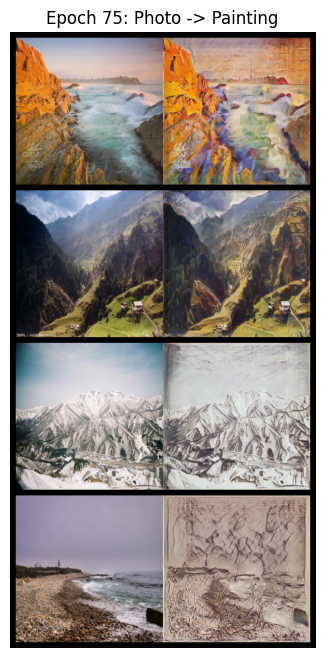

Epoch [74/150] Completed
  Generator Loss: 2.6397
  Cycle Consistency Loss: 0.1610
  Identity Loss: 0.2250
  Discriminator X Loss: 0.1929
  Discriminator Y Loss: 0.1702
Epoch [75/150]


Epoch [75/150]: 100%|██████████| 602/602 [09:25<00:00,  1.06it/s, Cycle_Loss=0.18, D_X_Loss=0.121, D_Y_Loss=0.0762, Generator_Loss=2.82, Identity_Loss=0.231] 


Model parameters saved for epoch 75.


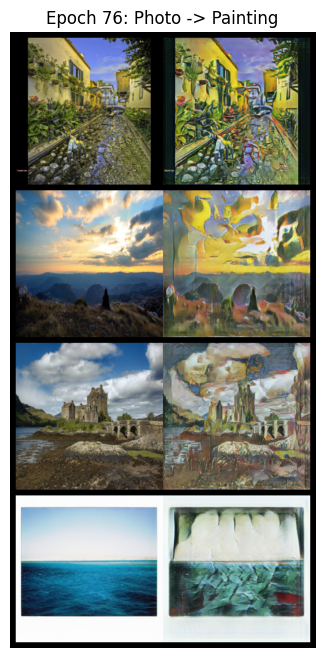

Epoch [75/150] Completed
  Generator Loss: 2.6625
  Cycle Consistency Loss: 0.1615
  Identity Loss: 0.2262
  Discriminator X Loss: 0.1900
  Discriminator Y Loss: 0.1682
Epoch [76/150]


Epoch [76/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.169, D_X_Loss=0.213, D_Y_Loss=0.268, Generator_Loss=3.05, Identity_Loss=0.224] 


Model parameters saved for epoch 76.


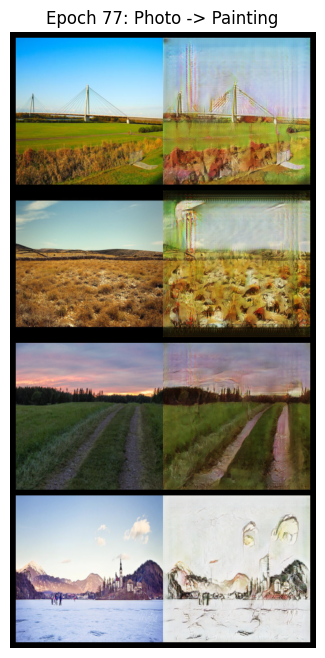

Epoch [76/150] Completed
  Generator Loss: 2.6688
  Cycle Consistency Loss: 0.1619
  Identity Loss: 0.2270
  Discriminator X Loss: 0.1911
  Discriminator Y Loss: 0.1670
Epoch [77/150]


Epoch [77/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.156, D_X_Loss=0.173, D_Y_Loss=0.11, Generator_Loss=2.52, Identity_Loss=0.213]  


Model parameters saved for epoch 77.


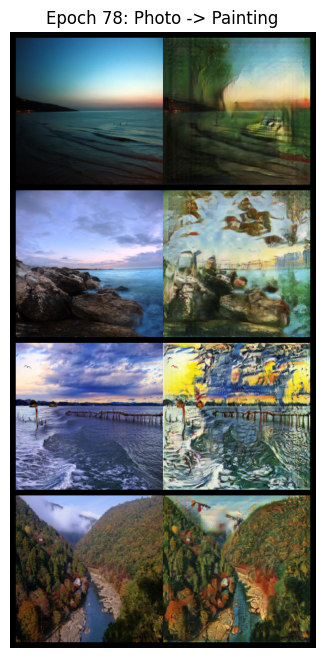

Epoch [77/150] Completed
  Generator Loss: 2.6536
  Cycle Consistency Loss: 0.1607
  Identity Loss: 0.2238
  Discriminator X Loss: 0.1923
  Discriminator Y Loss: 0.1663
Epoch [78/150]


Epoch [78/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.149, D_X_Loss=0.311, D_Y_Loss=0.212, Generator_Loss=2.5, Identity_Loss=0.395]  


Model parameters saved for epoch 78.


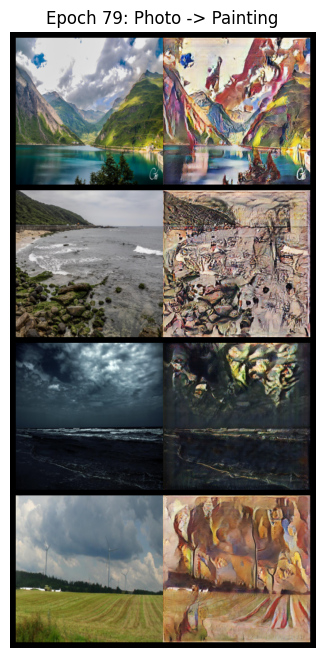

Epoch [78/150] Completed
  Generator Loss: 2.6395
  Cycle Consistency Loss: 0.1591
  Identity Loss: 0.2235
  Discriminator X Loss: 0.1930
  Discriminator Y Loss: 0.1650
Epoch [79/150]


Epoch [79/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.147, D_X_Loss=0.143, D_Y_Loss=0.187, Generator_Loss=2.26, Identity_Loss=0.207] 


Model parameters saved for epoch 79.


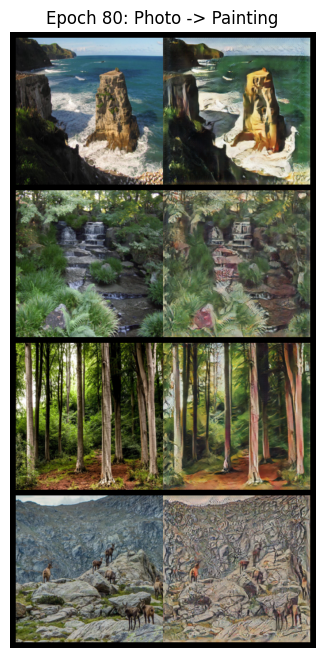

Epoch [79/150] Completed
  Generator Loss: 2.6456
  Cycle Consistency Loss: 0.1595
  Identity Loss: 0.2217
  Discriminator X Loss: 0.1903
  Discriminator Y Loss: 0.1637
Epoch [80/150]


Epoch [80/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.181, D_X_Loss=0.251, D_Y_Loss=0.196, Generator_Loss=2.5, Identity_Loss=0.237]   


Model parameters saved for epoch 80.


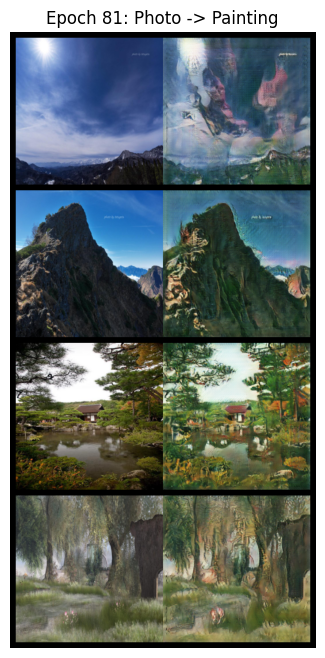

Epoch [80/150] Completed
  Generator Loss: 2.6364
  Cycle Consistency Loss: 0.1588
  Identity Loss: 0.2203
  Discriminator X Loss: 0.1933
  Discriminator Y Loss: 0.1664
Epoch [81/150]


Epoch [81/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.131, D_X_Loss=0.127, D_Y_Loss=0.112, Generator_Loss=2.64, Identity_Loss=0.185]  


Model parameters saved for epoch 81.


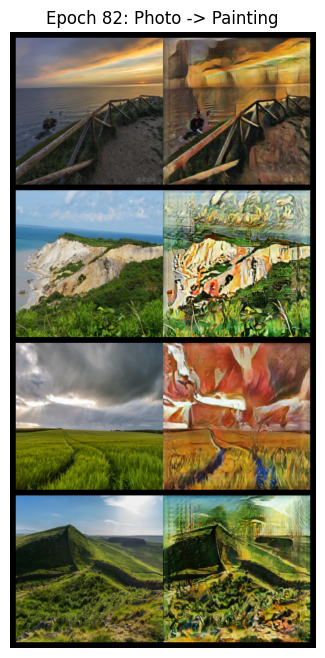

Epoch [81/150] Completed
  Generator Loss: 2.6432
  Cycle Consistency Loss: 0.1582
  Identity Loss: 0.2204
  Discriminator X Loss: 0.1927
  Discriminator Y Loss: 0.1599
Epoch [82/150]


Epoch [82/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.159, D_X_Loss=0.148, D_Y_Loss=0.205, Generator_Loss=2.73, Identity_Loss=0.218]  


Model parameters saved for epoch 82.


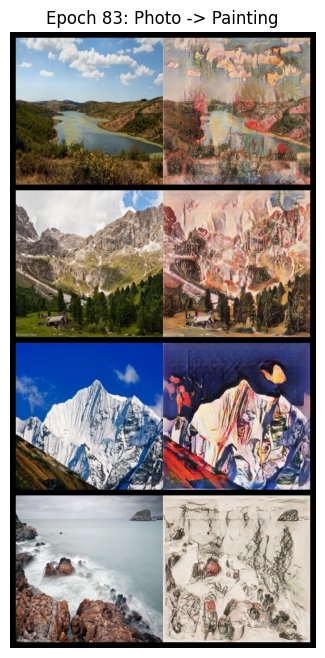

Epoch [82/150] Completed
  Generator Loss: 2.6447
  Cycle Consistency Loss: 0.1586
  Identity Loss: 0.2205
  Discriminator X Loss: 0.1900
  Discriminator Y Loss: 0.1620
Epoch [83/150]


Epoch [83/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.126, D_X_Loss=0.159, D_Y_Loss=0.184, Generator_Loss=2.59, Identity_Loss=0.197] 


Model parameters saved for epoch 83.


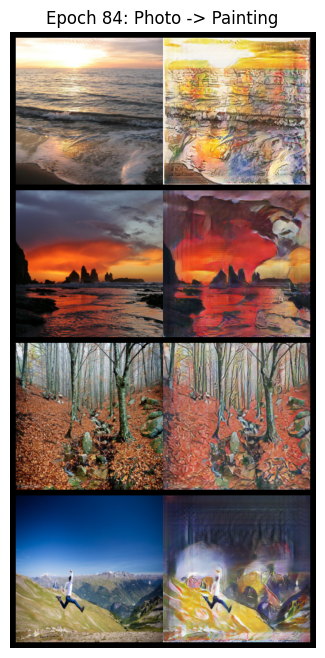

Epoch [83/150] Completed
  Generator Loss: 2.6501
  Cycle Consistency Loss: 0.1589
  Identity Loss: 0.2197
  Discriminator X Loss: 0.1918
  Discriminator Y Loss: 0.1586
Epoch [84/150]


Epoch [84/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.161, D_X_Loss=0.273, D_Y_Loss=0.161, Generator_Loss=2.27, Identity_Loss=0.269] 


Model parameters saved for epoch 84.


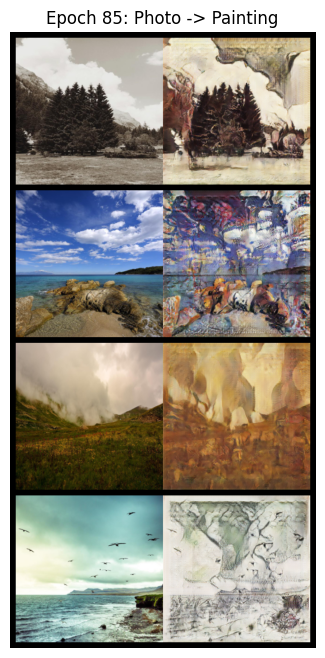

Epoch [84/150] Completed
  Generator Loss: 2.6632
  Cycle Consistency Loss: 0.1589
  Identity Loss: 0.2202
  Discriminator X Loss: 0.1919
  Discriminator Y Loss: 0.1559
Epoch [85/150]


Epoch [85/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.161, D_X_Loss=0.287, D_Y_Loss=0.252, Generator_Loss=2.61, Identity_Loss=0.213] 


Model parameters saved for epoch 85.


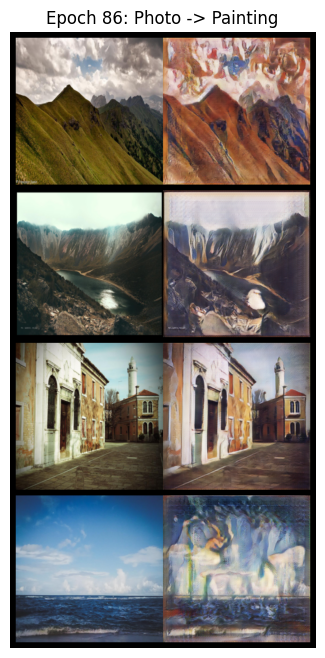

Epoch [85/150] Completed
  Generator Loss: 2.6366
  Cycle Consistency Loss: 0.1567
  Identity Loss: 0.2180
  Discriminator X Loss: 0.1929
  Discriminator Y Loss: 0.1580
Epoch [86/150]


Epoch [86/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.109, D_X_Loss=0.224, D_Y_Loss=0.119, Generator_Loss=2.39, Identity_Loss=0.142]  


Model parameters saved for epoch 86.


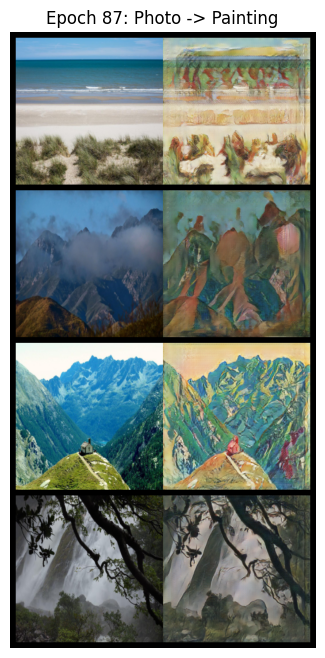

Epoch [86/150] Completed
  Generator Loss: 2.6220
  Cycle Consistency Loss: 0.1560
  Identity Loss: 0.2177
  Discriminator X Loss: 0.1924
  Discriminator Y Loss: 0.1598
Epoch [87/150]


Epoch [87/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.162, D_X_Loss=0.235, D_Y_Loss=0.228, Generator_Loss=2.63, Identity_Loss=0.229]  


Model parameters saved for epoch 87.


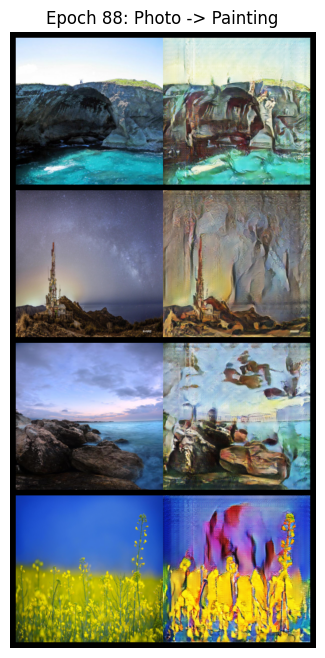

Epoch [87/150] Completed
  Generator Loss: 2.6556
  Cycle Consistency Loss: 0.1572
  Identity Loss: 0.2190
  Discriminator X Loss: 0.1902
  Discriminator Y Loss: 0.1555
Epoch [88/150]


Epoch [88/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.181, D_X_Loss=0.167, D_Y_Loss=0.0931, Generator_Loss=2.94, Identity_Loss=0.178] 


Model parameters saved for epoch 88.


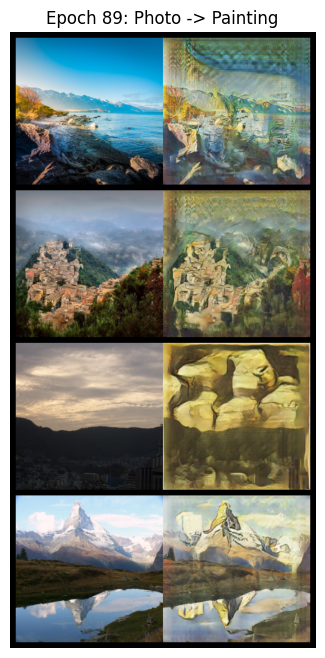

Epoch [88/150] Completed
  Generator Loss: 2.6563
  Cycle Consistency Loss: 0.1575
  Identity Loss: 0.2166
  Discriminator X Loss: 0.1919
  Discriminator Y Loss: 0.1530
Epoch [89/150]


Epoch [89/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.152, D_X_Loss=0.204, D_Y_Loss=0.193, Generator_Loss=2.46, Identity_Loss=0.234]  


Model parameters saved for epoch 89.


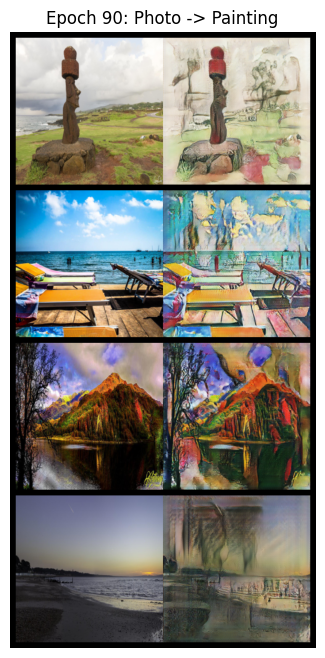

Epoch [89/150] Completed
  Generator Loss: 2.6361
  Cycle Consistency Loss: 0.1556
  Identity Loss: 0.2146
  Discriminator X Loss: 0.1917
  Discriminator Y Loss: 0.1543
Epoch [90/150]


Epoch [90/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.125, D_X_Loss=0.205, D_Y_Loss=0.084, Generator_Loss=2.32, Identity_Loss=0.246] 


Model parameters saved for epoch 90.


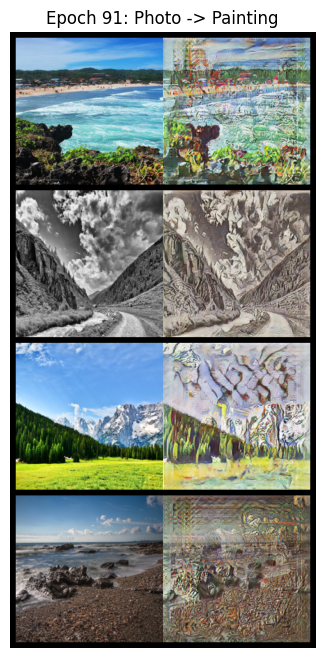

Epoch [90/150] Completed
  Generator Loss: 2.6377
  Cycle Consistency Loss: 0.1560
  Identity Loss: 0.2163
  Discriminator X Loss: 0.1906
  Discriminator Y Loss: 0.1559
Epoch [91/150]


Epoch [91/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.16, D_X_Loss=0.09, D_Y_Loss=0.0863, Generator_Loss=2.93, Identity_Loss=0.219]   


Model parameters saved for epoch 91.


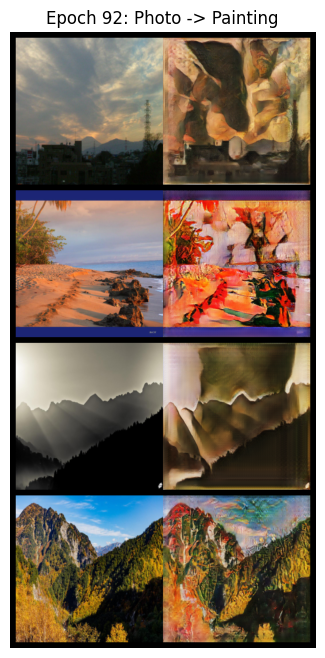

Epoch [91/150] Completed
  Generator Loss: 2.6643
  Cycle Consistency Loss: 0.1564
  Identity Loss: 0.2153
  Discriminator X Loss: 0.1879
  Discriminator Y Loss: 0.1500
Epoch [92/150]


Epoch [92/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.156, D_X_Loss=0.204, D_Y_Loss=0.182, Generator_Loss=2.24, Identity_Loss=0.186]  


Model parameters saved for epoch 92.


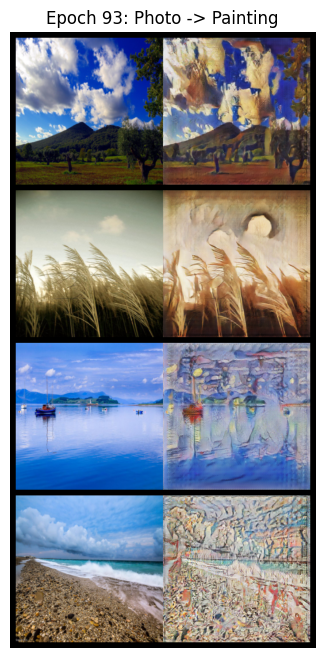

Epoch [92/150] Completed
  Generator Loss: 2.6554
  Cycle Consistency Loss: 0.1560
  Identity Loss: 0.2154
  Discriminator X Loss: 0.1906
  Discriminator Y Loss: 0.1504
Epoch [93/150]


Epoch [93/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.193, D_X_Loss=0.146, D_Y_Loss=0.16, Generator_Loss=2.78, Identity_Loss=0.24]   


Model parameters saved for epoch 93.


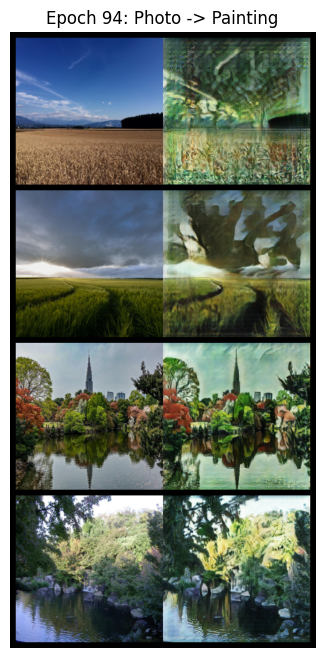

Epoch [93/150] Completed
  Generator Loss: 2.6695
  Cycle Consistency Loss: 0.1565
  Identity Loss: 0.2147
  Discriminator X Loss: 0.1862
  Discriminator Y Loss: 0.1478
Epoch [94/150]


Epoch [94/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.158, D_X_Loss=0.0942, D_Y_Loss=0.0658, Generator_Loss=2.88, Identity_Loss=0.151]


Model parameters saved for epoch 94.


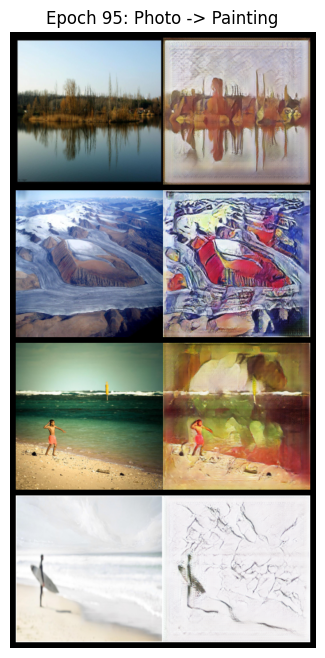

Epoch [94/150] Completed
  Generator Loss: 2.6327
  Cycle Consistency Loss: 0.1539
  Identity Loss: 0.2137
  Discriminator X Loss: 0.1907
  Discriminator Y Loss: 0.1523
Epoch [95/150]


Epoch [95/150]: 100%|██████████| 602/602 [09:26<00:00,  1.06it/s, Cycle_Loss=0.152, D_X_Loss=0.185, D_Y_Loss=0.168, Generator_Loss=2.79, Identity_Loss=0.235]  


Model parameters saved for epoch 95.


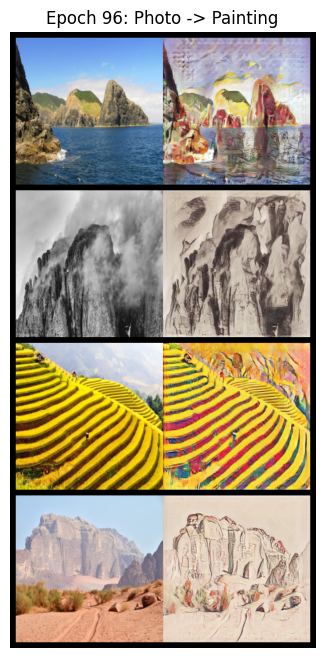

Epoch [95/150] Completed
  Generator Loss: 2.6572
  Cycle Consistency Loss: 0.1548
  Identity Loss: 0.2119
  Discriminator X Loss: 0.1909
  Discriminator Y Loss: 0.1452
Epoch [96/150]


Epoch [96/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.132, D_X_Loss=0.114, D_Y_Loss=0.169, Generator_Loss=2.09, Identity_Loss=0.144]  


Model parameters saved for epoch 96.


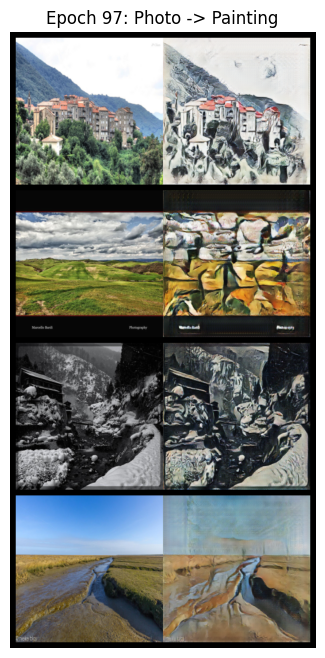

Epoch [96/150] Completed
  Generator Loss: 2.6624
  Cycle Consistency Loss: 0.1554
  Identity Loss: 0.2118
  Discriminator X Loss: 0.1879
  Discriminator Y Loss: 0.1455
Epoch [97/150]


Epoch [97/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.185, D_X_Loss=0.167, D_Y_Loss=0.0938, Generator_Loss=2.87, Identity_Loss=0.217] 


Model parameters saved for epoch 97.


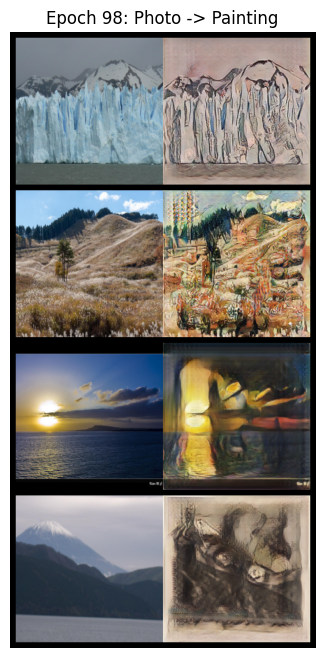

Epoch [97/150] Completed
  Generator Loss: 2.6441
  Cycle Consistency Loss: 0.1533
  Identity Loss: 0.2115
  Discriminator X Loss: 0.1914
  Discriminator Y Loss: 0.1436
Epoch [98/150]


Epoch [98/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.168, D_X_Loss=0.154, D_Y_Loss=0.0963, Generator_Loss=2.75, Identity_Loss=0.211] 


Model parameters saved for epoch 98.


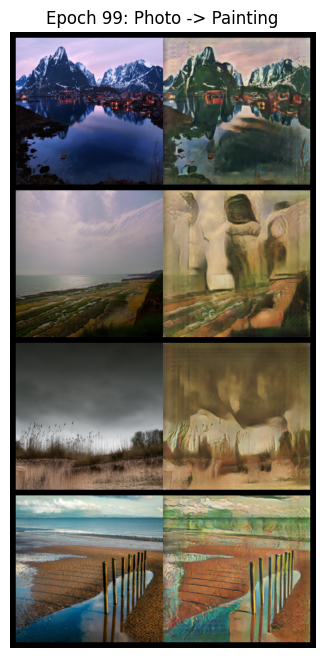

Epoch [98/150] Completed
  Generator Loss: 2.6445
  Cycle Consistency Loss: 0.1538
  Identity Loss: 0.2109
  Discriminator X Loss: 0.1897
  Discriminator Y Loss: 0.1452
Epoch [99/150]


Epoch [99/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.143, D_X_Loss=0.257, D_Y_Loss=0.233, Generator_Loss=2.21, Identity_Loss=0.243] 


Model parameters saved for epoch 99.


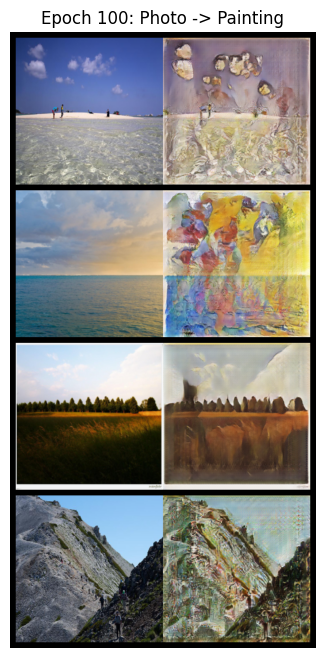

Epoch [99/150] Completed
  Generator Loss: 2.6585
  Cycle Consistency Loss: 0.1545
  Identity Loss: 0.2111
  Discriminator X Loss: 0.1899
  Discriminator Y Loss: 0.1444
Epoch [100/150]


Epoch [100/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.138, D_X_Loss=0.203, D_Y_Loss=0.0706, Generator_Loss=2.39, Identity_Loss=0.227] 


Model parameters saved for epoch 100.


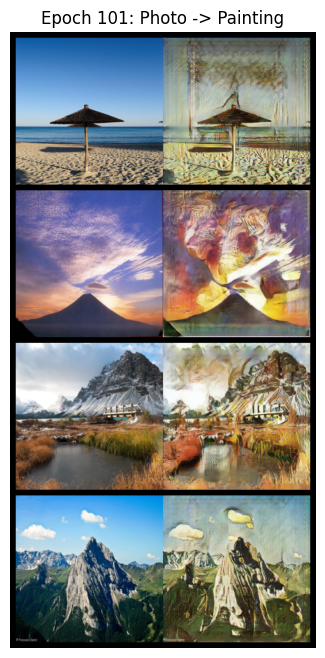

Epoch [100/150] Completed
  Generator Loss: 2.6484
  Cycle Consistency Loss: 0.1534
  Identity Loss: 0.2124
  Discriminator X Loss: 0.1907
  Discriminator Y Loss: 0.1431
Epoch [101/150]


Epoch [101/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.112, D_X_Loss=0.24, D_Y_Loss=0.117, Generator_Loss=2.26, Identity_Loss=0.212]   


Model parameters saved for epoch 101.


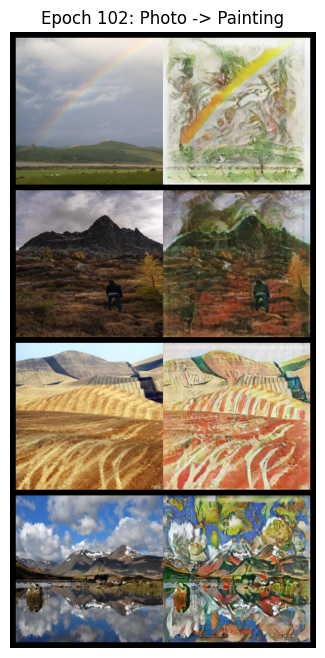

Epoch [101/150] Completed
  Generator Loss: 2.6410
  Cycle Consistency Loss: 0.1526
  Identity Loss: 0.2091
  Discriminator X Loss: 0.1917
  Discriminator Y Loss: 0.1428
Epoch [102/150]


Epoch [102/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.204, D_X_Loss=0.209, D_Y_Loss=0.132, Generator_Loss=3.12, Identity_Loss=0.236]  


Model parameters saved for epoch 102.


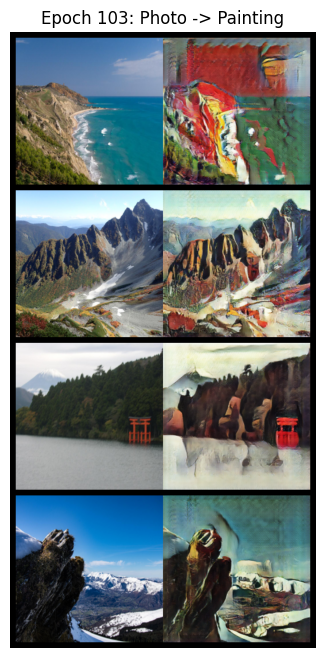

Epoch [102/150] Completed
  Generator Loss: 2.6362
  Cycle Consistency Loss: 0.1523
  Identity Loss: 0.2086
  Discriminator X Loss: 0.1899
  Discriminator Y Loss: 0.1441
Epoch [103/150]


Epoch [103/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.138, D_X_Loss=0.312, D_Y_Loss=0.0885, Generator_Loss=2.2, Identity_Loss=0.203] 


Model parameters saved for epoch 103.


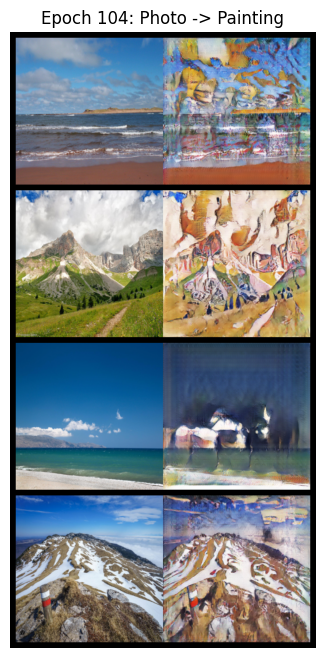

Epoch [103/150] Completed
  Generator Loss: 2.6582
  Cycle Consistency Loss: 0.1536
  Identity Loss: 0.2075
  Discriminator X Loss: 0.1892
  Discriminator Y Loss: 0.1419
Epoch [104/150]


Epoch [104/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.15, D_X_Loss=0.154, D_Y_Loss=0.102, Generator_Loss=2.49, Identity_Loss=0.208]  


Model parameters saved for epoch 104.


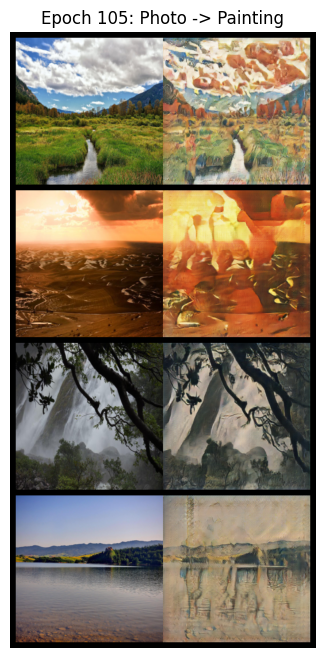

Epoch [104/150] Completed
  Generator Loss: 2.6295
  Cycle Consistency Loss: 0.1511
  Identity Loss: 0.2051
  Discriminator X Loss: 0.1910
  Discriminator Y Loss: 0.1403
Epoch [105/150]


Epoch [105/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.131, D_X_Loss=0.216, D_Y_Loss=0.114, Generator_Loss=2.27, Identity_Loss=0.202]  


Model parameters saved for epoch 105.


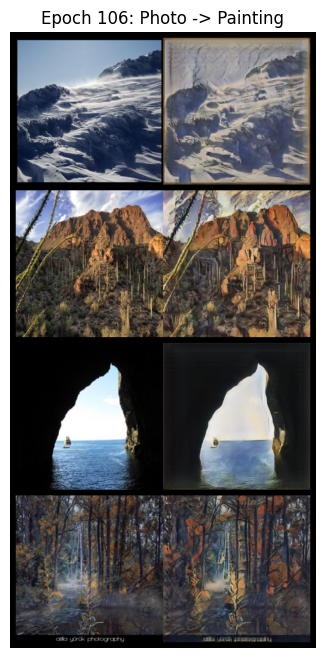

Epoch [105/150] Completed
  Generator Loss: 2.6526
  Cycle Consistency Loss: 0.1516
  Identity Loss: 0.2087
  Discriminator X Loss: 0.1912
  Discriminator Y Loss: 0.1362
Epoch [106/150]


Epoch [106/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.135, D_X_Loss=0.037, D_Y_Loss=0.0604, Generator_Loss=3.05, Identity_Loss=0.191] 


Model parameters saved for epoch 106.


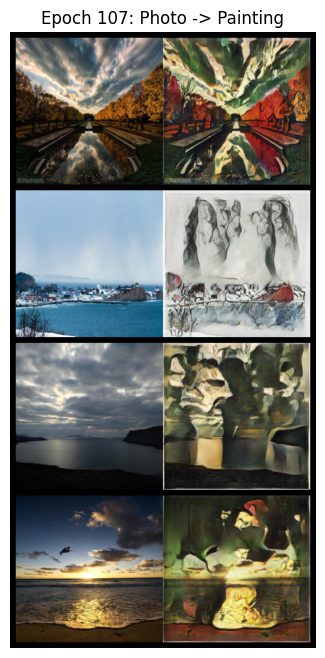

Epoch [106/150] Completed
  Generator Loss: 2.6245
  Cycle Consistency Loss: 0.1504
  Identity Loss: 0.2048
  Discriminator X Loss: 0.1917
  Discriminator Y Loss: 0.1382
Epoch [107/150]


Epoch [107/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.153, D_X_Loss=0.109, D_Y_Loss=0.107, Generator_Loss=2.78, Identity_Loss=0.222]  


Model parameters saved for epoch 107.


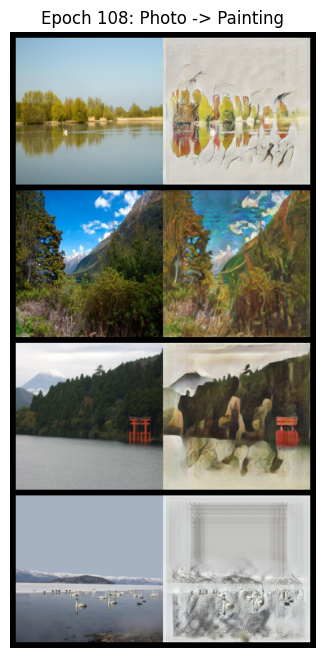

Epoch [107/150] Completed
  Generator Loss: 2.6522
  Cycle Consistency Loss: 0.1517
  Identity Loss: 0.2076
  Discriminator X Loss: 0.1896
  Discriminator Y Loss: 0.1388
Epoch [108/150]


Epoch [108/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.127, D_X_Loss=0.238, D_Y_Loss=0.0809, Generator_Loss=2.17, Identity_Loss=0.146]


Model parameters saved for epoch 108.


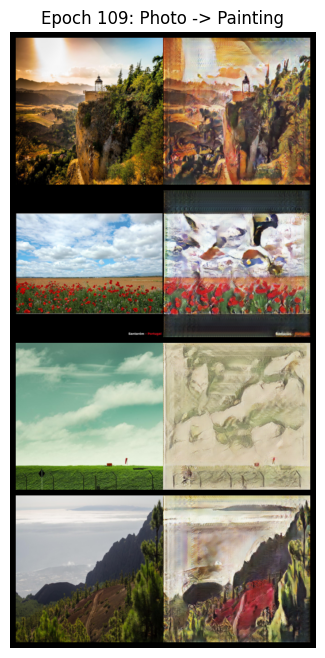

Epoch [108/150] Completed
  Generator Loss: 2.6247
  Cycle Consistency Loss: 0.1504
  Identity Loss: 0.2035
  Discriminator X Loss: 0.1915
  Discriminator Y Loss: 0.1394
Epoch [109/150]


Epoch [109/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.147, D_X_Loss=0.217, D_Y_Loss=0.171, Generator_Loss=2.28, Identity_Loss=0.214]  


Model parameters saved for epoch 109.


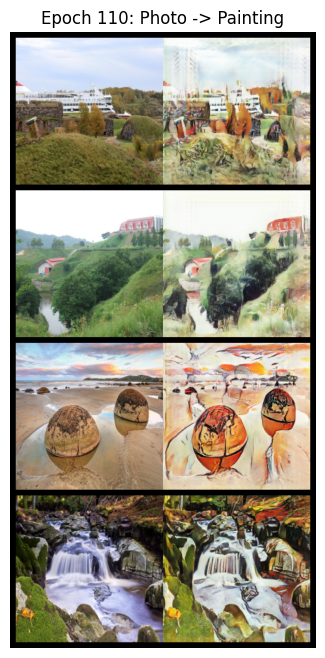

Epoch [109/150] Completed
  Generator Loss: 2.6302
  Cycle Consistency Loss: 0.1505
  Identity Loss: 0.2032
  Discriminator X Loss: 0.1925
  Discriminator Y Loss: 0.1382
Epoch [110/150]


Epoch [110/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.143, D_X_Loss=0.2, D_Y_Loss=0.146, Generator_Loss=2.43, Identity_Loss=0.213]   


Model parameters saved for epoch 110.


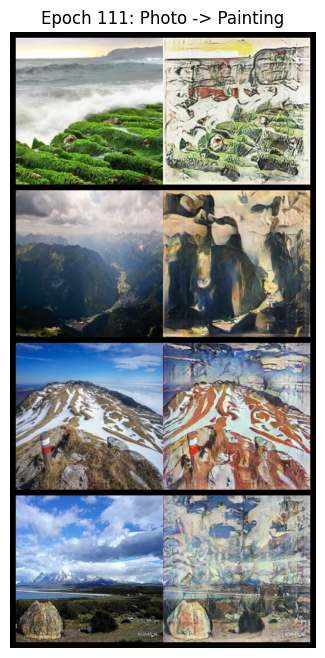

Epoch [110/150] Completed
  Generator Loss: 2.6568
  Cycle Consistency Loss: 0.1521
  Identity Loss: 0.2049
  Discriminator X Loss: 0.1903
  Discriminator Y Loss: 0.1364
Epoch [111/150]


Epoch [111/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.195, D_X_Loss=0.245, D_Y_Loss=0.099, Generator_Loss=3.01, Identity_Loss=0.274]  


Model parameters saved for epoch 111.


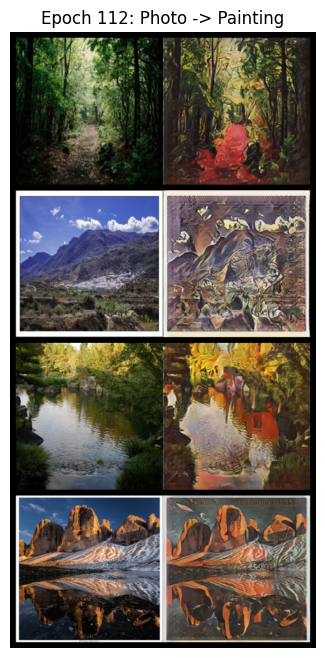

Epoch [111/150] Completed
  Generator Loss: 2.6370
  Cycle Consistency Loss: 0.1500
  Identity Loss: 0.2026
  Discriminator X Loss: 0.1902
  Discriminator Y Loss: 0.1343
Epoch [112/150]


Epoch [112/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.135, D_X_Loss=0.257, D_Y_Loss=0.142, Generator_Loss=2.32, Identity_Loss=0.256] 


Model parameters saved for epoch 112.


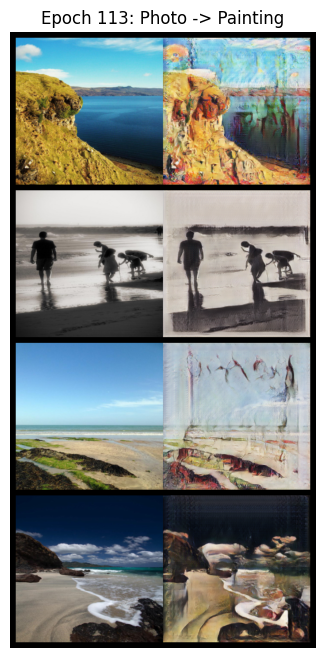

Epoch [112/150] Completed
  Generator Loss: 2.6182
  Cycle Consistency Loss: 0.1497
  Identity Loss: 0.2027
  Discriminator X Loss: 0.1917
  Discriminator Y Loss: 0.1410
Epoch [113/150]


Epoch [113/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.158, D_X_Loss=0.149, D_Y_Loss=0.127, Generator_Loss=2.73, Identity_Loss=0.291]  


Model parameters saved for epoch 113.


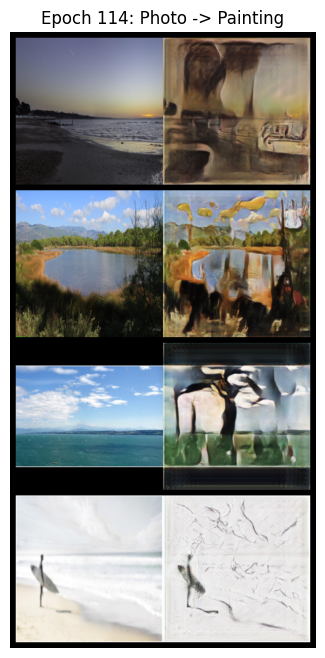

Epoch [113/150] Completed
  Generator Loss: 2.6158
  Cycle Consistency Loss: 0.1483
  Identity Loss: 0.2011
  Discriminator X Loss: 0.1921
  Discriminator Y Loss: 0.1338
Epoch [114/150]


Epoch [114/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.13, D_X_Loss=0.137, D_Y_Loss=0.28, Generator_Loss=2.5, Identity_Loss=0.164]     


Model parameters saved for epoch 114.


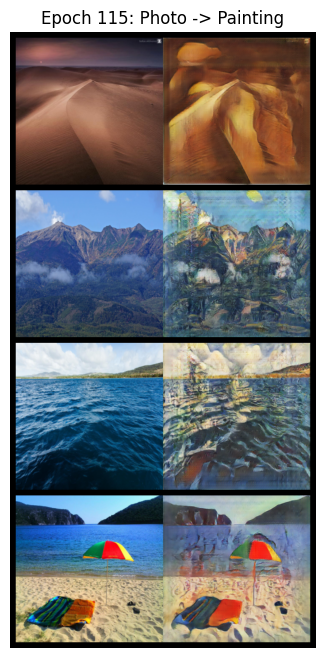

Epoch [114/150] Completed
  Generator Loss: 2.6337
  Cycle Consistency Loss: 0.1492
  Identity Loss: 0.2024
  Discriminator X Loss: 0.1915
  Discriminator Y Loss: 0.1337
Epoch [115/150]


Epoch [115/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.164, D_X_Loss=0.135, D_Y_Loss=0.083, Generator_Loss=3.21, Identity_Loss=0.236] 


Model parameters saved for epoch 115.


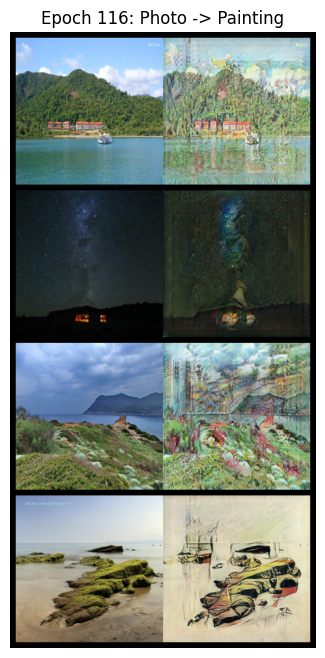

Epoch [115/150] Completed
  Generator Loss: 2.6254
  Cycle Consistency Loss: 0.1489
  Identity Loss: 0.2012
  Discriminator X Loss: 0.1915
  Discriminator Y Loss: 0.1349
Epoch [116/150]


Epoch [116/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.149, D_X_Loss=0.32, D_Y_Loss=0.238, Generator_Loss=2.65, Identity_Loss=0.331]   


Model parameters saved for epoch 116.


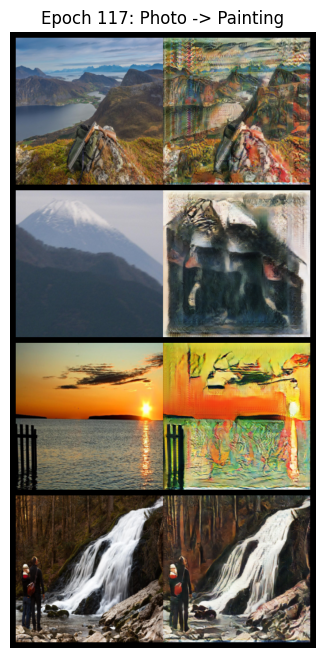

Epoch [116/150] Completed
  Generator Loss: 2.6293
  Cycle Consistency Loss: 0.1489
  Identity Loss: 0.1999
  Discriminator X Loss: 0.1903
  Discriminator Y Loss: 0.1329
Epoch [117/150]


Epoch [117/150]: 100%|██████████| 602/602 [09:27<00:00,  1.06it/s, Cycle_Loss=0.127, D_X_Loss=0.156, D_Y_Loss=0.13, Generator_Loss=2.19, Identity_Loss=0.173]   


Model parameters saved for epoch 117.


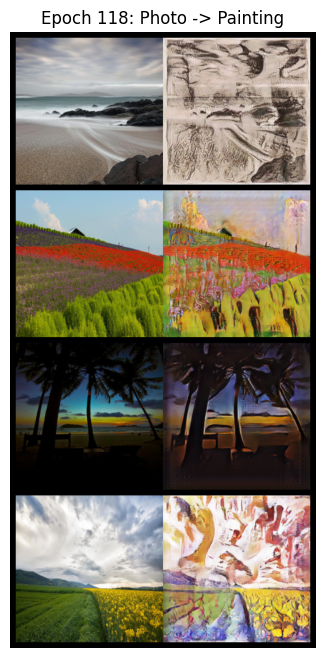

Epoch [117/150] Completed
  Generator Loss: 2.6080
  Cycle Consistency Loss: 0.1479
  Identity Loss: 0.1986
  Discriminator X Loss: 0.1919
  Discriminator Y Loss: 0.1364
Epoch [118/150]


Epoch [118/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.159, D_X_Loss=0.181, D_Y_Loss=0.258, Generator_Loss=2.69, Identity_Loss=0.261]  


Model parameters saved for epoch 118.


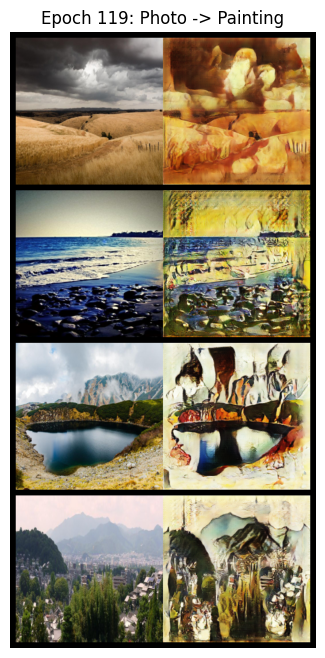

Epoch [118/150] Completed
  Generator Loss: 2.6115
  Cycle Consistency Loss: 0.1472
  Identity Loss: 0.1974
  Discriminator X Loss: 0.1921
  Discriminator Y Loss: 0.1329
Epoch [119/150]


Epoch [119/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.156, D_X_Loss=0.137, D_Y_Loss=0.201, Generator_Loss=2.62, Identity_Loss=0.191]  


Model parameters saved for epoch 119.


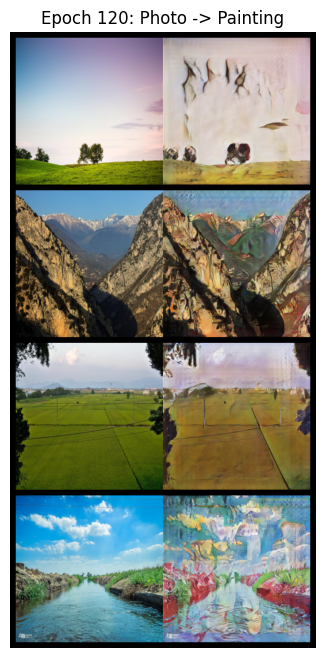

Epoch [119/150] Completed
  Generator Loss: 2.5790
  Cycle Consistency Loss: 0.1464
  Identity Loss: 0.1969
  Discriminator X Loss: 0.1935
  Discriminator Y Loss: 0.1390
Epoch [120/150]


Epoch [120/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.11, D_X_Loss=0.138, D_Y_Loss=0.0803, Generator_Loss=2.31, Identity_Loss=0.196]  


Model parameters saved for epoch 120.


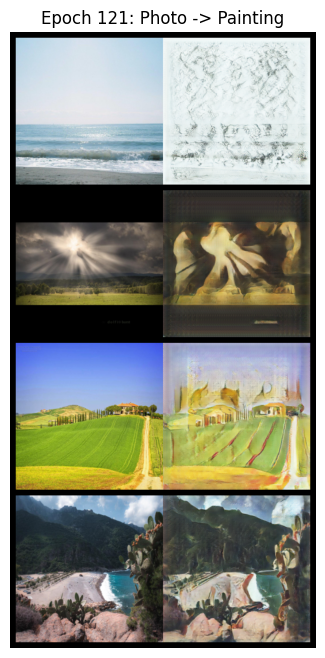

Epoch [120/150] Completed
  Generator Loss: 2.6229
  Cycle Consistency Loss: 0.1482
  Identity Loss: 0.1985
  Discriminator X Loss: 0.1914
  Discriminator Y Loss: 0.1356
Epoch [121/150]


Epoch [121/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.16, D_X_Loss=0.164, D_Y_Loss=0.156, Generator_Loss=2.66, Identity_Loss=0.205]   


Model parameters saved for epoch 121.


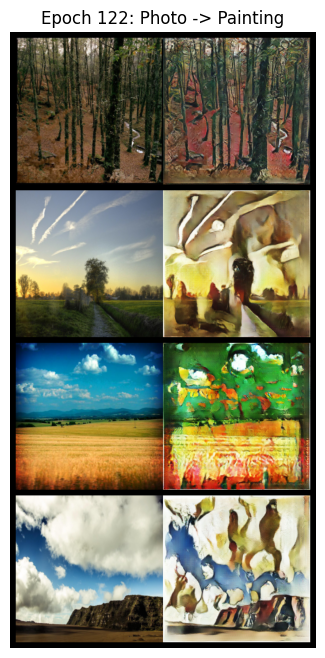

Epoch [121/150] Completed
  Generator Loss: 2.6071
  Cycle Consistency Loss: 0.1466
  Identity Loss: 0.1967
  Discriminator X Loss: 0.1942
  Discriminator Y Loss: 0.1309
Epoch [122/150]


Epoch [122/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.127, D_X_Loss=0.124, D_Y_Loss=0.107, Generator_Loss=2.43, Identity_Loss=0.165]  


Model parameters saved for epoch 122.


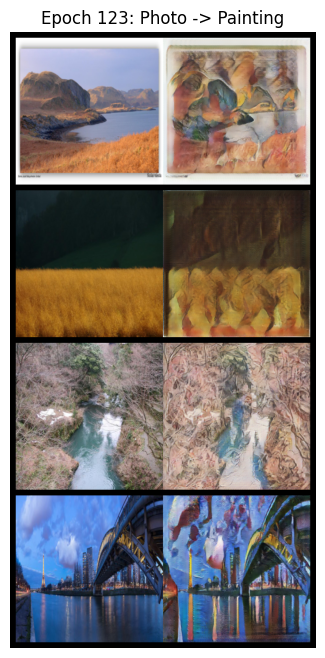

Epoch [122/150] Completed
  Generator Loss: 2.6108
  Cycle Consistency Loss: 0.1466
  Identity Loss: 0.1961
  Discriminator X Loss: 0.1894
  Discriminator Y Loss: 0.1333
Epoch [123/150]


Epoch [123/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.133, D_X_Loss=0.113, D_Y_Loss=0.212, Generator_Loss=2.87, Identity_Loss=0.153]  


Model parameters saved for epoch 123.


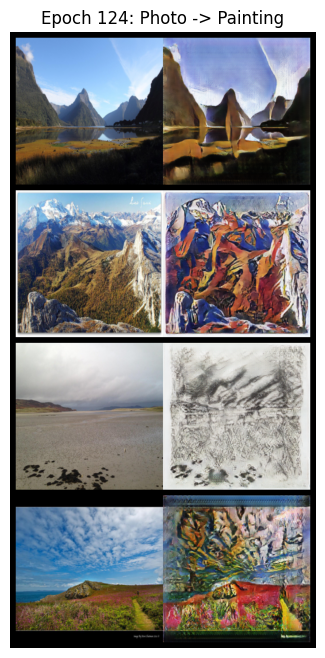

Epoch [123/150] Completed
  Generator Loss: 2.6011
  Cycle Consistency Loss: 0.1465
  Identity Loss: 0.1975
  Discriminator X Loss: 0.1894
  Discriminator Y Loss: 0.1366
Epoch [124/150]


Epoch [124/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.171, D_X_Loss=0.125, D_Y_Loss=0.117, Generator_Loss=3.17, Identity_Loss=0.213] 


Model parameters saved for epoch 124.


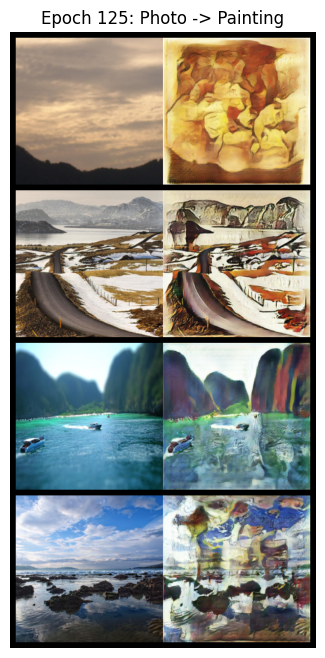

Epoch [124/150] Completed
  Generator Loss: 2.6018
  Cycle Consistency Loss: 0.1461
  Identity Loss: 0.1953
  Discriminator X Loss: 0.1909
  Discriminator Y Loss: 0.1350
Epoch [125/150]


Epoch [125/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.146, D_X_Loss=0.132, D_Y_Loss=0.106, Generator_Loss=2.39, Identity_Loss=0.159] 


Model parameters saved for epoch 125.


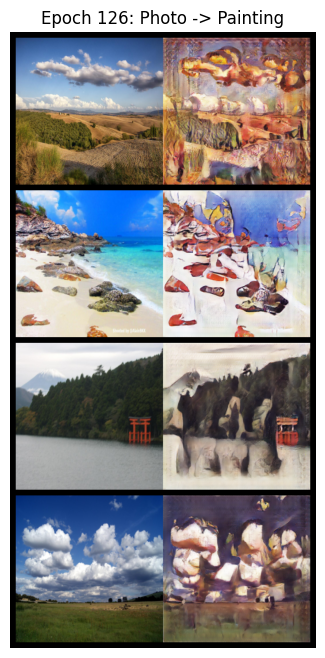

Epoch [125/150] Completed
  Generator Loss: 2.5876
  Cycle Consistency Loss: 0.1454
  Identity Loss: 0.1948
  Discriminator X Loss: 0.1938
  Discriminator Y Loss: 0.1376
Epoch [126/150]


Epoch [126/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.198, D_X_Loss=0.173, D_Y_Loss=0.25, Generator_Loss=2.81, Identity_Loss=0.219]  


Model parameters saved for epoch 126.


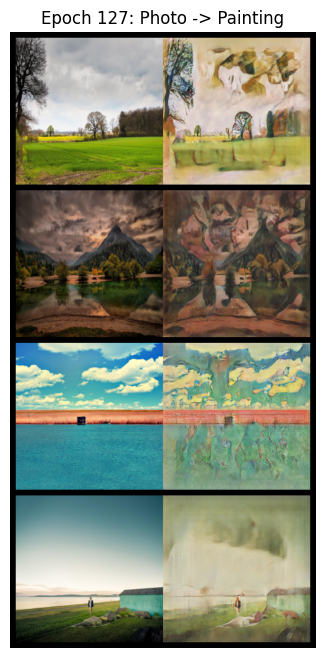

Epoch [126/150] Completed
  Generator Loss: 2.5769
  Cycle Consistency Loss: 0.1455
  Identity Loss: 0.1942
  Discriminator X Loss: 0.1931
  Discriminator Y Loss: 0.1366
Epoch [127/150]


Epoch [127/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.131, D_X_Loss=0.198, D_Y_Loss=0.121, Generator_Loss=2.5, Identity_Loss=0.175]  


Model parameters saved for epoch 127.


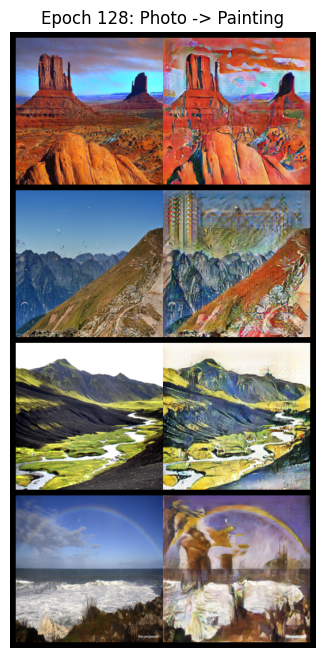

Epoch [127/150] Completed
  Generator Loss: 2.5891
  Cycle Consistency Loss: 0.1459
  Identity Loss: 0.1944
  Discriminator X Loss: 0.1933
  Discriminator Y Loss: 0.1341
Epoch [128/150]


Epoch [128/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.159, D_X_Loss=0.375, D_Y_Loss=0.235, Generator_Loss=2.75, Identity_Loss=0.279] 


Model parameters saved for epoch 128.


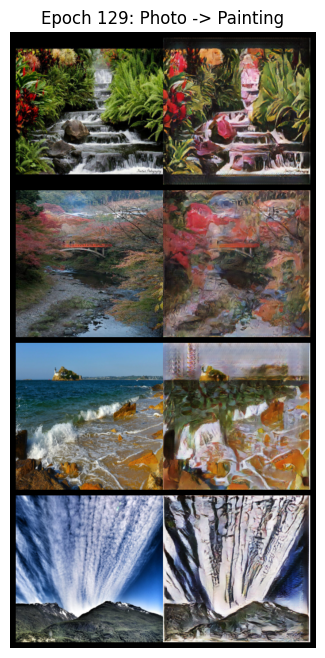

Epoch [128/150] Completed
  Generator Loss: 2.5748
  Cycle Consistency Loss: 0.1443
  Identity Loss: 0.1935
  Discriminator X Loss: 0.1938
  Discriminator Y Loss: 0.1359
Epoch [129/150]


Epoch [129/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.163, D_X_Loss=0.255, D_Y_Loss=0.0923, Generator_Loss=2.99, Identity_Loss=0.206] 


Model parameters saved for epoch 129.


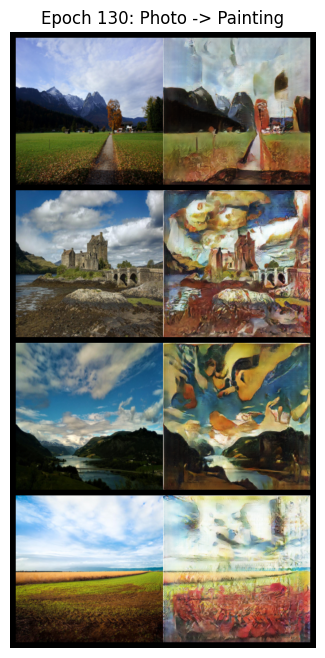

Epoch [129/150] Completed
  Generator Loss: 2.5858
  Cycle Consistency Loss: 0.1456
  Identity Loss: 0.1940
  Discriminator X Loss: 0.1927
  Discriminator Y Loss: 0.1382
Epoch [130/150]


Epoch [130/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.147, D_X_Loss=0.181, D_Y_Loss=0.136, Generator_Loss=2.56, Identity_Loss=0.18]   


Model parameters saved for epoch 130.


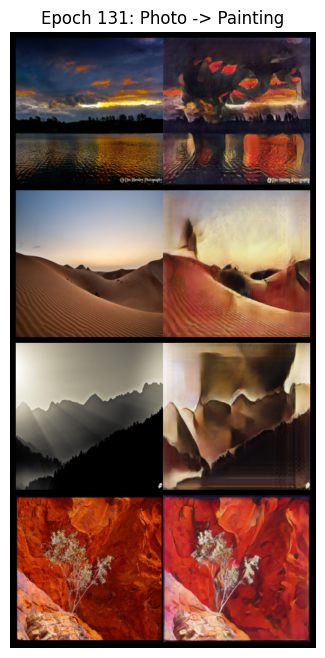

Epoch [130/150] Completed
  Generator Loss: 2.5648
  Cycle Consistency Loss: 0.1440
  Identity Loss: 0.1920
  Discriminator X Loss: 0.1931
  Discriminator Y Loss: 0.1346
Epoch [131/150]


Epoch [131/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.15, D_X_Loss=0.183, D_Y_Loss=0.0731, Generator_Loss=2.81, Identity_Loss=0.164]  


Model parameters saved for epoch 131.


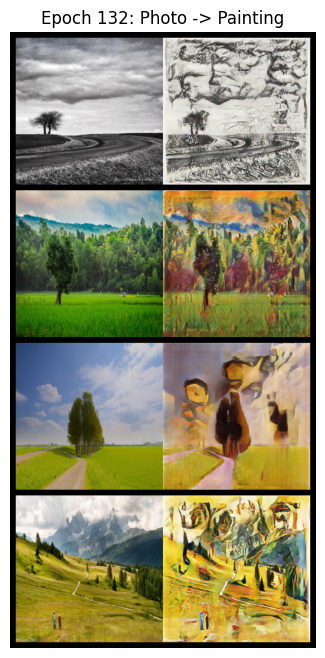

Epoch [131/150] Completed
  Generator Loss: 2.5707
  Cycle Consistency Loss: 0.1446
  Identity Loss: 0.1917
  Discriminator X Loss: 0.1944
  Discriminator Y Loss: 0.1342
Epoch [132/150]


Epoch [132/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.151, D_X_Loss=0.19, D_Y_Loss=0.222, Generator_Loss=2.81, Identity_Loss=0.196]  


Model parameters saved for epoch 132.


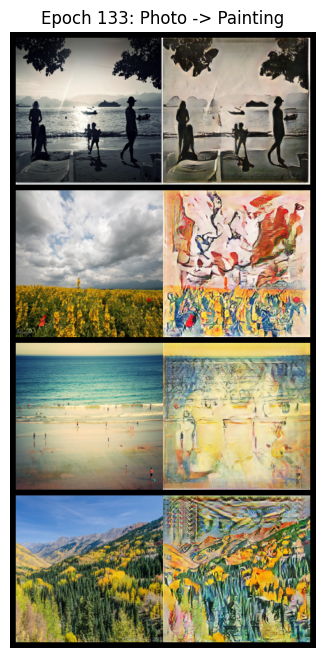

Epoch [132/150] Completed
  Generator Loss: 2.5909
  Cycle Consistency Loss: 0.1449
  Identity Loss: 0.1920
  Discriminator X Loss: 0.1924
  Discriminator Y Loss: 0.1330
Epoch [133/150]


Epoch [133/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.135, D_X_Loss=0.21, D_Y_Loss=0.108, Generator_Loss=2.49, Identity_Loss=0.21]   


Model parameters saved for epoch 133.


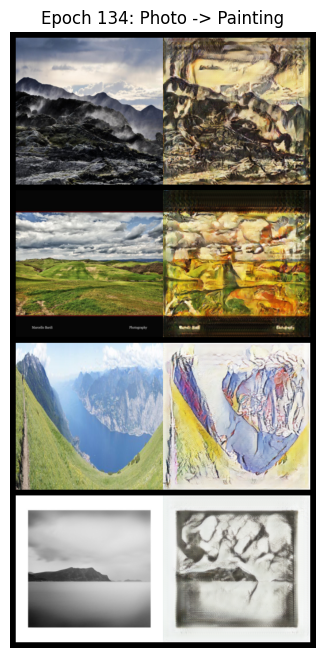

Epoch [133/150] Completed
  Generator Loss: 2.5650
  Cycle Consistency Loss: 0.1436
  Identity Loss: 0.1916
  Discriminator X Loss: 0.1934
  Discriminator Y Loss: 0.1366
Epoch [134/150]


Epoch [134/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.139, D_X_Loss=0.183, D_Y_Loss=0.146, Generator_Loss=2.58, Identity_Loss=0.223] 


Model parameters saved for epoch 134.


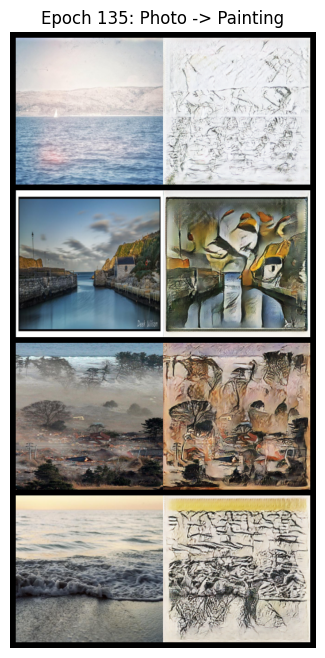

Epoch [134/150] Completed
  Generator Loss: 2.5735
  Cycle Consistency Loss: 0.1440
  Identity Loss: 0.1918
  Discriminator X Loss: 0.1938
  Discriminator Y Loss: 0.1325
Epoch [135/150]


Epoch [135/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.119, D_X_Loss=0.231, D_Y_Loss=0.06, Generator_Loss=2.43, Identity_Loss=0.181]   


Model parameters saved for epoch 135.


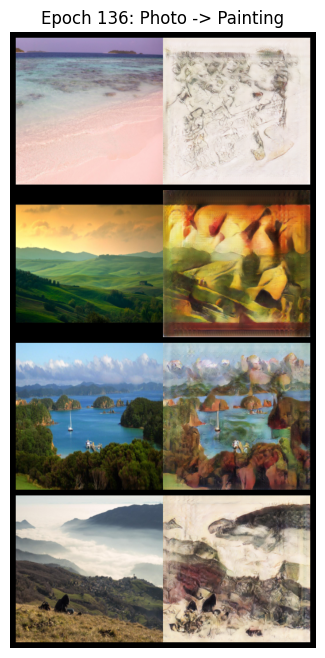

Epoch [135/150] Completed
  Generator Loss: 2.5615
  Cycle Consistency Loss: 0.1438
  Identity Loss: 0.1905
  Discriminator X Loss: 0.1942
  Discriminator Y Loss: 0.1359
Epoch [136/150]


Epoch [136/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.144, D_X_Loss=0.128, D_Y_Loss=0.155, Generator_Loss=2.51, Identity_Loss=0.192]  


Model parameters saved for epoch 136.


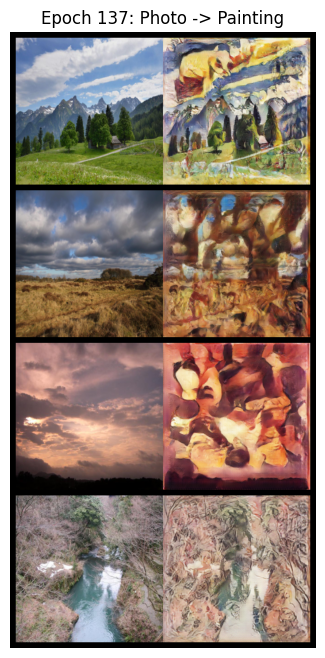

Epoch [136/150] Completed
  Generator Loss: 2.5628
  Cycle Consistency Loss: 0.1431
  Identity Loss: 0.1902
  Discriminator X Loss: 0.1952
  Discriminator Y Loss: 0.1352
Epoch [137/150]


Epoch [137/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.116, D_X_Loss=0.257, D_Y_Loss=0.241, Generator_Loss=2.11, Identity_Loss=0.162]  


Model parameters saved for epoch 137.


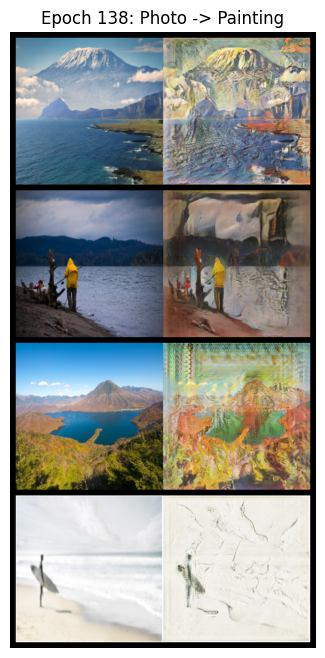

Epoch [137/150] Completed
  Generator Loss: 2.5570
  Cycle Consistency Loss: 0.1430
  Identity Loss: 0.1877
  Discriminator X Loss: 0.1943
  Discriminator Y Loss: 0.1362
Epoch [138/150]


Epoch [138/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.131, D_X_Loss=0.241, D_Y_Loss=0.101, Generator_Loss=2.5, Identity_Loss=0.177]  


Model parameters saved for epoch 138.


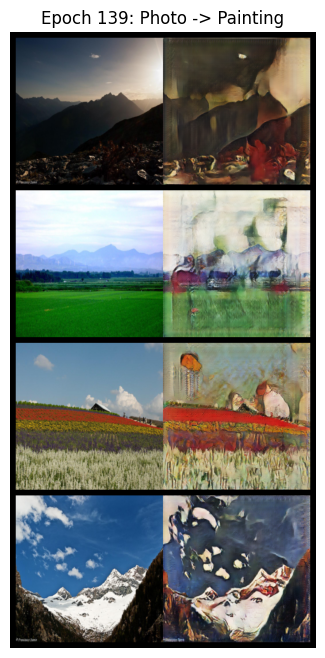

Epoch [138/150] Completed
  Generator Loss: 2.5432
  Cycle Consistency Loss: 0.1418
  Identity Loss: 0.1866
  Discriminator X Loss: 0.1959
  Discriminator Y Loss: 0.1354
Epoch [139/150]


Epoch [139/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.187, D_X_Loss=0.0865, D_Y_Loss=0.0699, Generator_Loss=3.32, Identity_Loss=0.211]


Model parameters saved for epoch 139.


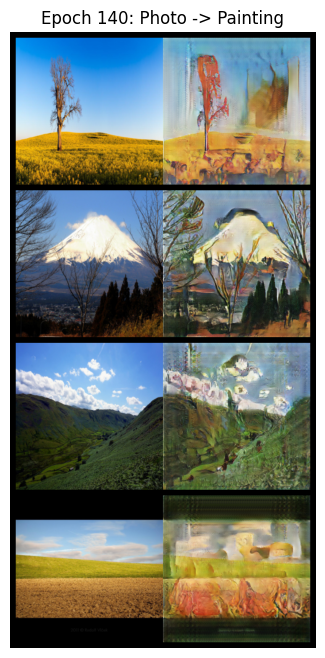

Epoch [139/150] Completed
  Generator Loss: 2.5440
  Cycle Consistency Loss: 0.1421
  Identity Loss: 0.1872
  Discriminator X Loss: 0.1944
  Discriminator Y Loss: 0.1375
Epoch [140/150]


Epoch [140/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.151, D_X_Loss=0.194, D_Y_Loss=0.173, Generator_Loss=2.72, Identity_Loss=0.167] 


Model parameters saved for epoch 140.


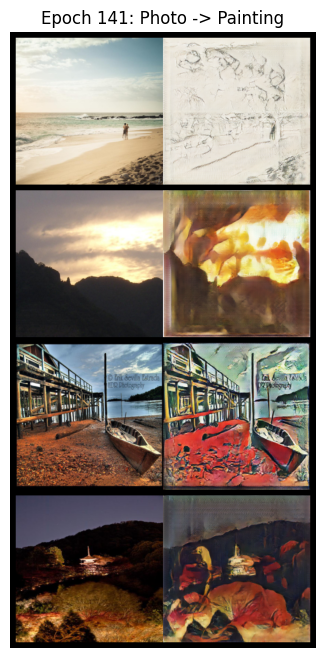

Epoch [140/150] Completed
  Generator Loss: 2.5832
  Cycle Consistency Loss: 0.1440
  Identity Loss: 0.1900
  Discriminator X Loss: 0.1888
  Discriminator Y Loss: 0.1339
Epoch [141/150]


Epoch [141/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.125, D_X_Loss=0.218, D_Y_Loss=0.084, Generator_Loss=2.48, Identity_Loss=0.263] 


Model parameters saved for epoch 141.


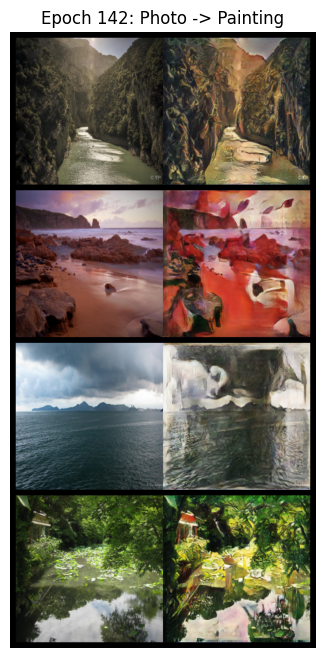

Epoch [141/150] Completed
  Generator Loss: 2.5273
  Cycle Consistency Loss: 0.1409
  Identity Loss: 0.1860
  Discriminator X Loss: 0.1971
  Discriminator Y Loss: 0.1369
Epoch [142/150]


Epoch [142/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.163, D_X_Loss=0.259, D_Y_Loss=0.0569, Generator_Loss=2.86, Identity_Loss=0.255]


Model parameters saved for epoch 142.


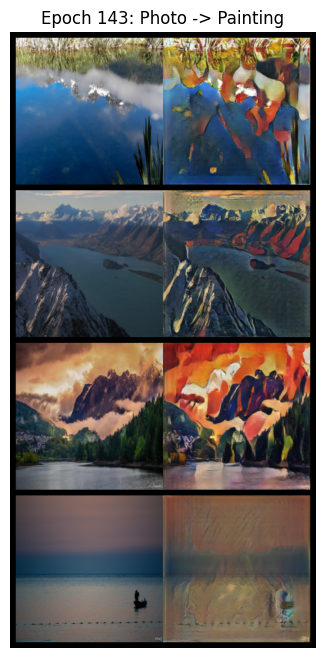

Epoch [142/150] Completed
  Generator Loss: 3.3901
  Cycle Consistency Loss: 0.1732
  Identity Loss: 0.2186
  Discriminator X Loss: 0.8376
  Discriminator Y Loss: 0.1253
Epoch [143/150]


Epoch [143/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.147, D_X_Loss=0.262, D_Y_Loss=0.0813, Generator_Loss=2.48, Identity_Loss=0.281]


Model parameters saved for epoch 143.


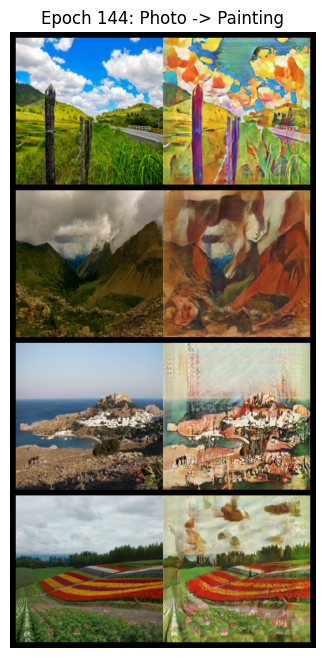

Epoch [143/150] Completed
  Generator Loss: 2.5482
  Cycle Consistency Loss: 0.1517
  Identity Loss: 0.2188
  Discriminator X Loss: 0.2710
  Discriminator Y Loss: 0.1282
Epoch [144/150]


Epoch [144/150]: 100%|██████████| 602/602 [09:29<00:00,  1.06it/s, Cycle_Loss=0.115, D_X_Loss=0.3, D_Y_Loss=0.185, Generator_Loss=1.98, Identity_Loss=0.154]   


Model parameters saved for epoch 144.


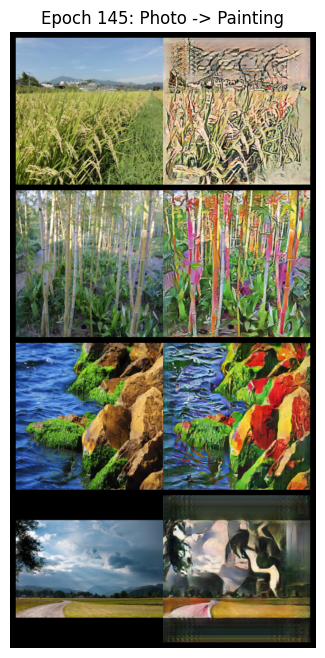

Epoch [144/150] Completed
  Generator Loss: 2.3373
  Cycle Consistency Loss: 0.1354
  Identity Loss: 0.1920
  Discriminator X Loss: 0.2593
  Discriminator Y Loss: 0.1348
Epoch [145/150]


Epoch [145/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.128, D_X_Loss=0.223, D_Y_Loss=0.121, Generator_Loss=2.23, Identity_Loss=0.129] 


Model parameters saved for epoch 145.


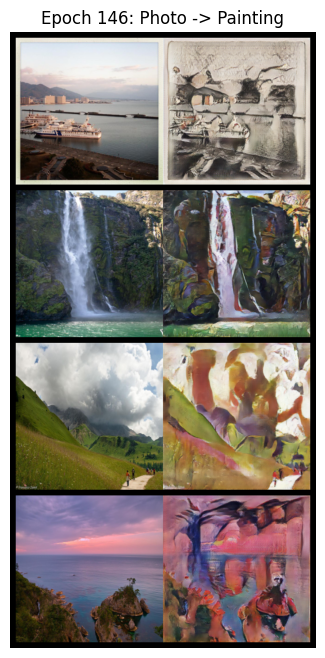

Epoch [145/150] Completed
  Generator Loss: 2.3008
  Cycle Consistency Loss: 0.1325
  Identity Loss: 0.1832
  Discriminator X Loss: 0.2588
  Discriminator Y Loss: 0.1367
Epoch [146/150]


Epoch [146/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.133, D_X_Loss=0.254, D_Y_Loss=0.246, Generator_Loss=1.91, Identity_Loss=0.156] 


Model parameters saved for epoch 146.


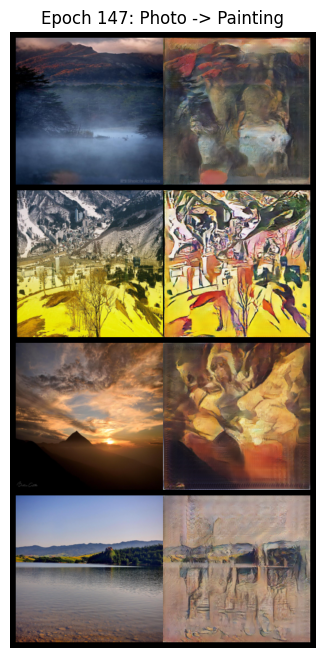

Epoch [146/150] Completed
  Generator Loss: 2.2898
  Cycle Consistency Loss: 0.1314
  Identity Loss: 0.1804
  Discriminator X Loss: 0.2569
  Discriminator Y Loss: 0.1385
Epoch [147/150]


Epoch [147/150]: 100%|██████████| 602/602 [09:28<00:00,  1.06it/s, Cycle_Loss=0.115, D_X_Loss=0.19, D_Y_Loss=0.184, Generator_Loss=2.59, Identity_Loss=0.268]  


Model parameters saved for epoch 147.


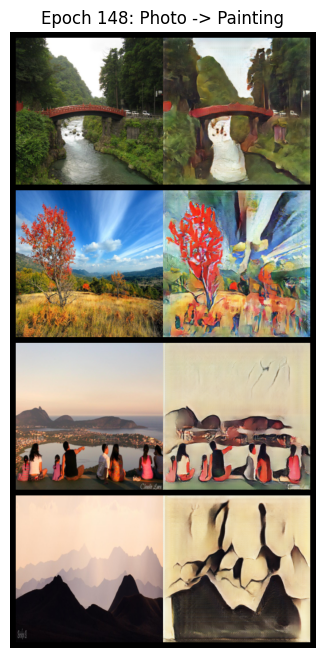

Epoch [147/150] Completed
  Generator Loss: 2.3518
  Cycle Consistency Loss: 0.1332
  Identity Loss: 0.1790
  Discriminator X Loss: 0.2334
  Discriminator Y Loss: 0.1351
Epoch [148/150]


Epoch [148/150]: 100%|██████████| 602/602 [09:40<00:00,  1.04it/s, Cycle_Loss=0.119, D_X_Loss=0.213, D_Y_Loss=0.106, Generator_Loss=2.09, Identity_Loss=0.166]  


Model parameters saved for epoch 148.


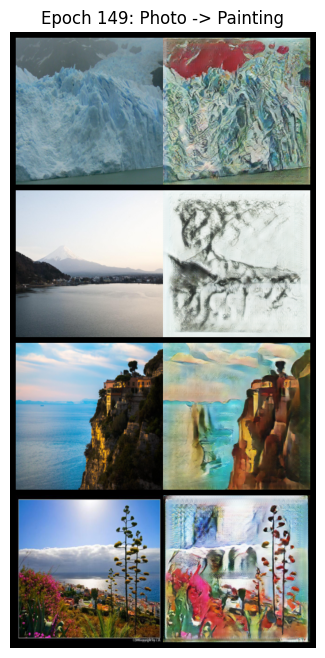

Epoch [148/150] Completed
  Generator Loss: 2.5026
  Cycle Consistency Loss: 0.1391
  Identity Loss: 0.1843
  Discriminator X Loss: 0.1826
  Discriminator Y Loss: 0.1378
Epoch [149/150]


Epoch [149/150]: 100%|██████████| 602/602 [09:41<00:00,  1.04it/s, Cycle_Loss=0.135, D_X_Loss=0.117, D_Y_Loss=0.0657, Generator_Loss=2.63, Identity_Loss=0.162] 


Model parameters saved for epoch 149.


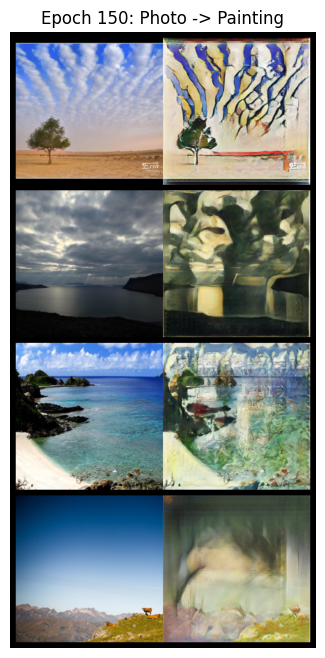

Epoch [149/150] Completed
  Generator Loss: 2.5231
  Cycle Consistency Loss: 0.1397
  Identity Loss: 0.1834
  Discriminator X Loss: 0.1799
  Discriminator Y Loss: 0.1357
Epoch [150/150]


Epoch [150/150]: 100%|██████████| 602/602 [09:31<00:00,  1.05it/s, Cycle_Loss=0.0984, D_X_Loss=0.164, D_Y_Loss=0.162, Generator_Loss=2, Identity_Loss=0.209]   


Model parameters saved for epoch 150.


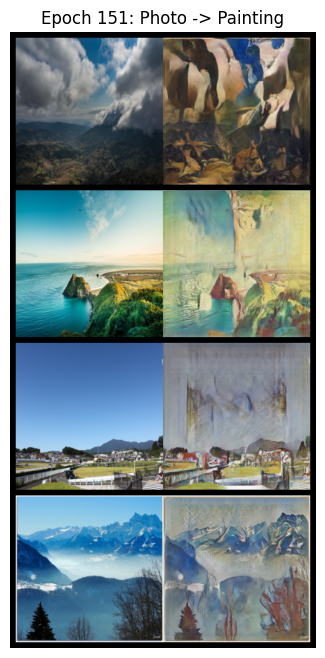

Epoch [150/150] Completed
  Generator Loss: 2.5415
  Cycle Consistency Loss: 0.1403
  Identity Loss: 0.1872
  Discriminator X Loss: 0.1831
  Discriminator Y Loss: 0.1335


In [18]:
import matplotlib.pyplot as plt
from tqdm import tqdm

resume_epoch = load_model_and_resume(epoch=50, G_X_to_Y=G_X_to_Y, G_Y_to_X=G_Y_to_X, D_X=D_X, D_Y=D_Y)

num_epochs = 150

losses = {
    "generator": [],
    "cycle": [],
    "identity": [],
    "discriminator_X": [],
    "discriminator_Y": []
}

for epoch in range(resume_epoch, num_epochs + 1):
    print(f"Epoch [{epoch}/{num_epochs}]")
    loop = tqdm(zip(landscape_loader, art_loader), leave=True, total=min(len(landscape_loader), len(art_loader)))

    epoch_loss_G = 0.0
    epoch_loss_cycle = 0.0
    epoch_loss_identity = 0.0
    epoch_loss_D_X = 0.0
    epoch_loss_D_Y = 0.0
    num_batches = 0

    for i, (real_landscape, real_art) in enumerate(loop):
        real_landscape = real_landscape.to(device)
        real_art = real_art.to(device)

        optimizer_G.zero_grad()

        fake_art = G_X_to_Y(real_landscape)  # Landscape -> Art
        fake_landscape = G_Y_to_X(real_art)  # Art -> Landscape

        cycled_landscape = G_Y_to_X(fake_art)  # Fake Art -> Landscape
        cycled_art = G_X_to_Y(fake_landscape)  # Fake Landscape -> Art

        identity_landscape = G_Y_to_X(real_landscape)  # Landscape -> Landscape
        identity_art = G_X_to_Y(real_art)  # Art -> Art

        loss_G_X_to_Y = adversarial_loss(D_Y(fake_art), torch.ones_like(D_Y(fake_art)))
        loss_G_Y_to_X = adversarial_loss(D_X(fake_landscape), torch.ones_like(D_X(fake_landscape)))

        loss_cycle = cycle_consistency_loss(real_landscape, cycled_landscape) + cycle_consistency_loss(real_art, cycled_art)
        loss_identity = identity_loss(real_landscape, identity_landscape) + identity_loss(real_art, identity_art)

        loss_G = loss_G_X_to_Y + loss_G_Y_to_X + lambda_cycle * loss_cycle + lambda_identity * loss_identity
        loss_G.backward()
        optimizer_G.step()

        optimizer_D_X.zero_grad()
        loss_D_X_real = adversarial_loss(D_X(real_landscape), torch.ones_like(D_X(real_landscape)))
        loss_D_X_fake = adversarial_loss(D_X(fake_landscape.detach()), torch.zeros_like(D_X(fake_landscape)))
        loss_D_X = (loss_D_X_real + loss_D_X_fake) * 0.5
        loss_D_X.backward()
        optimizer_D_X.step()

        optimizer_D_Y.zero_grad()
        loss_D_Y_real = adversarial_loss(D_Y(real_art), torch.ones_like(D_Y(real_art)))
        loss_D_Y_fake = adversarial_loss(D_Y(fake_art.detach()), torch.zeros_like(D_Y(fake_art)))
        loss_D_Y = (loss_D_Y_real + loss_D_Y_fake) * 0.5
        loss_D_Y.backward()
        optimizer_D_Y.step()

        epoch_loss_G += loss_G.item()
        epoch_loss_cycle += loss_cycle.item()
        epoch_loss_identity += loss_identity.item()
        epoch_loss_D_X += loss_D_X.item()
        epoch_loss_D_Y += loss_D_Y.item()
        num_batches += 1

        loop.set_description(f"Epoch [{epoch}/{num_epochs}]")
        loop.set_postfix(
            Generator_Loss=loss_G.item(),
            Cycle_Loss=loss_cycle.item(),
            Identity_Loss=loss_identity.item(),
            D_X_Loss=loss_D_X.item(),
            D_Y_Loss=loss_D_Y.item()
        )

    losses["generator"].append(epoch_loss_G / num_batches)
    losses["cycle"].append(epoch_loss_cycle / num_batches)
    losses["identity"].append(epoch_loss_identity / num_batches)
    losses["discriminator_X"].append(epoch_loss_D_X / num_batches)
    losses["discriminator_Y"].append(epoch_loss_D_Y / num_batches)

    save_model(epoch, G_X_to_Y, G_Y_to_X, D_X, D_Y)

    with torch.no_grad():
        sample_photos = next(iter(landscape_loader))
        visualize_progress(G_X_to_Y, sample_photos, epoch + 1)


    print(f"Epoch [{epoch}/{num_epochs}] Completed")
    print(f"  Generator Loss: {losses['generator'][-1]:.4f}")
    print(f"  Cycle Consistency Loss: {losses['cycle'][-1]:.4f}")
    print(f"  Identity Loss: {losses['identity'][-1]:.4f}")
    print(f"  Discriminator X Loss: {losses['discriminator_X'][-1]:.4f}")
    print(f"  Discriminator Y Loss: {losses['discriminator_Y'][-1]:.4f}")


In [38]:
def generate_and_save_outputs(generator, input_loader, save_dir="generated_outputs"):
    os.makedirs(save_dir, exist_ok=True)
    generator.eval()  

    with torch.no_grad():
        for idx, input_images in enumerate(input_loader):
            input_images = input_images.to(device)

            generated_images = generator(input_images)

            unnormalize = transforms.Normalize(mean=[-0.5 / 0.5, -0.5 / 0.5, -0.5 / 0.5], std=[1 / 0.5, 1 / 0.5, 1 / 0.5])
            input_images = [unnormalize(img).clamp(0, 1) for img in input_images]
            generated_images = [unnormalize(img).clamp(0, 1) for img in generated_images]

            for i, (input_img, gen_img) in enumerate(zip(input_images, generated_images)):
                input_img = transforms.ToPILImage()(input_img.cpu())
                gen_img = transforms.ToPILImage()(gen_img.cpu())
                gen_img = upscale_image(gen_img)
                gen_img.save(f"{save_dir}/generated_{idx * input_loader.batch_size + i + 1}.jpg")

    print(f"All outputs saved to {save_dir}.")


In [67]:
output_image_path = r"E:\Code\GAN\rank\101cub" 
input_path = r"E:\Code\GAN\input"
input_dataset = ArtDataset(input_path, transform=transform)
input_loader = torch.utils.data.DataLoader(input_dataset, batch_size=BATCH_SIZE, shuffle=False)

generate_and_save_outputs(generator=G_X_to_Y, input_loader=input_loader, save_dir=output_image_path)

All outputs saved to E:\Code\GAN\rank\101cub.
